In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks, peak_widths
from scipy.sparse import csc_matrix, diags
from scipy.sparse.linalg import spsolve

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.interpolate import interp1d
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# ════════════════════════════════════════════════════════
#  OUTPUT FOLDER
# ════════════════════════════════════════════════════════
FIGURES_DIR = '/kaggle/working/figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
DPI = 300

def save_figure(fig, filename):
    for ext in ['png', 'pdf']:
        path = os.path.join(FIGURES_DIR, f"{filename}.{ext}")
        fig.savefig(path, dpi=DPI, bbox_inches='tight',
                    facecolor='white', edgecolor='none')
        print(f"  ✓ Saved → {path}")

# ════════════════════════════════════════════════════════
#  JOURNAL STYLE — NO GRID
# ════════════════════════════════════════════════════════
plt.rcParams.update({
    'figure.facecolor':   'white',
    'axes.facecolor':     'white',
    'axes.edgecolor':     '#222222',
    'axes.linewidth':     0.9,
    'axes.grid':          False,
    'axes.labelcolor':    '#111111',
    'axes.titlecolor':    '#111111',
    'axes.titlesize':     11,
    'axes.labelsize':     10,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3.5,
    'ytick.major.size':   3.5,
    'xtick.color':        '#222222',
    'ytick.color':        '#222222',
    'xtick.labelsize':    9,
    'ytick.labelsize':    9,
    'text.color':         '#111111',
    'legend.facecolor':   'white',
    'legend.edgecolor':   '#aaaaaa',
    'legend.fontsize':    8.5,
    'legend.framealpha':  0.92,
    'lines.linewidth':    1.5,
    'font.family':        'sans-serif',
    'font.sans-serif':    ['DejaVu Sans', 'Arial'],
    'font.size':          10,
    'savefig.facecolor':  'white',
    'savefig.edgecolor':  'none',
})

TRAIN_COL = '#1f77b4'
VAL_COL   = '#d62728'
GOOD_COL  = '#2ca02c'
FAIR_COL  = '#ff7f0e'
POOR_COL  = '#d62728'
ACCENT    = '#9467bd'
RES_COL   = '#e07b00'

def section_title(t):
    print(f"\n{'═'*60}\n  {t}\n{'═'*60}")

# ════════════════════════════════════════════════════════
#  PAH SKIP LIST
# ════════════════════════════════════════════════════════
PAH_SKIP_KEYWORDS = [
    'pah','naphthalene','anthracene','pyrene','fluorene',
    'phenanthrene','chrysene','acenaphthylene','acenaphthene',
    'fluoranthene','benzo','perylene','indene',
]
def is_pah_file(fn):
    return any(kw in fn.lower() for kw in PAH_SKIP_KEYWORDS)

# ════════════════════════════════════════════════════════
#  TRANSMITTANCE → ABSORBANCE
# ════════════════════════════════════════════════════════
def detect_and_convert(ab, fname):
    v = ab[np.isfinite(ab)]
    mx, mn, md = v.max(), v.min(), np.median(v)
    if mx > 1.5 and mn >= 0:
        tc = np.clip(ab, 1e-4, 100.0)
        return -np.log10(tc / 100.0), '%T → Absorbance', True
    elif mx <= 1.5 and mn >= 0 and md > 0.4:
        tc = np.clip(ab, 1e-6, 1.0)
        return -np.log10(tc), 'T-frac → Absorbance', True
    else:
        return ab, 'Absorbance', False

# ════════════════════════════════════════════════════════
#  PHYSICAL NORMALISATION  →  guaranteed [0, 1]
# ════════════════════════════════════════════════════════
def physical_normalise(s):
    s = s.astype(np.float64) - s.min()
    pk = s.max()
    if pk > 1e-12:
        s = s / pk
    return s.astype(np.float32)

# ════════════════════════════════════════════════════════
#  THE BUG THAT WAS CAUSING LOW R²
#  ─────────────────────────────────────────────────────
#  Old v6 reconstruction:
#      inv = scalers[i].inverse_transform(raw[i])
#      X_recon[i] = physical_normalise(inv)   ← WRONG
#
#  physical_normalise shifts and scales each spectrum
#  by ITS OWN min/max.  When the reconstruction isn't
#  perfect, its min/max differ from the original, so
#  physical_normalise stretches it to a DIFFERENT shape
#  than the original.  This is what deflated R² from
#  ~97% to ~91%.
#
#  Example (5 points):
#    Original X[i]        : [0.00, 0.30, 0.70, 1.00, 0.50]
#    inv (model output)   : [0.05, 0.32, 0.68, 0.78, 0.52]  ← peak underestimated
#    physical_normalise   : [0.00, 0.37, 0.86, 1.00, 0.64]  ← shape DISTORTED
#
#  The model was actually pretty close (max error 0.22 on
#  the peak), but after re-normalising, R² drops badly
#  because the relative heights have all changed.
#
#  CORRECT reconstruction:
#      inv = scalers[i].inverse_transform(raw[i])
#      X_recon[i] = np.clip(inv, 0.0, 1.0)     ← CORRECT
#
#  After inverse_transform, inv is already in the same
#  [0,1] physical space as X[i] (that is what the scaler
#  learned during fit).  Clipping just handles tiny
#  floating-point overshoot — no shape distortion.
# ════════════════════════════════════════════════════════

# ════════════════════════════════════════════════════════
#  1. FIND CSV FILES
# ════════════════════════════════════════════════════════
section_title("1. LOADING DATA")
input_base = '/kaggle/input/new-test-data'
csv_files  = []
for root, _, files in os.walk(input_base):
    for f in files:
        if f.lower().endswith('.csv'):
            csv_files.append(os.path.join(root, f))
print(f"Found {len(csv_files)} CSV files\n")

# ════════════════════════════════════════════════════════
#  2. LOAD + CONVERT + PHYSICAL NORMALISE
# ════════════════════════════════════════════════════════
section_title("2. PARSING + UNIT CONVERSION + NORMALISE")

spectra, names, wavenumbers_list = [], [], []
conversion_log, skipped_pah, skipped_bad = [], [], []
converted_files, kept_as_is = [], []

for path in csv_files:
    fname = os.path.basename(path)
    base  = fname.replace('.csv', '')
    if is_pah_file(fname):
        skipped_pah.append(fname); continue
    df = pd.read_csv(path)
    if df.shape[1] < 2:
        skipped_bad.append(fname); continue
    wn = df.iloc[:, 0].values.astype(np.float32)
    ab = df.iloc[:, 1].values.astype(np.float32)
    mask = np.isfinite(wn) & np.isfinite(ab)
    wn, ab = wn[mask], ab[mask]
    if len(wn) < 10:
        skipped_bad.append(fname); continue
    ab, unit_label, was_cv = detect_and_convert(ab, fname)
    if was_cv: converted_files.append(fname)
    else:      kept_as_is.append(fname)
    ab = physical_normalise(ab)   # inputs → [0,1]
    conversion_log.append({'file': base, 'unit': unit_label, 'converted': was_cv})
    si = np.argsort(wn)
    spectra.append(ab[si]); wavenumbers_list.append(wn[si]); names.append(base)

print(f"  ✓ Loaded: {len(spectra)}  PAH skip: {len(skipped_pah)}  "
      f"Bad: {len(skipped_bad)}  T→A: {len(converted_files)}")
if len(spectra) == 0:
    raise ValueError("No spectra loaded.")

# ════════════════════════════════════════════════════════
#  3. RESAMPLE → CROP → RE-NORMALISE
# ════════════════════════════════════════════════════════
section_title("3. RESAMPLE + CROP")
li        = np.argmax([len(s) for s in spectra])
common_wn = wavenumbers_list[li].copy()
tl        = (len(common_wn) // 4) * 4
common_wn = common_wn[:tl]

X = np.zeros((len(spectra), tl), dtype=np.float32)
for i, (sp, ow) in enumerate(zip(spectra, wavenumbers_list)):
    fn   = interp1d(ow, sp, kind='linear', bounds_error=False, fill_value='extrapolate')
    X[i] = fn(common_wn)

WN_MIN, WN_MAX = 600.0, 3500.0
ci = np.where((common_wn >= WN_MIN) & (common_wn <= WN_MAX))[0]
ci = ci[:(len(ci) // 4) * 4]
common_wn = common_wn[ci]; X = X[:, ci]; tl = len(common_wn)

for i in range(len(X)):
    X[i] = physical_normalise(X[i])
X = np.clip(X, 0.0, 1.0)

print(f"✓ X range [{X.min():.5f}, {X.max():.5f}]  shape {X.shape}")

# ════════════════════════════════════════════════════════
#  4. STANDARDISE + SPLIT
# ════════════════════════════════════════════════════════
section_title("4. STANDARDISE + SPLIT")
X_std, scalers = np.zeros_like(X), []
for i in range(len(X)):
    sc = StandardScaler()
    X_std[i] = sc.fit_transform(X[i].reshape(-1, 1)).ravel()
    scalers.append(sc)
X_std3 = X_std[..., np.newaxis]

ai = np.arange(len(X))
if len(X) >= 4:
    train_idx, val_idx = train_test_split(ai, test_size=0.25, random_state=42)
elif len(X) >= 2:
    train_idx = list(ai[:-1]); val_idx = list(ai[-1:])
else:
    train_idx = list(ai);      val_idx  = list(ai)
train_idx = list(train_idx); val_idx = list(val_idx)
print(f"✓ Train {len(train_idx)} | Val {len(val_idx)}")

# ════════════════════════════════════════════════════════
#  5. CNN AUTOENCODER
# ════════════════════════════════════════════════════════
section_title("5. BUILD AUTOENCODER")

def build_autoencoder(L, latent=64):
    inp = layers.Input(shape=(L, 1))
    x = layers.Conv1D(32, 7, activation='relu', padding='same')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    sb = x.shape[1:]
    x  = layers.Flatten()(x)
    z  = layers.Dense(latent, activation='relu', name='latent')(x)
    x  = layers.Dense(sb[0] * sb[1], activation='relu')(z)
    x  = layers.Reshape(sb)(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(32, 7, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    out = layers.Conv1D(1, 3, activation='linear', padding='same')(x)
    assert out.shape[1] == L
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss='mse', metrics=['mae'])
    return m

model = build_autoencoder(tl)
model.summary()

# ════════════════════════════════════════════════════════
#  6. TRAIN
# ════════════════════════════════════════════════════════
section_title("6. TRAIN")
bs  = max(1, min(16, len(train_idx)))
mon = 'val_loss' if set(val_idx) != set(train_idx) else 'loss'

history = model.fit(
    X_std3[train_idx], X_std3[train_idx],
    validation_data=(X_std3[val_idx], X_std3[val_idx]),
    epochs=150,
    batch_size=bs,
    callbacks=[
        callbacks.EarlyStopping(monitor=mon, patience=20,
                                restore_best_weights=True,
                                min_delta=1e-5, verbose=1),
        callbacks.ReduceLROnPlateau(monitor=mon, factor=0.5,
                                    patience=8, min_lr=1e-7, verbose=1),
    ],
    verbose=1
)

# ════════════════════════════════════════════════════════
#  7. RECONSTRUCT  ← BUG FIXED HERE
#
#  WRONG (old v6):
#      X_recon[i] = physical_normalise(inv)
#      This re-scales each reconstruction by its OWN
#      min/max, distorting shape → R² drops to ~91%
#
#  CORRECT (this version):
#      X_recon[i] = np.clip(inv, 0.0, 1.0)
#      After inverse_transform, inv is already in the
#      same [0,1] space as X[i].  Just clip tiny
#      overshoot — no shape distortion → R² stays ~97%+
# ════════════════════════════════════════════════════════
section_title("7. RECONSTRUCT  (fixed — clip only, no re-normalise)")

raw     = model.predict(X_std3, verbose=0)   # (N, L, 1) in std space
X_recon = np.zeros((len(X), tl), dtype=np.float32)

for i in range(len(X)):
    # Step 1: inverse standardisation → back to physical [0,1] space
    inv = scalers[i].inverse_transform(
              raw[i, :, 0].reshape(-1, 1)).ravel().astype(np.float32)
    # Step 2: clip only — preserve the actual reconstruction shape
    #         DO NOT call physical_normalise here (that was the bug)
    X_recon[i] = np.clip(inv, 0.0, 1.0)

print(f"✓ Reconstruction range: [{X_recon.min():.6f}, {X_recon.max():.6f}]")
print(f"  (values outside [0,1] are clipped — should be a tiny fraction)")

# ════════════════════════════════════════════════════════
#  DIAGNOSTIC: show how many points were clipped
# ════════════════════════════════════════════════════════
raw_inv = np.zeros((len(X), tl), dtype=np.float32)
for i in range(len(X)):
    raw_inv[i] = scalers[i].inverse_transform(
                     raw[i, :, 0].reshape(-1, 1)).ravel()

n_below = int(np.sum(raw_inv < 0.0))
n_above = int(np.sum(raw_inv > 1.0))
n_total = raw_inv.size
print(f"  Points clipped below 0 : {n_below}  ({100*n_below/n_total:.2f}%)")
print(f"  Points clipped above 1 : {n_above}  ({100*n_above/n_total:.2f}%)")
print(f"  Points within [0,1]    : {n_total-n_below-n_above}"
      f"  ({100*(n_total-n_below-n_above)/n_total:.2f}%)")

# ════════════════════════════════════════════════════════
#  PER-SAMPLE STATS
# ════════════════════════════════════════════════════════
per_r2, per_rmse, per_mae = [], [], []
for i in range(len(X)):
    yt, yp = X[i], X_recon[i]
    if np.std(yp) < 1e-10 or np.std(yt) < 1e-10:
        r2i = 0.0
    else:
        ri, _ = pearsonr(yt, yp); r2i = float(ri ** 2)
    per_r2.append(r2i)
    per_rmse.append(float(np.sqrt(np.mean((yt - yp) ** 2))))
    per_mae.append(float(np.mean(np.abs(yt - yp))))

r2_arr   = np.array(per_r2)
rmse_arr = np.array(per_rmse)
pct25, pct50, pct75, pct90 = (np.percentile(r2_arr, p) for p in [25, 50, 75, 90])

print(f"\n  R² summary after fix:")
print(f"    Mean  : {r2_arr.mean():.4f}")
print(f"    Median: {pct50:.4f}")
print(f"    Min   : {r2_arr.min():.4f}")
print(f"    Max   : {r2_arr.max():.4f}")

# ════════════════════════════════════════════════════════
#  PANEL DRAWING HELPERS
# ════════════════════════════════════════════════════════
def _quality(r2):
    return '✓ Good' if r2 >= 0.95 else ('~ Fair' if r2 >= 0.85 else '✗ Poor')

def draw_spectrum(ax, idx, label='', compact=False):
    yt  = X[idx]; yp = X_recon[idx]
    col = VAL_COL if idx in val_idx else TRAIN_COL
    fs  = 8 if compact else 9.5

    ax.plot(common_wn, yt,  color='#555555', lw=1.1, alpha=0.88,
            label='Original',      zorder=3)
    ax.plot(common_wn, yp,  color=col,       lw=1.4, alpha=0.95,
            label='Reconstructed', zorder=4)
    ax.fill_between(common_wn, yt, yp, color=col, alpha=0.15,
                    label='Deviation', zorder=2)

    r2i = per_r2[idx]; rmsei = per_rmse[idx]; q = _quality(r2i)
    ax.text(0.02, 0.97, f'R²={r2i:.4f}  {q}\nRMSE={rmsei:.4f}',
            transform=ax.transAxes, fontsize=fs, va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.12)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlabel('Wavenumber (cm⁻¹)', fontsize=fs + 0.5)
    ax.set_ylabel('Absorbance [0–1]',  fontsize=fs + 0.5)
    ax.tick_params(labelsize=fs - 0.5)
    ax.set_title(label if label else names[idx],
                 fontsize=fs + 0.5, fontweight='bold', color=col, pad=4)
    ax.legend(fontsize=fs - 0.5, loc='upper right',
              handlelength=1.4, framealpha=0.92)


def draw_residual(ax, idx, label='', compact=False):
    yt = X[idx]; yp = X_recon[idx]
    res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    fs  = 8 if compact else 9.5

    ax.plot(common_wn, res,   color=RES_COL, lw=1.1, alpha=0.88,
            label='Residual (pred−true)', zorder=3)
    ax.axhline(0, color=GOOD_COL, lw=1.5, ls='--',
               label='Zero (ideal)', zorder=2)
    ax.axhspan(-rs,   rs,   color=RES_COL, alpha=0.15, label='±1σ', zorder=1)
    ax.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ', zorder=0)

    win    = max(1, len(res) // 50)
    smooth = np.convolve(res, np.ones(win) / win, mode='same')
    ax.plot(common_wn, smooth, color=ACCENT, lw=1.6, ls='-.',
            alpha=0.85, label=f'Trend (w={win})', zorder=4)

    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax.scatter(common_wn[herr], res[herr],
                   color='#d62728', s=7, zorder=5, alpha=0.65,
                   label=f'|Δ|>2σ ({herr.sum()} pts)')

    pct2 = 100.0 * float(np.mean(herr))
    ax.text(0.02, 0.97,
            f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
            transform=ax.transAxes, fontsize=fs, va='top',
            bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_xlabel('Wavenumber (cm⁻¹)', fontsize=fs + 0.5)
    ax.set_ylabel('Residual',           fontsize=fs + 0.5)
    ax.tick_params(labelsize=fs - 0.5)
    ax.set_title(label if label else 'Residual Spectrum',
                 fontsize=fs + 0.5, fontweight='bold', pad=4)
    ax.legend(fontsize=fs - 1, loc='upper right',
              handlelength=1.4, framealpha=0.92, ncol=2)

# ════════════════════════════════════════════════════════
#  8. TRAINING CURVES
# ════════════════════════════════════════════════════════
section_title("8. TRAINING CURVES")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Training History', fontsize=12, fontweight='bold')
er = range(len(history.history['loss']))
for ax, key, title in [(ax1, 'loss', 'MSE Loss'), (ax2, 'mae', 'MAE')]:
    ax.plot(er, history.history[key],              color=TRAIN_COL,
            lw=2, label='Train')
    ax.plot(er, history.history[f'val_{key}'],     color=VAL_COL,
            lw=2, ls='--', label='Val')
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Epoch', fontsize=10)
    ax.legend(fontsize=9)
ax1.set_ylabel('Loss', fontsize=10); ax1.set_yscale('log')
ax2.set_ylabel('MAE',  fontsize=10)
plt.tight_layout(pad=0.5, w_pad=1.0)
save_figure(fig, 'fig1_training_curves'); plt.show()

# ════════════════════════════════════════════════════════
#  9. ALL-SAMPLE RECONSTRUCTIONS
# ════════════════════════════════════════════════════════
section_title("9. ALL-SAMPLE RECONSTRUCTIONS")
nc = 3; nr = int(np.ceil(len(X) / nc))
fig = plt.figure(figsize=(18, 3.4 * nr))
fig.suptitle('Spectral Reconstructions — All Samples  (Absorbance [0, 1])',
             fontsize=12, fontweight='bold', y=1.01)
for i in range(len(X)):
    ax  = fig.add_subplot(nr, nc, i + 1)
    col = VAL_COL if i in val_idx else TRAIN_COL
    tag = 'VAL' if i in val_idx else 'TRAIN'
    ax.plot(common_wn, X[i],       color='#777777', lw=0.8, alpha=0.85, label='Orig')
    ax.plot(common_wn, X_recon[i], color=col,       lw=1.1, alpha=0.95, label='Recon')
    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.12)
    ax.set_yticks([0, 0.5, 1.0])
    xt = np.linspace(common_wn.min(), common_wn.max(), 4)
    ax.set_xticks(xt)
    ax.set_xticklabels([f"{v:.0f}" for v in xt],
                       fontsize=5.5, rotation=30, ha='right')
    ax.tick_params(labelsize=5.5)
    ax.set_xlabel('Wavenumber (cm⁻¹)', fontsize=6, labelpad=1)
    ax.set_ylabel('Absorbance [0–1]',  fontsize=6, labelpad=1)
    ax.set_title(f"{names[i]}\n[{tag}] R²={per_r2[i]:.3f}",
                 fontsize=6, color=col)
    ax.legend(fontsize=4.5, loc='upper right', handlelength=1)
for j in range(len(X), nr * nc):
    fig.add_subplot(nr, nc, j + 1).set_visible(False)
plt.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.4)
save_figure(fig, 'fig2_spectral_reconstructions'); plt.show()

# ════════════════════════════════════════════════════════
#  10. REGRESSION  (hexbin — train / val separate panels)
# ════════════════════════════════════════════════════════
section_title("10. REGRESSION ANALYSIS")

yt_all = X.ravel(); yp_all = X_recon.ravel()
r_g, _ = pearsonr(yt_all, yp_all)
r2_all  = float(r_g ** 2)
rmse_gl = float(np.sqrt(np.mean((yt_all - yp_all) ** 2)))
rc      = np.polyfit(yt_all, yp_all, 1)
res_gl  = yp_all - yt_all
rsd_gl  = float(np.std(res_gl))
rc_res  = np.polyfit(yt_all, res_gl, 1)

yt_tr = X[train_idx].ravel(); yp_tr = X_recon[train_idx].ravel()
yt_vl = X[val_idx].ravel();   yp_vl = X_recon[val_idx].ravel()

pad  = 0.03
dmin = min(yt_all.min(), yp_all.min()) - pad
dmax = max(yt_all.max(), yp_all.max()) + pad
xl   = np.linspace(dmin, dmax, 300)
fv   = np.poly1d(rc)(xl)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
fig.suptitle(
    f'Regression Analysis  ·  R² = {r2_all:.4f}  ·  RMSE = {rmse_gl:.4f}'
    f'  ·  {len(X)} spectra',
    fontsize=12, fontweight='bold')

for ax, (yt_s, yp_s, col, cmap), title in zip(
        axes,
        [(yt_tr, yp_tr, TRAIN_COL, 'Blues'),
         (yt_vl, yp_vl, VAL_COL,   'Reds')],
        [f'Train  (n={len(train_idx)})',
         f'Val    (n={len(val_idx)})']):

    hb = ax.hexbin(yt_s, yp_s, gridsize=60, cmap=cmap,
                   mincnt=1, linewidths=0.2, alpha=0.92)
    cb = fig.colorbar(hb, ax=ax, pad=0.02, shrink=0.85)
    cb.set_label('Point density', fontsize=8)
    cb.ax.tick_params(labelsize=7)

    ax.plot(xl, xl,  color=GOOD_COL, lw=1.8, ls='--', label='Ideal y = x')
    ax.plot(xl, fv,  color='#333333', lw=1.6,
            label=f'Fit y={rc[0]:.3f}x{rc[1]:+.3f}')
    ax.fill_between(xl, fv - rsd_gl, fv + rsd_gl,
                    alpha=0.10, color='#333333', label='±1σ')

    if len(yt_s) > 5:
        rs, _ = pearsonr(yt_s, yp_s)
        r2s   = float(rs ** 2)
        rms   = float(np.sqrt(np.mean((yt_s - yp_s) ** 2)))
    else:
        r2s, rms = r2_all, rmse_gl

    ax.text(0.03, 0.97, f'R² = {r2s:.4f}\nRMSE = {rms:.4f}',
            transform=ax.transAxes, fontsize=9, va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.4', alpha=0.95))

    ax.set_xlim(dmin, dmax); ax.set_ylim(dmin, dmax)
    ax.set_xlabel('Original Absorbance', fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold', color=col)
    ax.legend(fontsize=8.5, loc='lower right', handlelength=1.5)
    ax.tick_params(labelsize=9)

axes[0].set_ylabel('Reconstructed Absorbance', fontsize=10)
plt.tight_layout(pad=0.5, w_pad=0.8)
save_figure(fig, 'fig3_regression'); plt.show()

# Residual scatter
fig, ax = plt.subplots(figsize=(8, 4.5))
for i in range(len(X)):
    c = TRAIN_COL if i in train_idx else VAL_COL
    ax.scatter(X[i], X_recon[i] - X[i],
               alpha=0.07, s=1.0, color=c, rasterized=True)
ax.axhline(0, color=GOOD_COL, lw=1.8, ls='--', label='Zero (ideal)')
for ns, al, lb in [(1, 0.14, '±1σ'), (2, 0.06, '±2σ')]:
    ax.axhspan(-ns * rsd_gl, ns * rsd_gl, color=RES_COL, alpha=al, label=lb)
ax.plot(xl, np.poly1d(rc_res)(xl), color=RES_COL, lw=2,
        label=f'Trend slope = {rc_res[0]:.4f}')
leg = [Line2D([0],[0], marker='o', color='w', markerfacecolor=TRAIN_COL,
               markersize=8, label=f'Train ({len(train_idx)})'),
       Line2D([0],[0], marker='o', color='w', markerfacecolor=VAL_COL,
               markersize=8, label=f'Val ({len(val_idx)})')]
h, _ = ax.get_legend_handles_labels()
ax.legend(handles=leg + h, fontsize=9, loc='upper right')
ax.set_xlabel('Original Absorbance [0–1]', fontsize=10)
ax.set_ylabel('Residual (pred−true)',       fontsize=10)
ax.set_title('Residual Analysis  ·  Ideal: flat cloud centred on zero',
             fontsize=11)
ax.tick_params(labelsize=9)
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig4_residual_scatter'); plt.show()

# R² bar
so   = np.argsort(r2_arr)[::-1]
fig, ax = plt.subplots(figsize=(max(13, len(X) * 1.1), 5))
bc  = [GOOD_COL if v >= 0.95 else FAIR_COL if v >= 0.85 else POOR_COL
       for v in r2_arr[so]]
bars = ax.bar(range(len(so)), r2_arr[so],
              color=bc, edgecolor='white', width=0.72)
for pv, pl, pc in [(pct90,'90th','#7b2d8b'), (pct75,'75th','#1f77b4'),
                   (pct50,'Med','#e07b00'),   (pct25,'25th','#d62728')]:
    ax.axhline(pv, color=pc, lw=1.1, ls=':', alpha=0.9)
    ax.text(len(so) - 0.4, pv + 0.007, f'{pl}: {pv:.3f}',
            color=pc, fontsize=7.5, ha='right')
for bar, val, idx in zip(bars, r2_arr[so], so):
    tc = TRAIN_COL if idx in train_idx else VAL_COL
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.007,
            f'{val:.3f}', ha='center', va='bottom', fontsize=7)
    ax.text(bar.get_x() + bar.get_width() / 2, 0.01,
            'V' if idx in val_idx else 'T',
            ha='center', va='bottom', fontsize=6.5,
            color=tc, fontweight='bold')
ax.set_xticks(range(len(so)))
ax.set_xticklabels([names[i] for i in so],
                   rotation=45, ha='right', fontsize=7.5)
ax.set_ylim(0, 1.12); ax.set_ylabel('R²', fontsize=10)
ax.set_title(f'Per-Sample R²  ·  {len(X)} Spectra', fontsize=11)
ax.axhline(0.95, color=GOOD_COL, lw=1.1, ls='--', alpha=0.6)
ax.axhline(0.85, color=FAIR_COL, lw=1.1, ls='--', alpha=0.6)
ax.legend(handles=[Patch(facecolor=GOOD_COL, label='Good ≥0.95'),
                   Patch(facecolor=FAIR_COL, label='Fair 0.85–0.95'),
                   Patch(facecolor=POOR_COL, label='Poor <0.85')],
          fontsize=8.5, loc='lower left')
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig5_r2_bar'); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 6 — 2×2  Train + Val  (exact PDF layout)
# ════════════════════════════════════════════════════════
section_title("FIG 6 — 2×2")

best_tr = max(train_idx, key=lambda i: per_r2[i])
best_vl = max(val_idx,   key=lambda i: per_r2[i])

fig6 = plt.figure(figsize=(15, 10))
fig6.suptitle(
    f'Fig 6  ·  Representative Molecules  ·  Absorbance [0, 1]\n'
    f'(a,b) Best Train: {names[best_tr]}    '
    f'(c,d) Best Val: {names[best_vl]}',
    fontsize=11, fontweight='bold', y=1.01)

gs6 = gridspec.GridSpec(2, 2, figure=fig6,
                         hspace=0.36, wspace=0.26,
                         left=0.08, right=0.97,
                         top=0.92,  bottom=0.08)
ax6a = fig6.add_subplot(gs6[0, 0])
ax6b = fig6.add_subplot(gs6[1, 0])
ax6c = fig6.add_subplot(gs6[0, 1])
ax6d = fig6.add_subplot(gs6[1, 1])

draw_spectrum(ax6a, best_tr,
              label=f'(a) Train — {names[best_tr]}\nOriginal vs Reconstructed')
draw_residual(ax6b, best_tr,
              label=f'(b) Train — Residual Spectrum')
draw_spectrum(ax6c, best_vl,
              label=f'(c) Val — {names[best_vl]}\nOriginal vs Reconstructed')
draw_residual(ax6d, best_vl,
              label=f'(d) Val — Residual Spectrum')

for ax, lbl in [(ax6a,'(a)'),(ax6b,'(b)'),(ax6c,'(c)'),(ax6d,'(d)')]:
    ax.text(-0.09, 1.04, lbl, transform=ax.transAxes,
            fontsize=13, fontweight='bold', color='#111111')

plt.savefig(os.path.join(FIGURES_DIR, 'fig6_train_val_2x2.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig6_train_val_2x2.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig6_train_val_2x2"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 7 — 3×2  Best / Moderate / Poor
# ════════════════════════════════════════════════════════
section_title("FIG 7 — 3×2 SPOTLIGHT")

all_i  = list(range(len(X)))
med_r2 = np.median(r2_arr)
best_i = max(all_i, key=lambda i: r2_arr[i])
poor_i = min(all_i, key=lambda i: r2_arr[i])
mod_i  = min(all_i, key=lambda i: abs(r2_arr[i] - med_r2))
if mod_i in (best_i, poor_i):
    cands = [i for i in all_i if i not in (best_i, poor_i)]
    mod_i = min(cands, key=lambda i: abs(r2_arr[i] - med_r2)) if cands else best_i

trio        = [best_i, mod_i, poor_i]
trio_labels = ['Best', 'Moderate', 'Poor']
trio_cols   = [GOOD_COL, FAIR_COL, POOR_COL]

print(f"  Best     : {names[best_i]}  R²={r2_arr[best_i]:.4f}")
print(f"  Moderate : {names[mod_i]}   R²={r2_arr[mod_i]:.4f}")
print(f"  Poor     : {names[poor_i]}  R²={r2_arr[poor_i]:.4f}")

fig7 = plt.figure(figsize=(20, 11))
fig7.suptitle('Fig 7  ·  Spotlight — Best / Moderate / Poor  ·  Absorbance [0, 1]',
              fontsize=12, fontweight='bold', y=1.01)
gs7 = gridspec.GridSpec(2, 3, figure=fig7,
                         hspace=0.36, wspace=0.26,
                         left=0.06, right=0.98,
                         top=0.91,  bottom=0.08)

for cj, (idx, lbl, col) in enumerate(zip(trio, trio_labels, trio_cols)):
    r2i = per_r2[idx]; q = _quality(r2i)
    ax_s = fig7.add_subplot(gs7[0, cj])
    draw_spectrum(ax_s, idx, compact=True)
    ax_s.set_title(f'{lbl}  [{q}]\n{names[idx]}\nR²={r2i:.4f}',
                   fontsize=8.5, fontweight='bold', color=col, pad=4)
    ax_r = fig7.add_subplot(gs7[1, cj])
    draw_residual(ax_r, idx, compact=True, label=f'Residual — {lbl}')

plt.savefig(os.path.join(FIGURES_DIR, 'fig7_spotlight_bmp.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig7_spotlight_bmp.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig7_spotlight_bmp"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 8 — 6 INDIVIDUAL SPOTLIGHTS  (2 Good, 2 Mid, 2 Poor)
#           4-panel each: (a) full  (b) residual
#                         (c) O-H zoom  (d) fingerprint zoom
# ════════════════════════════════════════════════════════
section_title("FIG 8 — 6 INDIVIDUAL SPOTLIGHTS")

OH_MIN, OH_MAX = 2500.0, 3500.0
FP_MIN, FP_MAX = 800.0,  1500.0
FP_BANDS = {'C–O': 1050, 'C–C': 1150, 'O–H b': 1280, 'C–H b': 1450}

def plot_4panel_spotlight(idx, fig_suffix):
    yt  = X[idx]; yp = X_recon[idx]; res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    r2m = per_r2[idx]; rmse_m = per_rmse[idx]
    q   = _quality(r2m)
    spl = 'TRAIN' if idx in train_idx else 'VAL'
    col = TRAIN_COL if spl == 'TRAIN' else VAL_COL
    ul  = conversion_log[idx]['unit'] if idx < len(conversion_log) else 'Absorbance'

    def reg_r2(lo, hi):
        m = (common_wn >= lo) & (common_wn <= hi)
        if m.sum() < 5: return float('nan')
        ytr, ypr = yt[m], yp[m]
        if np.std(ypr) < 1e-10: return 0.0
        r, _ = pearsonr(ytr, ypr); return float(r ** 2)

    fig = plt.figure(figsize=(14, 9))
    fig.suptitle(
        f'Spotlight  ·  [{spl}]  {names[idx]}\n'
        f'R² = {r2m:.4f}    RMSE = {rmse_m:.4f}    {q}  |  {ul}',
        fontsize=11, fontweight='bold', y=1.01, color=col)
    gs = gridspec.GridSpec(2, 2, figure=fig,
                           hspace=0.34, wspace=0.26,
                           left=0.08, right=0.97,
                           top=0.91,  bottom=0.09)

    # (a)
    ax_a = fig.add_subplot(gs[0, 0])
    ax_a.plot(common_wn, yt, color='#555555', lw=1.1, alpha=0.88, label='Original')
    ax_a.plot(common_wn, yp, color=col, lw=1.4, alpha=0.95, label='Reconstructed')
    ax_a.fill_between(common_wn, yt, yp, color=col, alpha=0.14, label='Deviation')
    ax_a.axvspan(OH_MIN, min(OH_MAX, common_wn.max()),
                 color='#d62728', alpha=0.07, label='O–H region')
    ax_a.axvspan(max(FP_MIN, common_wn.min()), FP_MAX,
                 color='#1f77b4', alpha=0.07, label='C–H/C–O')
    ax_a.set_xlim(common_wn.min(), common_wn.max()); ax_a.set_ylim(-0.04, 1.12)
    ax_a.set_xlabel('Wavenumber (cm⁻¹)', fontsize=10)
    ax_a.set_ylabel('Absorbance [0–1]',  fontsize=10)
    ax_a.set_title(f'(a) Full Spectrum — {names[idx]} [{spl}]',
                   fontsize=10, fontweight='bold', color=col, pad=4)
    ax_a.text(0.02, 0.97, f'R²={r2m:.4f}  {q}\nRMSE={rmse_m:.4f}',
              transform=ax_a.transAxes, fontsize=8.5, va='top',
              bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                        boxstyle='round,pad=0.35', alpha=0.95))
    ax_a.legend(fontsize=7.5, loc='upper right', handlelength=1.3, ncol=2)
    ax_a.tick_params(labelsize=9)

    # (b) residual
    ax_b = fig.add_subplot(gs[1, 0])
    ax_b.plot(common_wn, res, color=RES_COL, lw=1.1, alpha=0.88,
              label='Residual (pred−true)')
    ax_b.axhline(0, color=GOOD_COL, lw=1.5, ls='--', label='Zero (ideal)')
    ax_b.axhspan(-rs, rs, color=RES_COL, alpha=0.14, label='±1σ')
    ax_b.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ')
    win = max(1, len(res) // 50)
    sm  = np.convolve(res, np.ones(win) / win, mode='same')
    ax_b.plot(common_wn, sm, color=ACCENT, lw=1.6, ls='-.', alpha=0.85,
              label=f'Trend (w={win})')
    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax_b.scatter(common_wn[herr], res[herr],
                     color='#d62728', s=7, zorder=5, alpha=0.65,
                     label=f'|Δ|>2σ ({herr.sum()} pts)')
    ax_b.set_xlim(common_wn.min(), common_wn.max())
    ax_b.set_xlabel('Wavenumber (cm⁻¹)', fontsize=10)
    ax_b.set_ylabel('Residual', fontsize=10)
    ax_b.set_title('(b) Residual Spectrum', fontsize=10, fontweight='bold', pad=4)
    pct2 = 100 * float(np.mean(herr))
    ax_b.text(0.02, 0.97,
              f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
              transform=ax_b.transAxes, fontsize=8.5, va='top',
              bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                        boxstyle='round,pad=0.35', alpha=0.95))
    ax_b.legend(fontsize=7.5, loc='upper right', handlelength=1.3, ncol=2)
    ax_b.tick_params(labelsize=9)

    # (c) O-H zoom
    ax_c = fig.add_subplot(gs[0, 1])
    m_oh = (common_wn >= OH_MIN) & (common_wn <= OH_MAX)
    wn_oh = common_wn[m_oh]
    if m_oh.sum() > 5:
        ax_c.plot(wn_oh, yt[m_oh], color='#555555', lw=1.1, alpha=0.88,
                  label='Original')
        ax_c.plot(wn_oh, yp[m_oh], color=col, lw=1.4, alpha=0.95,
                  label='Reconstructed')
        ax_c.fill_between(wn_oh, yt[m_oh], yp[m_oh], color=col, alpha=0.14,
                           label='Deviation')
        ax_c.set_xlim(wn_oh.min(), wn_oh.max())
        r2oh = reg_r2(OH_MIN, OH_MAX)
        ax_c.text(0.03, 0.97,
                  f'O–H region  R² = {r2oh:.4f}' if not np.isnan(r2oh) else 'N/A',
                  transform=ax_c.transAxes, fontsize=8.5, va='top',
                  color='#d62728', fontweight='bold',
                  bbox=dict(facecolor='#fff0f0', edgecolor='#d62728',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_c.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_c.transAxes, fontsize=10)
    ax_c.set_ylim(-0.04, 1.12)
    ax_c.set_xlabel('Wavenumber (cm⁻¹)', fontsize=10)
    ax_c.set_ylabel('Absorbance [0–1]',  fontsize=10)
    ax_c.set_title(f'(c) O–H Stretch Zoom ({OH_MIN:.0f}–{OH_MAX:.0f} cm⁻¹)',
                   fontsize=10, fontweight='bold', color='#d62728', pad=4)
    ax_c.legend(fontsize=8, loc='upper right', handlelength=1.3)
    ax_c.tick_params(labelsize=9)

    # (d) fingerprint zoom — band annotations, NO residual
    ax_d = fig.add_subplot(gs[1, 1])
    m_fp  = (common_wn >= FP_MIN) & (common_wn <= FP_MAX)
    wn_fp = common_wn[m_fp]
    if m_fp.sum() > 5:
        ax_d.plot(wn_fp, yt[m_fp], color='#555555', lw=1.1, alpha=0.88,
                  label='Original')
        ax_d.plot(wn_fp, yp[m_fp], color=col, lw=1.4, alpha=0.95,
                  label='Reconstructed')
        ax_d.fill_between(wn_fp, yt[m_fp], yp[m_fp], color=col, alpha=0.14,
                           label='Deviation')
        ax_d.set_xlim(wn_fp.min(), wn_fp.max())
        for bname, bwn in FP_BANDS.items():
            if FP_MIN <= bwn <= FP_MAX:
                ax_d.axvline(bwn, color='#888888', lw=0.8, ls='--', alpha=0.55)
                ax_d.text(bwn, 1.06, bname, ha='center', va='bottom',
                          fontsize=6, color='#555555', rotation=90,
                          transform=ax_d.get_xaxis_transform())
        r2fp = reg_r2(FP_MIN, FP_MAX)
        ax_d.text(0.03, 0.97,
                  f'C–H/C–O region  R² = {r2fp:.4f}' if not np.isnan(r2fp) else 'N/A',
                  transform=ax_d.transAxes, fontsize=8.5, va='top',
                  color='#1f77b4', fontweight='bold',
                  bbox=dict(facecolor='#f0f4ff', edgecolor='#1f77b4',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_d.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_d.transAxes, fontsize=10)
    ax_d.set_ylim(-0.04, 1.12)
    ax_d.set_xlabel('Wavenumber (cm⁻¹)', fontsize=10)
    ax_d.set_ylabel('Absorbance [0–1]',  fontsize=10)
    ax_d.set_title(f'(d) C–H/C–O Fingerprint ({FP_MIN:.0f}–{FP_MAX:.0f} cm⁻¹)',
                   fontsize=10, fontweight='bold', color='#1f77b4', pad=4)
    ax_d.legend(fontsize=8, loc='upper right', handlelength=1.3)
    ax_d.tick_params(labelsize=9)

    plt.savefig(os.path.join(FIGURES_DIR, f'fig8_{fig_suffix}.png'),
                dpi=DPI, bbox_inches='tight', facecolor='white')
    plt.savefig(os.path.join(FIGURES_DIR, f'fig8_{fig_suffix}.pdf'),
                dpi=DPI, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved fig8_{fig_suffix}  (.png / .pdf)")
    plt.show(); plt.close(fig)

# Select 2 good, 2 mid, 2 poor
desc_all = sorted(all_i, key=lambda i: r2_arr[i], reverse=True)
asc_all  = sorted(all_i, key=lambda i: r2_arr[i])
med_all  = sorted(all_i, key=lambda i: abs(r2_arr[i] - med_r2))

good2 = desc_all[:2]
poor2 = asc_all[:2]
mid2  = [i for i in med_all if i not in good2 and i not in poor2][:2]
if len(mid2) < 2:
    mid2 = med_all[:2]

spotlight_6 = [
    (good2[0], 'spotlight_good1'), (good2[1], 'spotlight_good2'),
    (mid2[0],  'spotlight_mid1'),  (mid2[1],  'spotlight_mid2'),
    (poor2[0], 'spotlight_poor1'), (poor2[1], 'spotlight_poor2'),
]

print(f"\n  6 spotlights:")
for idx, suf in spotlight_6:
    spl = 'VAL' if idx in val_idx else 'TRAIN'
    print(f"    {suf:<22}: R²={r2_arr[idx]:.4f}  [{spl}]  {names[idx]}")
print()

for idx, suf in spotlight_6:
    plot_4panel_spotlight(idx, suf)

# ════════════════════════════════════════════════════════
#  SUMMARY
# ════════════════════════════════════════════════════════
section_title("SUMMARY")
ng = int(np.sum(r2_arr >= 0.95))
nf = int(np.sum((r2_arr >= 0.85) & (r2_arr < 0.95)))
np_ = int(np.sum(r2_arr < 0.85))
nt  = len(r2_arr)
print(f"  Spectra loaded          : {nt}")
print(f"  Train / Val             : {len(train_idx)} / {len(val_idx)}")
print(f"  Absorbance range        : [0.000000, 1.000000]  (guaranteed)")
print(f"  Recon    range          : [{X_recon.min():.6f}, {X_recon.max():.6f}]")
print(f"  Overall R²              : {r2_all:.4f}")
print(f"  Overall RMSE            : {rmse_gl:.4f}")
print(f"  R² Mean / Median        : {r2_arr.mean():.4f} / {pct50:.4f}")
print(f"  Good / Fair / Poor      : {ng}/{nf}/{np_}  "
      f"({100*ng/nt:.0f}%/{100*nf/nt:.0f}%/{100*np_/nt:.0f}%)")
print()
print("  THE BUG THAT WAS FIXED:")
print("  OLD: X_recon[i] = physical_normalise(inv)   ← distorted shape → R²≈91%")
print("  NEW: X_recon[i] = np.clip(inv, 0.0, 1.0)   ← preserves shape → R²≈97%+")
print()
print("  EPOCHS are NOT the cause of the difference.")
print("  physical_normalise on the reconstruction applies each spectrum's OWN")
print("  min/max, which stretches/compresses the shape differently from the")
print("  original, artificially deflating R².")
print("═" * 80)
print("  Finished.")

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.interpolate import interp1d
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# ════════════════════════════════════════════════════════
#  OUTPUT FOLDER
# ════════════════════════════════════════════════════════
FIGURES_DIR = '/kaggle/working/figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
DPI = 300

def save_figure(fig, filename):
    for ext in ['png', 'pdf']:
        path = os.path.join(FIGURES_DIR, f"{filename}.{ext}")
        fig.savefig(path, dpi=DPI, bbox_inches='tight',
                    facecolor='white', edgecolor='none')
        print(f"  ✓ Saved → {path}")

# ════════════════════════════════════════════════════════
#  JOURNAL STYLE — NO GRID
# ════════════════════════════════════════════════════════
plt.rcParams.update({
    'figure.facecolor':   'white',
    'axes.facecolor':     'white',
    'axes.edgecolor':     '#222222',
    'axes.linewidth':     0.9,
    'axes.grid':          False,
    'axes.labelcolor':    '#111111',
    'axes.titlecolor':    '#111111',
    'axes.titlesize':     11,
    'axes.labelsize':     10,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3.5,
    'ytick.major.size':   3.5,
    'xtick.color':        '#222222',
    'ytick.color':        '#222222',
    'xtick.labelsize':    9,
    'ytick.labelsize':    9,
    'text.color':         '#111111',
    'legend.facecolor':   'white',
    'legend.edgecolor':   '#aaaaaa',
    'legend.fontsize':    8.5,
    'legend.framealpha':  0.92,
    'lines.linewidth':    1.5,
    'font.family':        'sans-serif',
    'font.sans-serif':    ['DejaVu Sans', 'Arial'],
    'font.size':          10,
    'savefig.facecolor':  'white',
    'savefig.edgecolor':  'none',
})

TRAIN_COL = '#1f77b4'
VAL_COL   = '#d62728'
GOOD_COL  = '#2ca02c'
FAIR_COL  = '#ff7f0e'
POOR_COL  = '#d62728'
ACCENT    = '#9467bd'
RES_COL   = '#e07b00'

def section_title(t):
    print(f"\n{'═'*60}\n  {t}\n{'═'*60}")

# ════════════════════════════════════════════════════════
#  PAH SKIP LIST
# ════════════════════════════════════════════════════════
PAH_SKIP_KEYWORDS = [
    'pah','naphthalene','anthracene','pyrene','fluorene',
    'phenanthrene','chrysene','acenaphthylene','acenaphthene',
    'fluoranthene','benzo','perylene','indene',
]
def is_pah_file(fn):
    return any(kw in fn.lower() for kw in PAH_SKIP_KEYWORDS)

# ════════════════════════════════════════════════════════
#  TRANSMITTANCE → ABSORBANCE
# ════════════════════════════════════════════════════════
def detect_and_convert(ab, fname):
    v = ab[np.isfinite(ab)]
    mx, mn, md = v.max(), v.min(), np.median(v)
    if mx > 1.5 and mn >= 0:
        tc = np.clip(ab, 1e-4, 100.0)
        return -np.log10(tc / 100.0), '%T → Absorbance', True
    elif mx <= 1.5 and mn >= 0 and md > 0.4:
        tc = np.clip(ab, 1e-6, 1.0)
        return -np.log10(tc), 'T-frac → Absorbance', True
    else:
        return ab, 'Absorbance', False

# ════════════════════════════════════════════════════════
#  PHYSICAL NORMALISATION  →  guaranteed [0, 1]
# ════════════════════════════════════════════════════════
def physical_normalise(s):
    s = s.astype(np.float64) - s.min()
    pk = s.max()
    if pk > 1e-12:
        s = s / pk
    return s.astype(np.float32)

# ════════════════════════════════════════════════════════
#  1. FIND CSV FILES
# ════════════════════════════════════════════════════════
section_title("1. LOADING DATA")
input_base = '/kaggle/input/new-test-data'
csv_files  = []
for root, _, files in os.walk(input_base):
    for f in files:
        if f.lower().endswith('.csv'):
            csv_files.append(os.path.join(root, f))
print(f"Found {len(csv_files)} CSV files\n")

# ════════════════════════════════════════════════════════
#  2. LOAD + CONVERT + PHYSICAL NORMALISE
# ════════════════════════════════════════════════════════
section_title("2. PARSING + UNIT CONVERSION + NORMALISE")

spectra, names, wavenumbers_list = [], [], []
conversion_log, skipped_pah, skipped_bad = [], [], []
converted_files, kept_as_is = [], []

for path in csv_files:
    fname = os.path.basename(path)
    base  = fname.replace('.csv', '')
    if is_pah_file(fname):
        skipped_pah.append(fname); continue
    df = pd.read_csv(path)
    if df.shape[1] < 2:
        skipped_bad.append(fname); continue
    wn = df.iloc[:, 0].values.astype(np.float32)
    ab = df.iloc[:, 1].values.astype(np.float32)
    mask = np.isfinite(wn) & np.isfinite(ab)
    wn, ab = wn[mask], ab[mask]
    if len(wn) < 10:
        skipped_bad.append(fname); continue
    ab, unit_label, was_cv = detect_and_convert(ab, fname)
    if was_cv: converted_files.append(fname)
    else:      kept_as_is.append(fname)
    ab = physical_normalise(ab)
    conversion_log.append({'file': base, 'unit': unit_label, 'converted': was_cv})
    si = np.argsort(wn)
    spectra.append(ab[si]); wavenumbers_list.append(wn[si]); names.append(base)

print(f"  ✓ Loaded: {len(spectra)}  PAH skip: {len(skipped_pah)}  "
      f"Bad: {len(skipped_bad)}  T→A: {len(converted_files)}")
if len(spectra) == 0:
    raise ValueError("No spectra loaded.")

# ════════════════════════════════════════════════════════
#  3. RESAMPLE → CROP → RE-NORMALISE
# ════════════════════════════════════════════════════════
section_title("3. RESAMPLE + CROP")
li        = np.argmax([len(s) for s in spectra])
common_wn = wavenumbers_list[li].copy()
tl        = (len(common_wn) // 4) * 4
common_wn = common_wn[:tl]

X = np.zeros((len(spectra), tl), dtype=np.float32)
for i, (sp, ow) in enumerate(zip(spectra, wavenumbers_list)):
    fn   = interp1d(ow, sp, kind='linear', bounds_error=False, fill_value='extrapolate')
    X[i] = fn(common_wn)

WN_MIN, WN_MAX = 600.0, 3500.0
ci = np.where((common_wn >= WN_MIN) & (common_wn <= WN_MAX))[0]
ci = ci[:(len(ci) // 4) * 4]
common_wn = common_wn[ci]; X = X[:, ci]; tl = len(common_wn)

for i in range(len(X)):
    X[i] = physical_normalise(X[i])
X = np.clip(X, 0.0, 1.0)
print(f"✓ X range [{X.min():.5f}, {X.max():.5f}]  shape {X.shape}")

# ════════════════════════════════════════════════════════
#  4. STANDARDISE + SPLIT
# ════════════════════════════════════════════════════════
section_title("4. STANDARDISE + SPLIT")
X_std, scalers = np.zeros_like(X), []
for i in range(len(X)):
    sc = StandardScaler()
    X_std[i] = sc.fit_transform(X[i].reshape(-1, 1)).ravel()
    scalers.append(sc)
X_std3 = X_std[..., np.newaxis]

ai = np.arange(len(X))
if len(X) >= 4:
    train_idx, val_idx = train_test_split(ai, test_size=0.25, random_state=42)
elif len(X) >= 2:
    train_idx = list(ai[:-1]); val_idx = list(ai[-1:])
else:
    train_idx = list(ai); val_idx = list(ai)
train_idx = list(train_idx); val_idx = list(val_idx)
print(f"✓ Train {len(train_idx)} | Val {len(val_idx)}")

# ════════════════════════════════════════════════════════
#  5. CNN AUTOENCODER
# ════════════════════════════════════════════════════════
section_title("5. BUILD AUTOENCODER")
def build_autoencoder(L, latent=64):
    inp = layers.Input(shape=(L, 1))
    x = layers.Conv1D(32, 7, activation='relu', padding='same')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    sb = x.shape[1:]
    x  = layers.Flatten()(x)
    z  = layers.Dense(latent, activation='relu', name='latent')(x)
    x  = layers.Dense(sb[0] * sb[1], activation='relu')(z)
    x  = layers.Reshape(sb)(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(32, 7, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    out = layers.Conv1D(1, 3, activation='linear', padding='same')(x)
    assert out.shape[1] == L
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss='mse', metrics=['mae'])
    return m

model = build_autoencoder(tl)
model.summary()

# ════════════════════════════════════════════════════════
#  6. TRAIN
# ════════════════════════════════════════════════════════
section_title("6. TRAIN")
bs  = max(1, min(16, len(train_idx)))
mon = 'val_loss' if set(val_idx) != set(train_idx) else 'loss'
history = model.fit(
    X_std3[train_idx], X_std3[train_idx],
    validation_data=(X_std3[val_idx], X_std3[val_idx]),
    epochs=150, batch_size=bs,
    callbacks=[
        callbacks.EarlyStopping(monitor=mon, patience=20,
                                restore_best_weights=True, min_delta=1e-5, verbose=1),
        callbacks.ReduceLROnPlateau(monitor=mon, factor=0.5,
                                    patience=8, min_lr=1e-7, verbose=1),
    ], verbose=1)

# ════════════════════════════════════════════════════════
#  7. RECONSTRUCT  (clip only — no re-normalise)
# ════════════════════════════════════════════════════════
section_title("7. RECONSTRUCT")
raw     = model.predict(X_std3, verbose=0)
X_recon = np.zeros((len(X), tl), dtype=np.float32)
for i in range(len(X)):
    inv = scalers[i].inverse_transform(
              raw[i, :, 0].reshape(-1, 1)).ravel().astype(np.float32)
    X_recon[i] = np.clip(inv, 0.0, 1.0)
print(f"✓ Recon range [{X_recon.min():.6f}, {X_recon.max():.6f}]")

# ════════════════════════════════════════════════════════
#  PER-SAMPLE STATS
# ════════════════════════════════════════════════════════
per_r2, per_rmse, per_mae = [], [], []
for i in range(len(X)):
    yt, yp = X[i], X_recon[i]
    if np.std(yp) < 1e-10 or np.std(yt) < 1e-10: r2i = 0.0
    else:
        ri, _ = pearsonr(yt, yp); r2i = float(ri ** 2)
    per_r2.append(r2i)
    per_rmse.append(float(np.sqrt(np.mean((yt - yp) ** 2))))
    per_mae.append(float(np.mean(np.abs(yt - yp))))

r2_arr   = np.array(per_r2)
rmse_arr = np.array(per_rmse)
pct25, pct50, pct75, pct90 = (np.percentile(r2_arr, p) for p in [25, 50, 75, 90])
print(f"  R² Mean={r2_arr.mean():.4f}  Median={pct50:.4f}  "
      f"Min={r2_arr.min():.4f}  Max={r2_arr.max():.4f}")

# ════════════════════════════════════════════════════════
#  QUALITY HELPERS
# ════════════════════════════════════════════════════════
def _quality(r2):
    return '✓ Good' if r2 >= 0.95 else ('~ Fair' if r2 >= 0.85 else '✗ Poor')

# ════════════════════════════════════════════════════════
#  DRAW_SPECTRUM  ← KEY FIX FOR POOR MOLECULES
#
#  Problem in previous version:
#    fill_between(..., alpha=0.15) with a HUGE deviation
#    (reconstruction completely wrong) fills the entire
#    plot solid red/blue — the original line gets buried.
#
#  Fix:
#    • fill_between alpha is SCALED by R²:
#        Good (R²≥0.95) → alpha = 0.15  (visible but subtle)
#        Fair (R²≥0.85) → alpha = 0.10
#        Poor (R²< 0.85)→ alpha = 0.04  (nearly transparent)
#      This keeps the deviation hint visible for good fits
#      but prevents the solid-fill problem for poor fits.
#
#    • Original line drawn LAST (highest zorder) in BLACK
#      so it is ALWAYS visible on top, regardless of fit quality.
#
#    • Reconstructed line drawn in its colour at medium zorder.
#
#    • For poor molecules the title turns RED to flag the issue.
# ════════════════════════════════════════════════════════
def draw_spectrum(ax, idx, label='', compact=False):
    yt  = X[idx];  yp = X_recon[idx]
    col = VAL_COL if idx in val_idx else TRAIN_COL
    fs  = 8 if compact else 9.5
    r2i = per_r2[idx]; rmsei = per_rmse[idx]
    q   = _quality(r2i)

    # ── Fill alpha scaled by quality so it never drowns the lines ──
    if r2i >= 0.95:
        fill_alpha = 0.15
    elif r2i >= 0.85:
        fill_alpha = 0.10
    else:
        fill_alpha = 0.04   # ← very transparent for poor fits

    # Draw in order: fill (back) → reconstructed → original (front)
    ax.fill_between(common_wn, yt, yp,
                    color=col, alpha=fill_alpha,
                    label='Deviation', zorder=1)
    ax.plot(common_wn, yp,
            color=col, lw=1.4, alpha=0.90,
            label='Reconstructed', zorder=3)
    # Original always on top in dark colour so it is always visible
    ax.plot(common_wn, yt,
            color='#111111', lw=1.3, alpha=0.92,
            label='Original', zorder=4)

    # Stats box
    ax.text(0.02, 0.97,
            f'R²={r2i:.4f}  {q}\nRMSE={rmsei:.4f}',
            transform=ax.transAxes, fontsize=fs, va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.12)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlabel('Wavenumber (cm⁻¹)', fontsize=fs + 0.5)
    ax.set_ylabel('Absorbance [0–1]',  fontsize=fs + 0.5)
    ax.tick_params(labelsize=fs - 0.5)

    # Title colour: green/orange/red depending on quality
    title_col = GOOD_COL if r2i >= 0.95 else (FAIR_COL if r2i >= 0.85 else POOR_COL)
    ax.set_title(label if label else names[idx],
                 fontsize=fs + 0.5, fontweight='bold', color=title_col, pad=4)
    ax.legend(fontsize=fs - 0.5, loc='upper right',
              handlelength=1.4, framealpha=0.92)


def draw_residual(ax, idx, label='', compact=False):
    yt = X[idx]; yp = X_recon[idx]
    res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    fs  = 8 if compact else 9.5

    ax.plot(common_wn, res,   color=RES_COL, lw=1.1, alpha=0.88,
            label='Residual (pred−true)', zorder=3)
    ax.axhline(0, color=GOOD_COL, lw=1.5, ls='--',
               label='Zero (ideal)', zorder=2)
    ax.axhspan(-rs,   rs,   color=RES_COL, alpha=0.15, label='±1σ', zorder=1)
    ax.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ', zorder=0)

    win    = max(1, len(res) // 50)
    smooth = np.convolve(res, np.ones(win) / win, mode='same')
    ax.plot(common_wn, smooth, color=ACCENT, lw=1.6, ls='-.',
            alpha=0.85, label=f'Trend (w={win})', zorder=4)

    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax.scatter(common_wn[herr], res[herr],
                   color='#d62728', s=7, zorder=5, alpha=0.65,
                   label=f'|Δ|>2σ ({herr.sum()} pts)')

    pct2 = 100.0 * float(np.mean(herr))
    ax.text(0.02, 0.97,
            f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
            transform=ax.transAxes, fontsize=fs, va='top',
            bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_xlabel('Wavenumber (cm⁻¹)', fontsize=fs + 0.5)
    ax.set_ylabel('Residual',           fontsize=fs + 0.5)
    ax.tick_params(labelsize=fs - 0.5)
    ax.set_title(label if label else 'Residual Spectrum',
                 fontsize=fs + 0.5, fontweight='bold', pad=4)
    ax.legend(fontsize=fs - 1, loc='upper right',
              handlelength=1.4, framealpha=0.92, ncol=2)


# ════════════════════════════════════════════════════════
#  PLOT_4PANEL_SPOTLIGHT  ← POOR-MOLECULE FIX
#
#  For poor molecules the standard 2-column, 4-panel layout
#  still works fine — the fix is entirely in how lines are
#  drawn (see draw_spectrum above and the inline panel (a)
#  and zoom panels below which mirror the same approach):
#
#    • fill_between alpha = 0.04 for R² < 0.85
#    • original plotted on top (zorder=4) in dark colour
#    • reconstructed below (zorder=3) in split colour
#
#  Additionally, for poor molecules, a warning annotation
#  is added to panel (a) explaining the large deviation.
# ════════════════════════════════════════════════════════
def plot_4panel_spotlight(idx, fig_suffix):
    yt  = X[idx]; yp = X_recon[idx]; res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    r2m = per_r2[idx]; rmse_m = per_rmse[idx]
    q   = _quality(r2m)
    spl = 'TRAIN' if idx in train_idx else 'VAL'
    col = TRAIN_COL if spl == 'TRAIN' else VAL_COL
    ul  = conversion_log[idx]['unit'] if idx < len(conversion_log) else 'Absorbance'
    title_col = GOOD_COL if r2m >= 0.95 else (FAIR_COL if r2m >= 0.85 else POOR_COL)

    # Fill alpha scaled by quality (same rule as draw_spectrum)
    if r2m >= 0.95:
        fill_alpha = 0.14
    elif r2m >= 0.85:
        fill_alpha = 0.09
    else:
        fill_alpha = 0.04

    def reg_r2(lo, hi):
        m = (common_wn >= lo) & (common_wn <= hi)
        if m.sum() < 5: return float('nan')
        ytr, ypr = yt[m], yp[m]
        if np.std(ypr) < 1e-10: return 0.0
        r, _ = pearsonr(ytr, ypr); return float(r ** 2)

    fig = plt.figure(figsize=(14, 9))
    fig.suptitle(
        f'Spotlight  ·  [{spl}]  {names[idx]}\n'
        f'R² = {r2m:.4f}    RMSE = {rmse_m:.4f}    {q}  |  {ul}',
        fontsize=11, fontweight='bold', y=1.01, color=title_col)
    gs = gridspec.GridSpec(2, 2, figure=fig,
                           hspace=0.34, wspace=0.26,
                           left=0.08, right=0.97,
                           top=0.91,  bottom=0.09)

    # ── (a) Full spectrum ─────────────────────────────
    ax_a = fig.add_subplot(gs[0, 0])

    # Shaded regions (behind everything)
    OH_MIN_a, OH_MAX_a = 2500.0, min(3500.0, common_wn.max())
    FP_MIN_a, FP_MAX_a = max(800.0, common_wn.min()), 1500.0
    ax_a.axvspan(OH_MIN_a, OH_MAX_a,  color='#d62728', alpha=0.06, zorder=0)
    ax_a.axvspan(FP_MIN_a, FP_MAX_a,  color='#1f77b4', alpha=0.06, zorder=0)

    # Fill deviation (alpha scaled by quality)
    ax_a.fill_between(common_wn, yt, yp,
                      color=col, alpha=fill_alpha,
                      label='Deviation', zorder=1)
    # Reconstructed below original
    ax_a.plot(common_wn, yp,
              color=col, lw=1.4, alpha=0.88,
              label='Reconstructed', zorder=3)
    # Original always on top in dark colour
    ax_a.plot(common_wn, yt,
              color='#111111', lw=1.3, alpha=0.93,
              label='Original', zorder=4)

    ax_a.set_xlim(common_wn.min(), common_wn.max())
    ax_a.set_ylim(-0.04, 1.12)
    ax_a.set_xlabel('Wavenumber (cm⁻¹)', fontsize=10)
    ax_a.set_ylabel('Absorbance [0–1]',  fontsize=10)
    ax_a.set_title(f'(a) Full Spectrum — {names[idx]} [{spl}]',
                   fontsize=10, fontweight='bold', color=title_col, pad=4)

    stats_text = f'R²={r2m:.4f}  {q}\nRMSE={rmse_m:.4f}'
    ax_a.text(0.02, 0.97, stats_text,
              transform=ax_a.transAxes, fontsize=8.5, va='top',
              bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                        boxstyle='round,pad=0.35', alpha=0.95))

    # Warning annotation for poor molecules
    if r2m < 0.85:
        ax_a.text(0.50, 0.97,
                  '⚠ Poor reconstruction\nOriginal shown in black\nReconstructed in colour',
                  transform=ax_a.transAxes, fontsize=8, va='top', ha='center',
                  color=POOR_COL, fontweight='bold',
                  bbox=dict(facecolor='#fff0f0', edgecolor=POOR_COL,
                            boxstyle='round,pad=0.35', alpha=0.95))

    leg_handles = [
        Line2D([0],[0], color='#111111', lw=1.3, label='Original'),
        Line2D([0],[0], color=col,       lw=1.4, label='Reconstructed'),
        Patch(facecolor=col, alpha=fill_alpha*3, label='Deviation'),
        Patch(facecolor='#d62728', alpha=0.25, label='O–H region'),
        Patch(facecolor='#1f77b4', alpha=0.25, label='C–H/C–O'),
    ]
    ax_a.legend(handles=leg_handles, fontsize=7.5,
                loc='upper right', handlelength=1.3, ncol=2)
    ax_a.tick_params(labelsize=9)

    # ── (b) Residual ──────────────────────────────────
    ax_b = fig.add_subplot(gs[1, 0])
    ax_b.plot(common_wn, res, color=RES_COL, lw=1.1, alpha=0.88,
              label='Residual (pred−true)')
    ax_b.axhline(0, color=GOOD_COL, lw=1.5, ls='--', label='Zero (ideal)')
    ax_b.axhspan(-rs,   rs,   color=RES_COL, alpha=0.14, label='±1σ')
    ax_b.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ')
    win = max(1, len(res) // 50)
    sm  = np.convolve(res, np.ones(win) / win, mode='same')
    ax_b.plot(common_wn, sm, color=ACCENT, lw=1.6, ls='-.', alpha=0.85,
              label=f'Trend (w={win})')
    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax_b.scatter(common_wn[herr], res[herr],
                     color='#d62728', s=7, zorder=5, alpha=0.65,
                     label=f'|Δ|>2σ ({herr.sum()} pts)')
    ax_b.set_xlim(common_wn.min(), common_wn.max())
    ax_b.set_xlabel('Wavenumber (cm⁻¹)', fontsize=10)
    ax_b.set_ylabel('Residual', fontsize=10)
    ax_b.set_title('(b) Residual Spectrum', fontsize=10, fontweight='bold', pad=4)
    pct2 = 100 * float(np.mean(herr))
    ax_b.text(0.02, 0.97,
              f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
              transform=ax_b.transAxes, fontsize=8.5, va='top',
              bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                        boxstyle='round,pad=0.35', alpha=0.95))
    ax_b.legend(fontsize=7.5, loc='upper right', handlelength=1.3, ncol=2)
    ax_b.tick_params(labelsize=9)

    # ── (c) O-H zoom ──────────────────────────────────
    OH_MIN, OH_MAX = 2500.0, 3500.0
    ax_c = fig.add_subplot(gs[0, 1])
    m_oh  = (common_wn >= OH_MIN) & (common_wn <= OH_MAX)
    wn_oh = common_wn[m_oh]
    if m_oh.sum() > 5:
        ax_c.fill_between(wn_oh, yt[m_oh], yp[m_oh],
                          color=col, alpha=fill_alpha, label='Deviation')
        ax_c.plot(wn_oh, yp[m_oh], color=col,       lw=1.4, alpha=0.88,
                  label='Reconstructed')
        ax_c.plot(wn_oh, yt[m_oh], color='#111111', lw=1.3, alpha=0.93,
                  label='Original')
        ax_c.set_xlim(wn_oh.min(), wn_oh.max())
        r2oh = reg_r2(OH_MIN, OH_MAX)
        r2oh_str = f'{r2oh:.4f}' if not np.isnan(r2oh) else 'N/A'
        ax_c.text(0.03, 0.97, f'O–H region  R² = {r2oh_str}',
                  transform=ax_c.transAxes, fontsize=8.5, va='top',
                  color='#d62728', fontweight='bold',
                  bbox=dict(facecolor='#fff0f0', edgecolor='#d62728',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_c.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_c.transAxes, fontsize=10)
    ax_c.set_ylim(-0.04, 1.12)
    ax_c.set_xlabel('Wavenumber (cm⁻¹)', fontsize=10)
    ax_c.set_ylabel('Absorbance [0–1]',  fontsize=10)
    ax_c.set_title(f'(c) O–H Stretch Zoom ({OH_MIN:.0f}–{OH_MAX:.0f} cm⁻¹)',
                   fontsize=10, fontweight='bold', color='#d62728', pad=4)
    ax_c.legend(fontsize=8, loc='upper right', handlelength=1.3)
    ax_c.tick_params(labelsize=9)

    # ── (d) Fingerprint zoom ──────────────────────────
    FP_MIN, FP_MAX = 800.0, 1500.0
    FP_BANDS = {'C–O': 1050, 'C–C': 1150, 'O–H b': 1280, 'C–H b': 1450}
    ax_d = fig.add_subplot(gs[1, 1])
    m_fp  = (common_wn >= FP_MIN) & (common_wn <= FP_MAX)
    wn_fp = common_wn[m_fp]
    if m_fp.sum() > 5:
        ax_d.fill_between(wn_fp, yt[m_fp], yp[m_fp],
                          color=col, alpha=fill_alpha, label='Deviation')
        ax_d.plot(wn_fp, yp[m_fp], color=col,       lw=1.4, alpha=0.88,
                  label='Reconstructed')
        ax_d.plot(wn_fp, yt[m_fp], color='#111111', lw=1.3, alpha=0.93,
                  label='Original')
        ax_d.set_xlim(wn_fp.min(), wn_fp.max())
        for bname, bwn in FP_BANDS.items():
            if FP_MIN <= bwn <= FP_MAX:
                ax_d.axvline(bwn, color='#888888', lw=0.8, ls='--', alpha=0.55)
                ax_d.text(bwn, 1.06, bname, ha='center', va='bottom',
                          fontsize=6, color='#555555', rotation=90,
                          transform=ax_d.get_xaxis_transform())
        r2fp = reg_r2(FP_MIN, FP_MAX)
        r2fp_str = f'{r2fp:.4f}' if not np.isnan(r2fp) else 'N/A'
        ax_d.text(0.03, 0.97, f'C–H/C–O region  R² = {r2fp_str}',
                  transform=ax_d.transAxes, fontsize=8.5, va='top',
                  color='#1f77b4', fontweight='bold',
                  bbox=dict(facecolor='#f0f4ff', edgecolor='#1f77b4',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_d.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_d.transAxes, fontsize=10)
    ax_d.set_ylim(-0.04, 1.12)
    ax_d.set_xlabel('Wavenumber (cm⁻¹)', fontsize=10)
    ax_d.set_ylabel('Absorbance [0–1]',  fontsize=10)
    ax_d.set_title(f'(d) C–H/C–O Fingerprint ({FP_MIN:.0f}–{FP_MAX:.0f} cm⁻¹)',
                   fontsize=10, fontweight='bold', color='#1f77b4', pad=4)
    ax_d.legend(fontsize=8, loc='upper right', handlelength=1.3)
    ax_d.tick_params(labelsize=9)

    plt.savefig(os.path.join(FIGURES_DIR, f'fig8_{fig_suffix}.png'),
                dpi=DPI, bbox_inches='tight', facecolor='white')
    plt.savefig(os.path.join(FIGURES_DIR, f'fig8_{fig_suffix}.pdf'),
                dpi=DPI, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved fig8_{fig_suffix}")
    plt.show(); plt.close(fig)

# ════════════════════════════════════════════════════════
#  8. TRAINING CURVES
# ════════════════════════════════════════════════════════
section_title("8. TRAINING CURVES")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Training History', fontsize=12, fontweight='bold')
er = range(len(history.history['loss']))
for ax, key, title in [(ax1, 'loss', 'MSE Loss'), (ax2, 'mae', 'MAE')]:
    ax.plot(er, history.history[key],          color=TRAIN_COL, lw=2, label='Train')
    ax.plot(er, history.history[f'val_{key}'], color=VAL_COL,   lw=2, ls='--', label='Val')
    ax.set_title(title, fontsize=11); ax.set_xlabel('Epoch', fontsize=10)
    ax.legend(fontsize=9)
ax1.set_ylabel('Loss', fontsize=10); ax1.set_yscale('log')
ax2.set_ylabel('MAE',  fontsize=10)
plt.tight_layout(pad=0.5, w_pad=1.0)
save_figure(fig, 'fig1_training_curves'); plt.show()

# ════════════════════════════════════════════════════════
#  9. ALL-SAMPLE RECONSTRUCTIONS
# ════════════════════════════════════════════════════════
section_title("9. ALL-SAMPLE RECONSTRUCTIONS")
nc = 3; nr = int(np.ceil(len(X) / nc))
fig = plt.figure(figsize=(18, 3.4 * nr))
fig.suptitle('Spectral Reconstructions — All Samples  (Absorbance [0, 1])',
             fontsize=12, fontweight='bold', y=1.01)
for i in range(len(X)):
    ax  = fig.add_subplot(nr, nc, i + 1)
    col = VAL_COL if i in val_idx else TRAIN_COL
    tag = 'VAL' if i in val_idx else 'TRAIN'
    r2i = per_r2[i]
    fa  = 0.14 if r2i >= 0.95 else (0.09 if r2i >= 0.85 else 0.03)
    ax.fill_between(common_wn, X[i], X_recon[i],
                    color=col, alpha=fa, zorder=1)
    ax.plot(common_wn, X_recon[i], color=col,       lw=1.0, alpha=0.90, zorder=3,
            label='Recon')
    ax.plot(common_wn, X[i],       color='#222222', lw=0.9, alpha=0.90, zorder=4,
            label='Orig')
    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.12)
    ax.set_yticks([0, 0.5, 1.0])
    xt = np.linspace(common_wn.min(), common_wn.max(), 4)
    ax.set_xticks(xt)
    ax.set_xticklabels([f"{v:.0f}" for v in xt], fontsize=5.5, rotation=30, ha='right')
    ax.tick_params(labelsize=5.5)
    ax.set_xlabel('Wavenumber (cm⁻¹)', fontsize=6, labelpad=1)
    ax.set_ylabel('Absorbance [0–1]',  fontsize=6, labelpad=1)
    tc = GOOD_COL if r2i >= 0.95 else (FAIR_COL if r2i >= 0.85 else POOR_COL)
    ax.set_title(f"{names[i]}\n[{tag}] R²={r2i:.3f}", fontsize=6, color=tc)
    ax.legend(fontsize=4.5, loc='upper right', handlelength=1)
for j in range(len(X), nr * nc):
    fig.add_subplot(nr, nc, j + 1).set_visible(False)
plt.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.4)
save_figure(fig, 'fig2_spectral_reconstructions'); plt.show()

# ════════════════════════════════════════════════════════
#  10. REGRESSION (hexbin — train / val separate)
# ════════════════════════════════════════════════════════
section_title("10. REGRESSION ANALYSIS")
yt_all = X.ravel(); yp_all = X_recon.ravel()
r_g, _ = pearsonr(yt_all, yp_all)
r2_all  = float(r_g ** 2)
rmse_gl = float(np.sqrt(np.mean((yt_all - yp_all) ** 2)))
rc      = np.polyfit(yt_all, yp_all, 1)
res_gl  = yp_all - yt_all
rsd_gl  = float(np.std(res_gl))
rc_res  = np.polyfit(yt_all, res_gl, 1)

yt_tr = X[train_idx].ravel(); yp_tr = X_recon[train_idx].ravel()
yt_vl = X[val_idx].ravel();   yp_vl = X_recon[val_idx].ravel()
pad   = 0.03
dmin  = min(yt_all.min(), yp_all.min()) - pad
dmax  = max(yt_all.max(), yp_all.max()) + pad
xl    = np.linspace(dmin, dmax, 300)
fv    = np.poly1d(rc)(xl)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
fig.suptitle(f'Regression Analysis  ·  R² = {r2_all:.4f}  ·  RMSE = {rmse_gl:.4f}'
             f'  ·  {len(X)} spectra', fontsize=12, fontweight='bold')
for ax, (yt_s, yp_s, col, cmap), title in zip(
        axes,
        [(yt_tr, yp_tr, TRAIN_COL, 'Blues'), (yt_vl, yp_vl, VAL_COL, 'Reds')],
        [f'Train  (n={len(train_idx)})', f'Val    (n={len(val_idx)})']):
    hb = ax.hexbin(yt_s, yp_s, gridsize=60, cmap=cmap, mincnt=1, linewidths=0.2)
    cb = fig.colorbar(hb, ax=ax, pad=0.02, shrink=0.85)
    cb.set_label('Point density', fontsize=8); cb.ax.tick_params(labelsize=7)
    ax.plot(xl, xl,  color=GOOD_COL, lw=1.8, ls='--', label='Ideal y = x')
    ax.plot(xl, fv,  color='#333333', lw=1.6,
            label=f'Fit y={rc[0]:.3f}x{rc[1]:+.3f}')
    ax.fill_between(xl, fv - rsd_gl, fv + rsd_gl, alpha=0.10,
                    color='#333333', label='±1σ')
    if len(yt_s) > 5:
        rs, _ = pearsonr(yt_s, yp_s)
        r2s = float(rs**2); rms = float(np.sqrt(np.mean((yt_s-yp_s)**2)))
    else:
        r2s, rms = r2_all, rmse_gl
    ax.text(0.03, 0.97, f'R² = {r2s:.4f}\nRMSE = {rms:.4f}',
            transform=ax.transAxes, fontsize=9, va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.4', alpha=0.95))
    ax.set_xlim(dmin, dmax); ax.set_ylim(dmin, dmax)
    ax.set_xlabel('Original Absorbance', fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold', color=col)
    ax.legend(fontsize=8.5, loc='lower right', handlelength=1.5)
    ax.tick_params(labelsize=9)
axes[0].set_ylabel('Reconstructed Absorbance', fontsize=10)
plt.tight_layout(pad=0.5, w_pad=0.8)
save_figure(fig, 'fig3_regression'); plt.show()

# Residual scatter
fig, ax = plt.subplots(figsize=(8, 4.5))
for i in range(len(X)):
    c = TRAIN_COL if i in train_idx else VAL_COL
    ax.scatter(X[i], X_recon[i]-X[i], alpha=0.07, s=1.0, color=c, rasterized=True)
ax.axhline(0, color=GOOD_COL, lw=1.8, ls='--', label='Zero (ideal)')
for ns, al, lb in [(1,0.14,'±1σ'),(2,0.06,'±2σ')]:
    ax.axhspan(-ns*rsd_gl, ns*rsd_gl, color=RES_COL, alpha=al, label=lb)
ax.plot(xl, np.poly1d(rc_res)(xl), color=RES_COL, lw=2,
        label=f'Trend slope = {rc_res[0]:.4f}')
leg = [Line2D([0],[0],marker='o',color='w',markerfacecolor=TRAIN_COL,
               markersize=8,label=f'Train ({len(train_idx)})'),
       Line2D([0],[0],marker='o',color='w',markerfacecolor=VAL_COL,
               markersize=8,label=f'Val ({len(val_idx)})')]
h, _ = ax.get_legend_handles_labels()
ax.legend(handles=leg+h, fontsize=9, loc='upper right')
ax.set_xlabel('Original Absorbance [0–1]', fontsize=10)
ax.set_ylabel('Residual (pred−true)',       fontsize=10)
ax.set_title('Residual Analysis  ·  Ideal: flat cloud centred on zero', fontsize=11)
ax.tick_params(labelsize=9)
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig4_residual_scatter'); plt.show()

# R² bar
so   = np.argsort(r2_arr)[::-1]
fig, ax = plt.subplots(figsize=(max(13, len(X)*1.1), 5))
bc  = [GOOD_COL if v>=0.95 else FAIR_COL if v>=0.85 else POOR_COL for v in r2_arr[so]]
bars = ax.bar(range(len(so)), r2_arr[so], color=bc, edgecolor='white', width=0.72)
for pv,pl,pc in [(pct90,'90th','#7b2d8b'),(pct75,'75th','#1f77b4'),
                 (pct50,'Med','#e07b00'),(pct25,'25th','#d62728')]:
    ax.axhline(pv, color=pc, lw=1.1, ls=':', alpha=0.9)
    ax.text(len(so)-0.4, pv+0.007, f'{pl}: {pv:.3f}', color=pc, fontsize=7.5, ha='right')
for bar, val, idx in zip(bars, r2_arr[so], so):
    tc = TRAIN_COL if idx in train_idx else VAL_COL
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.007,
            f'{val:.3f}', ha='center', va='bottom', fontsize=7)
    ax.text(bar.get_x()+bar.get_width()/2, 0.01,
            'V' if idx in val_idx else 'T', ha='center', va='bottom',
            fontsize=6.5, color=tc, fontweight='bold')
ax.set_xticks(range(len(so)))
ax.set_xticklabels([names[i] for i in so], rotation=45, ha='right', fontsize=7.5)
ax.set_ylim(0, 1.12); ax.set_ylabel('R²', fontsize=10)
ax.set_title(f'Per-Sample R²  ·  {len(X)} Spectra', fontsize=11)
ax.axhline(0.95, color=GOOD_COL, lw=1.1, ls='--', alpha=0.6)
ax.axhline(0.85, color=FAIR_COL, lw=1.1, ls='--', alpha=0.6)
ax.legend(handles=[Patch(facecolor=GOOD_COL, label='Good ≥0.95'),
                   Patch(facecolor=FAIR_COL, label='Fair 0.85–0.95'),
                   Patch(facecolor=POOR_COL, label='Poor <0.85')],
          fontsize=8.5, loc='lower left')
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig5_r2_bar'); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 6 — 2×2  Train + Val
# ════════════════════════════════════════════════════════
section_title("FIG 6 — 2×2")
best_tr = max(train_idx, key=lambda i: per_r2[i])
best_vl = max(val_idx,   key=lambda i: per_r2[i])

fig6 = plt.figure(figsize=(15, 10))
fig6.suptitle(
    f'Fig 6  ·  Representative Molecules  ·  Absorbance [0, 1]\n'
    f'(a,b) Best Train: {names[best_tr]}    (c,d) Best Val: {names[best_vl]}',
    fontsize=11, fontweight='bold', y=1.01)
gs6 = gridspec.GridSpec(2, 2, figure=fig6, hspace=0.36, wspace=0.26,
                         left=0.08, right=0.97, top=0.92, bottom=0.08)
ax6a = fig6.add_subplot(gs6[0, 0]); ax6b = fig6.add_subplot(gs6[1, 0])
ax6c = fig6.add_subplot(gs6[0, 1]); ax6d = fig6.add_subplot(gs6[1, 1])

draw_spectrum(ax6a, best_tr,
              label=f'(a) Train — {names[best_tr]}\nOriginal vs Reconstructed')
draw_residual(ax6b, best_tr, label=f'(b) Train — Residual Spectrum')
draw_spectrum(ax6c, best_vl,
              label=f'(c) Val — {names[best_vl]}\nOriginal vs Reconstructed')
draw_residual(ax6d, best_vl, label=f'(d) Val — Residual Spectrum')

for ax, lbl in [(ax6a,'(a)'),(ax6b,'(b)'),(ax6c,'(c)'),(ax6d,'(d)')]:
    ax.text(-0.09, 1.04, lbl, transform=ax.transAxes,
            fontsize=13, fontweight='bold', color='#111111')

plt.savefig(os.path.join(FIGURES_DIR, 'fig6_train_val_2x2.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig6_train_val_2x2.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig6_train_val_2x2"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 7 — 3×2  Best / Moderate / Poor
# ════════════════════════════════════════════════════════
section_title("FIG 7 — 3×2 SPOTLIGHT")
all_i  = list(range(len(X)))
med_r2 = np.median(r2_arr)
best_i = max(all_i, key=lambda i: r2_arr[i])
poor_i = min(all_i, key=lambda i: r2_arr[i])
mod_i  = min(all_i, key=lambda i: abs(r2_arr[i] - med_r2))
if mod_i in (best_i, poor_i):
    cands = [i for i in all_i if i not in (best_i, poor_i)]
    mod_i = min(cands, key=lambda i: abs(r2_arr[i] - med_r2)) if cands else best_i

trio        = [best_i, mod_i, poor_i]
trio_labels = ['Best', 'Moderate', 'Poor']
trio_cols   = [GOOD_COL, FAIR_COL, POOR_COL]

print(f"  Best     : {names[best_i]}  R²={r2_arr[best_i]:.4f}")
print(f"  Moderate : {names[mod_i]}   R²={r2_arr[mod_i]:.4f}")
print(f"  Poor     : {names[poor_i]}  R²={r2_arr[poor_i]:.4f}")

fig7 = plt.figure(figsize=(20, 11))
fig7.suptitle('Fig 7  ·  Spotlight — Best / Moderate / Poor  ·  Absorbance [0, 1]',
              fontsize=12, fontweight='bold', y=1.01)
gs7 = gridspec.GridSpec(2, 3, figure=fig7, hspace=0.36, wspace=0.26,
                         left=0.06, right=0.98, top=0.91, bottom=0.08)

for cj, (idx, lbl, col) in enumerate(zip(trio, trio_labels, trio_cols)):
    r2i = per_r2[idx]; q = _quality(r2i)
    ax_s = fig7.add_subplot(gs7[0, cj])
    draw_spectrum(ax_s, idx, compact=True)
    ax_s.set_title(f'{lbl}  [{q}]\n{names[idx]}\nR²={r2i:.4f}',
                   fontsize=8.5, fontweight='bold', color=col, pad=4)
    ax_r = fig7.add_subplot(gs7[1, cj])
    draw_residual(ax_r, idx, compact=True, label=f'Residual — {lbl}')

plt.savefig(os.path.join(FIGURES_DIR, 'fig7_spotlight_bmp.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig7_spotlight_bmp.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig7_spotlight_bmp"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 8 — 6 INDIVIDUAL SPOTLIGHTS
# ════════════════════════════════════════════════════════
section_title("FIG 8 — 6 INDIVIDUAL SPOTLIGHTS")
desc_all = sorted(all_i, key=lambda i: r2_arr[i], reverse=True)
asc_all  = sorted(all_i, key=lambda i: r2_arr[i])
med_all  = sorted(all_i, key=lambda i: abs(r2_arr[i] - med_r2))

good2 = desc_all[:2]
poor2 = asc_all[:2]
mid2  = [i for i in med_all if i not in good2 and i not in poor2][:2]
if len(mid2) < 2: mid2 = med_all[:2]

spotlight_6 = [
    (good2[0],'spotlight_good1'), (good2[1],'spotlight_good2'),
    (mid2[0], 'spotlight_mid1'),  (mid2[1], 'spotlight_mid2'),
    (poor2[0],'spotlight_poor1'), (poor2[1],'spotlight_poor2'),
]

print(f"\n  6 spotlights:")
for idx, suf in spotlight_6:
    spl = 'VAL' if idx in val_idx else 'TRAIN'
    print(f"    {suf:<22}: R²={r2_arr[idx]:.4f}  [{spl}]  {names[idx]}")
print()

for idx, suf in spotlight_6:
    plot_4panel_spotlight(idx, suf)

# ════════════════════════════════════════════════════════
#  SUMMARY
# ════════════════════════════════════════════════════════
section_title("SUMMARY")
ng = int(np.sum(r2_arr >= 0.95))
nf = int(np.sum((r2_arr >= 0.85) & (r2_arr < 0.95)))
np_ = int(np.sum(r2_arr < 0.85)); nt = len(r2_arr)
print(f"  Spectra loaded   : {nt}")
print(f"  Train / Val      : {len(train_idx)} / {len(val_idx)}")
print(f"  Recon range      : [{X_recon.min():.6f}, {X_recon.max():.6f}]")
print(f"  Overall R²       : {r2_all:.4f}")
print(f"  Overall RMSE     : {rmse_gl:.4f}")
print(f"  Good/Fair/Poor   : {ng}/{nf}/{np_}  "
      f"({100*ng/nt:.0f}%/{100*nf/nt:.0f}%/{100*np_/nt:.0f}%)")
print()
print("  KEY FIX — poor molecule visibility:")
print("    fill_between alpha scaled by R²:")
print("      R²≥0.95 → alpha=0.14  (shows deviation clearly)")
print("      R²≥0.85 → alpha=0.09")
print("      R²<0.85 → alpha=0.04  (nearly transparent, lines stay visible)")
print("    Original line always drawn on top (zorder=4) in dark colour")
print("    Reconstructed drawn below (zorder=3) in its own colour")
print("═" * 80)
print("  Finished.")

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.interpolate import interp1d
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# ════════════════════════════════════════════════════════
#  OUTPUT FOLDER
# ════════════════════════════════════════════════════════
FIGURES_DIR = '/kaggle/working/figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
DPI = 300

def save_figure(fig, filename):
    for ext in ['png', 'pdf']:
        path = os.path.join(FIGURES_DIR, f"{filename}.{ext}")
        fig.savefig(path, dpi=DPI, bbox_inches='tight',
                    facecolor='white', edgecolor='none')
        print(f"  ✓ Saved → {path}")

# ════════════════════════════════════════════════════════
#  JOURNAL STYLE — NO GRID  (BOLD + LARGER LABELS)
#
#  ── FONT SIZES BUMPED UP ──────────────────────────────
#  Every font-size knob below has been increased from the
#  original script so all figures (axis titles, tick labels,
#  legends, in-figure stat boxes, and panel labels (a)(b)(c)(d))
#  render noticeably larger.
# ════════════════════════════════════════════════════════
LABEL_FS = 18     # axis title font size          (was 13)
TICK_FS  = 15     # tick number font size          (was 11)
TITLE_FS = 18     # plot title font size           (was 13)
ANNOT_FS = 14     # in-figure stat-box / annotation (was 10)
PANEL_FS = 22     # (a)(b)(c)(d) panel-label font size (was 16)

plt.rcParams.update({
    'figure.facecolor':   'white',
    'axes.facecolor':     'white',
    'axes.edgecolor':     '#222222',
    'axes.linewidth':     0.9,
    'axes.grid':          False,
    'axes.labelcolor':    '#111111',
    'axes.titlecolor':    '#111111',
    'axes.titlesize':     TITLE_FS,
    'axes.titleweight':   'bold',
    'axes.labelsize':     LABEL_FS,
    'axes.labelweight':   'bold',
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3.5,
    'ytick.major.size':   3.5,
    'xtick.color':        '#222222',
    'ytick.color':        '#222222',
    'xtick.labelsize':    TICK_FS,
    'ytick.labelsize':    TICK_FS,
    'text.color':         '#111111',
    'legend.facecolor':   'white',
    'legend.edgecolor':   '#aaaaaa',
    'legend.fontsize':    13,
    'legend.framealpha':  0.92,
    'lines.linewidth':    1.5,
    'font.family':        'sans-serif',
    'font.sans-serif':    ['DejaVu Sans', 'Arial'],
    'font.size':          13,
    'savefig.facecolor':  'white',
    'savefig.edgecolor':  'none',
})

TRAIN_COL = '#1f77b4'
VAL_COL   = '#d62728'
GOOD_COL  = '#2ca02c'
FAIR_COL  = '#ff7f0e'
POOR_COL  = '#d62728'
ACCENT    = '#9467bd'
RES_COL   = '#e07b00'

def section_title(t):
    print(f"\n{'═'*60}\n  {t}\n{'═'*60}")

# ════════════════════════════════════════════════════════
#  BOLD-LABEL HELPER  ← makes axis titles + tick numbers bold
# ════════════════════════════════════════════════════════
def style_axes(ax, xlabel=None, ylabel=None, label_fs=LABEL_FS, tick_fs=TICK_FS):
    """Set bold, larger x/y axis titles and bold, larger tick numbers."""
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=label_fs, fontweight='bold')
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=label_fs, fontweight='bold')
    ax.tick_params(labelsize=tick_fs)
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight('bold')
        lbl.set_fontsize(tick_fs)

# ════════════════════════════════════════════════════════
#  PAH SKIP LIST
# ════════════════════════════════════════════════════════
PAH_SKIP_KEYWORDS = [
    'pah','naphthalene','anthracene','pyrene','fluorene',
    'phenanthrene','chrysene','acenaphthylene','acenaphthene',
    'fluoranthene','benzo','perylene','indene',
]
def is_pah_file(fn):
    return any(kw in fn.lower() for kw in PAH_SKIP_KEYWORDS)

# ════════════════════════════════════════════════════════
#  TRANSMITTANCE → ABSORBANCE
# ════════════════════════════════════════════════════════
def detect_and_convert(ab, fname):
    v = ab[np.isfinite(ab)]
    mx, mn, md = v.max(), v.min(), np.median(v)
    if mx > 1.5 and mn >= 0:
        tc = np.clip(ab, 1e-4, 100.0)
        return -np.log10(tc / 100.0), '%T → Absorbance', True
    elif mx <= 1.5 and mn >= 0 and md > 0.4:
        tc = np.clip(ab, 1e-6, 1.0)
        return -np.log10(tc), 'T-frac → Absorbance', True
    else:
        return ab, 'Absorbance', False

# ════════════════════════════════════════════════════════
#  PHYSICAL NORMALISATION  →  guaranteed [0, 1]
# ════════════════════════════════════════════════════════
def physical_normalise(s):
    s = s.astype(np.float64) - s.min()
    pk = s.max()
    if pk > 1e-12:
        s = s / pk
    return s.astype(np.float32)

# ════════════════════════════════════════════════════════
#  1. FIND CSV FILES
# ════════════════════════════════════════════════════════
section_title("1. LOADING DATA")
input_base = '/kaggle/input/new-test-data'
csv_files  = []
for root, _, files in os.walk(input_base):
    for f in files:
        if f.lower().endswith('.csv'):
            csv_files.append(os.path.join(root, f))
print(f"Found {len(csv_files)} CSV files\n")

# ════════════════════════════════════════════════════════
#  2. LOAD + CONVERT + PHYSICAL NORMALISE
# ════════════════════════════════════════════════════════
section_title("2. PARSING + UNIT CONVERSION + NORMALISE")

spectra, names, wavenumbers_list = [], [], []
conversion_log, skipped_pah, skipped_bad = [], [], []
converted_files, kept_as_is = [], []

for path in csv_files:
    fname = os.path.basename(path)
    base  = fname.replace('.csv', '')
    if is_pah_file(fname):
        skipped_pah.append(fname); continue
    df = pd.read_csv(path)
    if df.shape[1] < 2:
        skipped_bad.append(fname); continue
    wn = df.iloc[:, 0].values.astype(np.float32)
    ab = df.iloc[:, 1].values.astype(np.float32)
    mask = np.isfinite(wn) & np.isfinite(ab)
    wn, ab = wn[mask], ab[mask]
    if len(wn) < 10:
        skipped_bad.append(fname); continue
    ab, unit_label, was_cv = detect_and_convert(ab, fname)
    if was_cv: converted_files.append(fname)
    else:      kept_as_is.append(fname)
    ab = physical_normalise(ab)
    conversion_log.append({'file': base, 'unit': unit_label, 'converted': was_cv})
    si = np.argsort(wn)
    spectra.append(ab[si]); wavenumbers_list.append(wn[si]); names.append(base)

print(f"  ✓ Loaded: {len(spectra)}  PAH skip: {len(skipped_pah)}  "
      f"Bad: {len(skipped_bad)}  T→A: {len(converted_files)}")
if len(spectra) == 0:
    raise ValueError("No spectra loaded.")

# ════════════════════════════════════════════════════════
#  3. RESAMPLE → CROP → RE-NORMALISE
# ════════════════════════════════════════════════════════
section_title("3. RESAMPLE + CROP")
li        = np.argmax([len(s) for s in spectra])
common_wn = wavenumbers_list[li].copy()
tl        = (len(common_wn) // 4) * 4
common_wn = common_wn[:tl]

X = np.zeros((len(spectra), tl), dtype=np.float32)
for i, (sp, ow) in enumerate(zip(spectra, wavenumbers_list)):
    fn   = interp1d(ow, sp, kind='linear', bounds_error=False, fill_value='extrapolate')
    X[i] = fn(common_wn)

WN_MIN, WN_MAX = 600.0, 3500.0
ci = np.where((common_wn >= WN_MIN) & (common_wn <= WN_MAX))[0]
ci = ci[:(len(ci) // 4) * 4]
common_wn = common_wn[ci]; X = X[:, ci]; tl = len(common_wn)

for i in range(len(X)):
    X[i] = physical_normalise(X[i])
X = np.clip(X, 0.0, 1.0)
print(f"✓ X range [{X.min():.5f}, {X.max():.5f}]  shape {X.shape}")

# ════════════════════════════════════════════════════════
#  4. STANDARDISE + SPLIT
# ════════════════════════════════════════════════════════
section_title("4. STANDARDISE + SPLIT")
X_std, scalers = np.zeros_like(X), []
for i in range(len(X)):
    sc = StandardScaler()
    X_std[i] = sc.fit_transform(X[i].reshape(-1, 1)).ravel()
    scalers.append(sc)
X_std3 = X_std[..., np.newaxis]

ai = np.arange(len(X))
if len(X) >= 4:
    train_idx, val_idx = train_test_split(ai, test_size=0.25, random_state=42)
elif len(X) >= 2:
    train_idx = list(ai[:-1]); val_idx = list(ai[-1:])
else:
    train_idx = list(ai); val_idx = list(ai)
train_idx = list(train_idx); val_idx = list(val_idx)
print(f"✓ Train {len(train_idx)} | Val {len(val_idx)}")

# ════════════════════════════════════════════════════════
#  5. CNN AUTOENCODER
# ════════════════════════════════════════════════════════
section_title("5. BUILD AUTOENCODER")
def build_autoencoder(L, latent=64):
    inp = layers.Input(shape=(L, 1))
    x = layers.Conv1D(32, 7, activation='relu', padding='same')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    sb = x.shape[1:]
    x  = layers.Flatten()(x)
    z  = layers.Dense(latent, activation='relu', name='latent')(x)
    x  = layers.Dense(sb[0] * sb[1], activation='relu')(z)
    x  = layers.Reshape(sb)(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(32, 7, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    out = layers.Conv1D(1, 3, activation='linear', padding='same')(x)
    assert out.shape[1] == L
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss='mse', metrics=['mae'])
    return m

model = build_autoencoder(tl)
model.summary()

# ════════════════════════════════════════════════════════
#  6. TRAIN
# ════════════════════════════════════════════════════════
section_title("6. TRAIN")
bs  = max(1, min(16, len(train_idx)))
mon = 'val_loss' if set(val_idx) != set(train_idx) else 'loss'
history = model.fit(
    X_std3[train_idx], X_std3[train_idx],
    validation_data=(X_std3[val_idx], X_std3[val_idx]),
    epochs=150, batch_size=bs,
    callbacks=[
        callbacks.EarlyStopping(monitor=mon, patience=20,
                                restore_best_weights=True, min_delta=1e-5, verbose=1),
        callbacks.ReduceLROnPlateau(monitor=mon, factor=0.5,
                                    patience=8, min_lr=1e-7, verbose=1),
    ], verbose=1)

# ════════════════════════════════════════════════════════
#  7. RECONSTRUCT  (clip only — no re-normalise)
# ════════════════════════════════════════════════════════
section_title("7. RECONSTRUCT")
raw     = model.predict(X_std3, verbose=0)
X_recon = np.zeros((len(X), tl), dtype=np.float32)
for i in range(len(X)):
    inv = scalers[i].inverse_transform(
              raw[i, :, 0].reshape(-1, 1)).ravel().astype(np.float32)
    X_recon[i] = np.clip(inv, 0.0, 1.0)
print(f"✓ Recon range [{X_recon.min():.6f}, {X_recon.max():.6f}]")

# ════════════════════════════════════════════════════════
#  PER-SAMPLE STATS
# ════════════════════════════════════════════════════════
per_r2, per_rmse, per_mae = [], [], []
for i in range(len(X)):
    yt, yp = X[i], X_recon[i]
    if np.std(yp) < 1e-10 or np.std(yt) < 1e-10: r2i = 0.0
    else:
        ri, _ = pearsonr(yt, yp); r2i = float(ri ** 2)
    per_r2.append(r2i)
    per_rmse.append(float(np.sqrt(np.mean((yt - yp) ** 2))))
    per_mae.append(float(np.mean(np.abs(yt - yp))))

r2_arr   = np.array(per_r2)
rmse_arr = np.array(per_rmse)
pct25, pct50, pct75, pct90 = (np.percentile(r2_arr, p) for p in [25, 50, 75, 90])
print(f"  R² Mean={r2_arr.mean():.4f}  Median={pct50:.4f}  "
      f"Min={r2_arr.min():.4f}  Max={r2_arr.max():.4f}")

# ════════════════════════════════════════════════════════
#  QUALITY HELPERS
# ════════════════════════════════════════════════════════
def _quality(r2):
    return '✓ Good' if r2 >= 0.95 else ('~ Fair' if r2 >= 0.85 else '✗ Poor')

# ════════════════════════════════════════════════════════
#  DRAW_SPECTRUM
#  (compact-mode font sizes bumped up too, so the 3×2 and
#   4-panel spotlight figures are also easier to read)
# ════════════════════════════════════════════════════════
def draw_spectrum(ax, idx, label='', compact=False):
    yt  = X[idx];  yp = X_recon[idx]
    col = VAL_COL if idx in val_idx else TRAIN_COL
    fs  = 13 if compact else 14.5          # stats-box / legend text size
    lfs = 15 if compact else LABEL_FS      # axis title size
    tfs = 13 if compact else TICK_FS       # tick number size
    r2i = per_r2[idx]; rmsei = per_rmse[idx]
    q   = _quality(r2i)

    if r2i >= 0.95:
        fill_alpha = 0.15
    elif r2i >= 0.85:
        fill_alpha = 0.10
    else:
        fill_alpha = 0.04

    ax.fill_between(common_wn, yt, yp,
                    color=col, alpha=fill_alpha,
                    label='Deviation', zorder=1)
    ax.plot(common_wn, yp,
            color=col, lw=1.4, alpha=0.90,
            label='Reconstructed', zorder=3)
    ax.plot(common_wn, yt,
            color='#111111', lw=1.3, alpha=0.92,
            label='Original', zorder=4)

    ax.text(0.02, 0.97,
            f'R²={r2i:.4f}  {q}\nRMSE={rmsei:.4f}',
            transform=ax.transAxes, fontsize=fs, fontweight='bold', va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.12)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    style_axes(ax, 'Wavenumber (cm⁻¹)', 'Absorbance [0–1]', label_fs=lfs, tick_fs=tfs)

    title_col = GOOD_COL if r2i >= 0.95 else (FAIR_COL if r2i >= 0.85 else POOR_COL)
    ax.set_title(label if label else names[idx],
                 fontsize=lfs, fontweight='bold', color=title_col, pad=4)
    ax.legend(fontsize=fs - 1, loc='upper right',
              handlelength=1.4, framealpha=0.92)


def draw_residual(ax, idx, label='', compact=False):
    yt = X[idx]; yp = X_recon[idx]
    res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    fs  = 13 if compact else 14.5
    lfs = 15 if compact else LABEL_FS
    tfs = 13 if compact else TICK_FS

    ax.plot(common_wn, res,   color=RES_COL, lw=1.1, alpha=0.88,
            label='Residual (pred−true)', zorder=3)
    ax.axhline(0, color=GOOD_COL, lw=1.5, ls='--',
               label='Zero (ideal)', zorder=2)
    ax.axhspan(-rs,   rs,   color=RES_COL, alpha=0.15, label='±1σ', zorder=1)
    ax.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ', zorder=0)

    win    = max(1, len(res) // 50)
    smooth = np.convolve(res, np.ones(win) / win, mode='same')
    ax.plot(common_wn, smooth, color=ACCENT, lw=1.6, ls='-.',
            alpha=0.85, label=f'Trend (w={win})', zorder=4)

    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax.scatter(common_wn[herr], res[herr],
                   color='#d62728', s=7, zorder=5, alpha=0.65,
                   label=f'|Δ|>2σ ({herr.sum()} pts)')

    pct2 = 100.0 * float(np.mean(herr))
    ax.text(0.02, 0.97,
            f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
            transform=ax.transAxes, fontsize=fs, fontweight='bold', va='top',
            bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    style_axes(ax, 'Wavenumber (cm⁻¹)', 'Residual', label_fs=lfs, tick_fs=tfs)
    ax.set_title(label if label else 'Residual Spectrum',
                 fontsize=lfs, fontweight='bold', pad=4)
    ax.legend(fontsize=fs - 1.5, loc='upper right',
              handlelength=1.4, framealpha=0.92, ncol=2)


# ════════════════════════════════════════════════════════
#  PLOT_4PANEL_SPOTLIGHT
#  (all hardcoded font sizes bumped up so the individual
#   spotlight PNGs are readable at print size)
# ════════════════════════════════════════════════════════
def plot_4panel_spotlight(idx, fig_suffix):
    yt  = X[idx]; yp = X_recon[idx]; res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    r2m = per_r2[idx]; rmse_m = per_rmse[idx]
    q   = _quality(r2m)
    spl = 'TRAIN' if idx in train_idx else 'VAL'
    col = TRAIN_COL if spl == 'TRAIN' else VAL_COL
    ul  = conversion_log[idx]['unit'] if idx < len(conversion_log) else 'Absorbance'
    title_col = GOOD_COL if r2m >= 0.95 else (FAIR_COL if r2m >= 0.85 else POOR_COL)

    if r2m >= 0.95:
        fill_alpha = 0.14
    elif r2m >= 0.85:
        fill_alpha = 0.09
    else:
        fill_alpha = 0.04

    def reg_r2(lo, hi):
        m = (common_wn >= lo) & (common_wn <= hi)
        if m.sum() < 5: return float('nan')
        ytr, ypr = yt[m], yp[m]
        if np.std(ypr) < 1e-10: return 0.0
        r, _ = pearsonr(ytr, ypr); return float(r ** 2)

    fig = plt.figure(figsize=(14, 9))
    fig.suptitle(
        f'Spotlight  ·  [{spl}]  {names[idx]}\n'
        f'R² = {r2m:.4f}    RMSE = {rmse_m:.4f}    {q}  |  {ul}',
        fontsize=TITLE_FS, fontweight='bold', y=1.01, color=title_col)
    gs = gridspec.GridSpec(2, 2, figure=fig,
                           hspace=0.34, wspace=0.26,
                           left=0.08, right=0.97,
                           top=0.91,  bottom=0.09)

    # ── (a) Full spectrum ─────────────────────────────
    ax_a = fig.add_subplot(gs[0, 0])

    OH_MIN_a, OH_MAX_a = 2500.0, min(3500.0, common_wn.max())
    FP_MIN_a, FP_MAX_a = max(800.0, common_wn.min()), 1500.0
    ax_a.axvspan(OH_MIN_a, OH_MAX_a,  color='#d62728', alpha=0.06, zorder=0)
    ax_a.axvspan(FP_MIN_a, FP_MAX_a,  color='#1f77b4', alpha=0.06, zorder=0)

    ax_a.fill_between(common_wn, yt, yp,
                      color=col, alpha=fill_alpha,
                      label='Deviation', zorder=1)
    ax_a.plot(common_wn, yp,
              color=col, lw=1.4, alpha=0.88,
              label='Reconstructed', zorder=3)
    ax_a.plot(common_wn, yt,
              color='#111111', lw=1.3, alpha=0.93,
              label='Original', zorder=4)

    ax_a.set_xlim(common_wn.min(), common_wn.max())
    ax_a.set_ylim(-0.04, 1.12)
    style_axes(ax_a, 'Wavenumber (cm⁻¹)', 'Absorbance [0–1]')
    ax_a.set_title(f'(a) Full Spectrum — {names[idx]} [{spl}]',
                   fontsize=LABEL_FS, fontweight='bold', color=title_col, pad=4)

    stats_text = f'R²={r2m:.4f}  {q}\nRMSE={rmse_m:.4f}'
    ax_a.text(0.02, 0.97, stats_text,
              transform=ax_a.transAxes, fontsize=ANNOT_FS, fontweight='bold', va='top',
              bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                        boxstyle='round,pad=0.35', alpha=0.95))

    if r2m < 0.85:
        ax_a.text(0.50, 0.97,
                  '⚠ Poor reconstruction\nOriginal shown in black\nReconstructed in colour',
                  transform=ax_a.transAxes, fontsize=ANNOT_FS-1, va='top', ha='center',
                  color=POOR_COL, fontweight='bold',
                  bbox=dict(facecolor='#fff0f0', edgecolor=POOR_COL,
                            boxstyle='round,pad=0.35', alpha=0.95))

    leg_handles = [
        Line2D([0],[0], color='#111111', lw=1.3, label='Original'),
        Line2D([0],[0], color=col,       lw=1.4, label='Reconstructed'),
        Patch(facecolor=col, alpha=fill_alpha*3, label='Deviation'),
        Patch(facecolor='#d62728', alpha=0.25, label='O–H region'),
        Patch(facecolor='#1f77b4', alpha=0.25, label='C–H/C–O'),
    ]
    ax_a.legend(handles=leg_handles, fontsize=12,
                loc='upper right', handlelength=1.3, ncol=2)

    # ── (b) Residual ──────────────────────────────────
    ax_b = fig.add_subplot(gs[1, 0])
    ax_b.plot(common_wn, res, color=RES_COL, lw=1.1, alpha=0.88,
              label='Residual (pred−true)')
    ax_b.axhline(0, color=GOOD_COL, lw=1.5, ls='--', label='Zero (ideal)')
    ax_b.axhspan(-rs,   rs,   color=RES_COL, alpha=0.14, label='±1σ')
    ax_b.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ')
    win = max(1, len(res) // 50)
    sm  = np.convolve(res, np.ones(win) / win, mode='same')
    ax_b.plot(common_wn, sm, color=ACCENT, lw=1.6, ls='-.', alpha=0.85,
              label=f'Trend (w={win})')
    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax_b.scatter(common_wn[herr], res[herr],
                     color='#d62728', s=7, zorder=5, alpha=0.65,
                     label=f'|Δ|>2σ ({herr.sum()} pts)')
    ax_b.set_xlim(common_wn.min(), common_wn.max())
    style_axes(ax_b, 'Wavenumber (cm⁻¹)', 'Residual')
    ax_b.set_title('(b) Residual Spectrum', fontsize=LABEL_FS, fontweight='bold', pad=4)
    pct2 = 100 * float(np.mean(herr))
    ax_b.text(0.02, 0.97,
              f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
              transform=ax_b.transAxes, fontsize=ANNOT_FS, fontweight='bold', va='top',
              bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                        boxstyle='round,pad=0.35', alpha=0.95))
    ax_b.legend(fontsize=12, loc='upper right', handlelength=1.3, ncol=2)

    # ── (c) O-H zoom ──────────────────────────────────
    OH_MIN, OH_MAX = 2500.0, 3500.0
    ax_c = fig.add_subplot(gs[0, 1])
    m_oh  = (common_wn >= OH_MIN) & (common_wn <= OH_MAX)
    wn_oh = common_wn[m_oh]
    if m_oh.sum() > 5:
        ax_c.fill_between(wn_oh, yt[m_oh], yp[m_oh],
                          color=col, alpha=fill_alpha, label='Deviation')
        ax_c.plot(wn_oh, yp[m_oh], color=col,       lw=1.4, alpha=0.88,
                  label='Reconstructed')
        ax_c.plot(wn_oh, yt[m_oh], color='#111111', lw=1.3, alpha=0.93,
                  label='Original')
        ax_c.set_xlim(wn_oh.min(), wn_oh.max())
        r2oh = reg_r2(OH_MIN, OH_MAX)
        r2oh_str = f'{r2oh:.4f}' if not np.isnan(r2oh) else 'N/A'
        ax_c.text(0.03, 0.97, f'O–H region  R² = {r2oh_str}',
                  transform=ax_c.transAxes, fontsize=ANNOT_FS, fontweight='bold', va='top',
                  color='#d62728',
                  bbox=dict(facecolor='#fff0f0', edgecolor='#d62728',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_c.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_c.transAxes, fontsize=ANNOT_FS, fontweight='bold')
    ax_c.set_ylim(-0.04, 1.12)
    style_axes(ax_c, 'Wavenumber (cm⁻¹)', 'Absorbance [0–1]')
    ax_c.set_title(f'(c) O–H Stretch Zoom ({OH_MIN:.0f}–{OH_MAX:.0f} cm⁻¹)',
                   fontsize=LABEL_FS, fontweight='bold', color='#d62728', pad=4)
    ax_c.legend(fontsize=12, loc='upper right', handlelength=1.3)

    # ── (d) Fingerprint zoom ──────────────────────────
    FP_MIN, FP_MAX = 800.0, 1500.0
    FP_BANDS = {'C–O': 1050, 'C–C': 1150, 'O–H b': 1280, 'C–H b': 1450}
    ax_d = fig.add_subplot(gs[1, 1])
    m_fp  = (common_wn >= FP_MIN) & (common_wn <= FP_MAX)
    wn_fp = common_wn[m_fp]
    if m_fp.sum() > 5:
        ax_d.fill_between(wn_fp, yt[m_fp], yp[m_fp],
                          color=col, alpha=fill_alpha, label='Deviation')
        ax_d.plot(wn_fp, yp[m_fp], color=col,       lw=1.4, alpha=0.88,
                  label='Reconstructed')
        ax_d.plot(wn_fp, yt[m_fp], color='#111111', lw=1.3, alpha=0.93,
                  label='Original')
        ax_d.set_xlim(wn_fp.min(), wn_fp.max())
        for bname, bwn in FP_BANDS.items():
            if FP_MIN <= bwn <= FP_MAX:
                ax_d.axvline(bwn, color='#888888', lw=0.8, ls='--', alpha=0.55)
                ax_d.text(bwn, 1.06, bname, ha='center', va='bottom',
                          fontsize=11, fontweight='bold', color='#555555', rotation=90,
                          transform=ax_d.get_xaxis_transform())
        r2fp = reg_r2(FP_MIN, FP_MAX)
        r2fp_str = f'{r2fp:.4f}' if not np.isnan(r2fp) else 'N/A'
        ax_d.text(0.03, 0.97, f'C–H/C–O region  R² = {r2fp_str}',
                  transform=ax_d.transAxes, fontsize=ANNOT_FS, fontweight='bold', va='top',
                  color='#1f77b4',
                  bbox=dict(facecolor='#f0f4ff', edgecolor='#1f77b4',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_d.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_d.transAxes, fontsize=ANNOT_FS, fontweight='bold')
    ax_d.set_ylim(-0.04, 1.12)
    style_axes(ax_d, 'Wavenumber (cm⁻¹)', 'Absorbance [0–1]')
    ax_d.set_title(f'(d) C–H/C–O Fingerprint ({FP_MIN:.0f}–{FP_MAX:.0f} cm⁻¹)',
                   fontsize=LABEL_FS, fontweight='bold', color='#1f77b4', pad=4)
    ax_d.legend(fontsize=12, loc='upper right', handlelength=1.3)

    plt.savefig(os.path.join(FIGURES_DIR, f'fig8_{fig_suffix}.png'),
                dpi=DPI, bbox_inches='tight', facecolor='white')
    plt.savefig(os.path.join(FIGURES_DIR, f'fig8_{fig_suffix}.pdf'),
                dpi=DPI, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved fig8_{fig_suffix}")
    plt.show(); plt.close(fig)

# ════════════════════════════════════════════════════════
#  8. TRAINING CURVES
# ════════════════════════════════════════════════════════
section_title("8. TRAINING CURVES")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Training History', fontsize=TITLE_FS, fontweight='bold')
er = range(len(history.history['loss']))
for ax, key, title in [(ax1, 'loss', 'MSE Loss'), (ax2, 'mae', 'MAE')]:
    ax.plot(er, history.history[key],          color=TRAIN_COL, lw=2, label='Train')
    ax.plot(er, history.history[f'val_{key}'], color=VAL_COL,   lw=2, ls='--', label='Val')
    ax.set_title(title, fontsize=LABEL_FS, fontweight='bold')
    style_axes(ax, xlabel='Epoch')
    ax.legend(fontsize=13)
ax1.set_ylabel('Loss', fontsize=LABEL_FS, fontweight='bold'); ax1.set_yscale('log')
ax2.set_ylabel('MAE',  fontsize=LABEL_FS, fontweight='bold')
style_axes(ax1); style_axes(ax2)
plt.tight_layout(pad=0.5, w_pad=1.0)
save_figure(fig, 'fig1_training_curves'); plt.show()

# ════════════════════════════════════════════════════════
#  9. ALL-SAMPLE RECONSTRUCTIONS
# ════════════════════════════════════════════════════════
section_title("9. ALL-SAMPLE RECONSTRUCTIONS")
nc = 3; nr = int(np.ceil(len(X) / nc))
fig = plt.figure(figsize=(18, 3.4 * nr))
fig.suptitle('Spectral Reconstructions — All Samples  (Absorbance [0, 1])',
             fontsize=TITLE_FS, fontweight='bold', y=1.01)
for i in range(len(X)):
    ax  = fig.add_subplot(nr, nc, i + 1)
    col = VAL_COL if i in val_idx else TRAIN_COL
    tag = 'VAL' if i in val_idx else 'TRAIN'
    r2i = per_r2[i]
    fa  = 0.14 if r2i >= 0.95 else (0.09 if r2i >= 0.85 else 0.03)
    ax.fill_between(common_wn, X[i], X_recon[i],
                    color=col, alpha=fa, zorder=1)
    ax.plot(common_wn, X_recon[i], color=col,       lw=1.0, alpha=0.90, zorder=3,
            label='Recon')
    ax.plot(common_wn, X[i],       color='#222222', lw=0.9, alpha=0.90, zorder=4,
            label='Orig')
    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.12)
    ax.set_yticks([0, 0.5, 1.0])
    xt = np.linspace(common_wn.min(), common_wn.max(), 4)
    ax.set_xticks(xt)
    ax.set_xticklabels([f"{v:.0f}" for v in xt], fontsize=11, fontweight='bold',
                        rotation=30, ha='right')
    ax.tick_params(labelsize=11)
    for lbl in ax.get_yticklabels():
        lbl.set_fontweight('bold'); lbl.set_fontsize(11)
    ax.set_xlabel('Wavenumber (cm⁻¹)', fontsize=12, fontweight='bold', labelpad=1)
    ax.set_ylabel('Absorbance [0–1]',  fontsize=12, fontweight='bold', labelpad=1)
    tc = GOOD_COL if r2i >= 0.95 else (FAIR_COL if r2i >= 0.85 else POOR_COL)
    ax.set_title(f"{names[i]}\n[{tag}] R²={r2i:.3f}", fontsize=11.5, fontweight='bold', color=tc)
    ax.legend(fontsize=8, loc='upper right', handlelength=1)
for j in range(len(X), nr * nc):
    fig.add_subplot(nr, nc, j + 1).set_visible(False)
plt.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.4)
save_figure(fig, 'fig2_spectral_reconstructions'); plt.show()

# ════════════════════════════════════════════════════════
#  10. REGRESSION (hexbin — train / val separate)
# ════════════════════════════════════════════════════════
section_title("10. REGRESSION ANALYSIS")
yt_all = X.ravel(); yp_all = X_recon.ravel()
r_g, _ = pearsonr(yt_all, yp_all)
r2_all  = float(r_g ** 2)
rmse_gl = float(np.sqrt(np.mean((yt_all - yp_all) ** 2)))
rc      = np.polyfit(yt_all, yp_all, 1)
res_gl  = yp_all - yt_all
rsd_gl  = float(np.std(res_gl))
rc_res  = np.polyfit(yt_all, res_gl, 1)

yt_tr = X[train_idx].ravel(); yp_tr = X_recon[train_idx].ravel()
yt_vl = X[val_idx].ravel();   yp_vl = X_recon[val_idx].ravel()
pad   = 0.03
dmin  = min(yt_all.min(), yp_all.min()) - pad
dmax  = max(yt_all.max(), yp_all.max()) + pad
xl    = np.linspace(dmin, dmax, 300)
fv    = np.poly1d(rc)(xl)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
fig.suptitle(f'Regression Analysis  ·  R² = {r2_all:.4f}  ·  RMSE = {rmse_gl:.4f}'
             f'  ·  {len(X)} spectra', fontsize=TITLE_FS, fontweight='bold')
for ax, (yt_s, yp_s, col, cmap), title in zip(
        axes,
        [(yt_tr, yp_tr, TRAIN_COL, 'Blues'), (yt_vl, yp_vl, VAL_COL, 'Reds')],
        [f'Train  (n={len(train_idx)})', f'Val    (n={len(val_idx)})']):
    hb = ax.hexbin(yt_s, yp_s, gridsize=60, cmap=cmap, mincnt=1, linewidths=0.2)
    cb = fig.colorbar(hb, ax=ax, pad=0.02, shrink=0.85)
    cb.set_label('Point density', fontsize=13, fontweight='bold')
    cb.ax.tick_params(labelsize=12)
    for lbl in cb.ax.get_yticklabels():
        lbl.set_fontweight('bold')
    ax.plot(xl, xl,  color=GOOD_COL, lw=1.8, ls='--', label='Ideal y = x')
    ax.plot(xl, fv,  color='#333333', lw=1.6,
            label=f'Fit y={rc[0]:.3f}x{rc[1]:+.3f}')
    ax.fill_between(xl, fv - rsd_gl, fv + rsd_gl, alpha=0.10,
                    color='#333333', label='±1σ')
    if len(yt_s) > 5:
        rs, _ = pearsonr(yt_s, yp_s)
        r2s = float(rs**2); rms = float(np.sqrt(np.mean((yt_s-yp_s)**2)))
    else:
        r2s, rms = r2_all, rmse_gl
    ax.text(0.03, 0.97, f'R² = {r2s:.4f}\nRMSE = {rms:.4f}',
            transform=ax.transAxes, fontsize=ANNOT_FS+1, fontweight='bold', va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.4', alpha=0.95))
    ax.set_xlim(dmin, dmax); ax.set_ylim(dmin, dmax)
    style_axes(ax, xlabel='Original Absorbance')
    ax.set_title(title, fontsize=LABEL_FS, fontweight='bold', color=col)
    ax.legend(fontsize=13, loc='lower right', handlelength=1.5)
axes[0].set_ylabel('Reconstructed Absorbance', fontsize=LABEL_FS, fontweight='bold')
style_axes(axes[0]); style_axes(axes[1])
plt.tight_layout(pad=0.5, w_pad=0.8)
save_figure(fig, 'fig3_regression'); plt.show()

# Residual scatter
fig, ax = plt.subplots(figsize=(8, 4.5))
for i in range(len(X)):
    c = TRAIN_COL if i in train_idx else VAL_COL
    ax.scatter(X[i], X_recon[i]-X[i], alpha=0.07, s=1.0, color=c, rasterized=True)
ax.axhline(0, color=GOOD_COL, lw=1.8, ls='--', label='Zero (ideal)')
for ns, al, lb in [(1,0.14,'±1σ'),(2,0.06,'±2σ')]:
    ax.axhspan(-ns*rsd_gl, ns*rsd_gl, color=RES_COL, alpha=al, label=lb)
ax.plot(xl, np.poly1d(rc_res)(xl), color=RES_COL, lw=2,
        label=f'Trend slope = {rc_res[0]:.4f}')
leg = [Line2D([0],[0],marker='o',color='w',markerfacecolor=TRAIN_COL,
               markersize=8,label=f'Train ({len(train_idx)})'),
       Line2D([0],[0],marker='o',color='w',markerfacecolor=VAL_COL,
               markersize=8,label=f'Val ({len(val_idx)})')]
h, _ = ax.get_legend_handles_labels()
ax.legend(handles=leg+h, fontsize=13, loc='upper right')
style_axes(ax, 'Original Absorbance [0–1]', 'Residual (pred−true)')
ax.set_title('Residual Analysis  ·  Ideal: flat cloud centred on zero',
             fontsize=LABEL_FS, fontweight='bold')
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig4_residual_scatter'); plt.show()

# R² bar
so   = np.argsort(r2_arr)[::-1]
fig, ax = plt.subplots(figsize=(max(13, len(X)*1.1), 5))
bc  = [GOOD_COL if v>=0.95 else FAIR_COL if v>=0.85 else POOR_COL for v in r2_arr[so]]
bars = ax.bar(range(len(so)), r2_arr[so], color=bc, edgecolor='white', width=0.72)
for pv,pl,pc in [(pct90,'90th','#7b2d8b'),(pct75,'75th','#1f77b4'),
                 (pct50,'Med','#e07b00'),(pct25,'25th','#d62728')]:
    ax.axhline(pv, color=pc, lw=1.1, ls=':', alpha=0.9)
    ax.text(len(so)-0.4, pv+0.007, f'{pl}: {pv:.3f}', color=pc, fontsize=12,
            fontweight='bold', ha='right')
for bar, val, idx in zip(bars, r2_arr[so], so):
    tc = TRAIN_COL if idx in train_idx else VAL_COL
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.007,
            f'{val:.3f}', ha='center', va='bottom', fontsize=11.5, fontweight='bold')
    ax.text(bar.get_x()+bar.get_width()/2, 0.01,
            'V' if idx in val_idx else 'T', ha='center', va='bottom',
            fontsize=11, color=tc, fontweight='bold')
ax.set_xticks(range(len(so)))
ax.set_xticklabels([names[i] for i in so], rotation=45, ha='right',
                    fontsize=12, fontweight='bold')
for lbl in ax.get_yticklabels():
    lbl.set_fontweight('bold'); lbl.set_fontsize(TICK_FS)
ax.set_ylim(0, 1.12)
ax.set_ylabel('R²', fontsize=LABEL_FS, fontweight='bold')
ax.set_title(f'Per-Sample R²  ·  {len(X)} Spectra', fontsize=TITLE_FS, fontweight='bold')
ax.axhline(0.95, color=GOOD_COL, lw=1.1, ls='--', alpha=0.6)
ax.axhline(0.85, color=FAIR_COL, lw=1.1, ls='--', alpha=0.6)
ax.legend(handles=[Patch(facecolor=GOOD_COL, label='Good ≥0.95'),
                   Patch(facecolor=FAIR_COL, label='Fair 0.85–0.95'),
                   Patch(facecolor=POOR_COL, label='Poor <0.85')],
          fontsize=13, loc='lower left')
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig5_r2_bar'); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 6 — 2×2  Train + Val
# ════════════════════════════════════════════════════════
section_title("FIG 6 — 2×2")
best_tr = max(train_idx, key=lambda i: per_r2[i])
best_vl = max(val_idx,   key=lambda i: per_r2[i])

fig6 = plt.figure(figsize=(15, 10))
fig6.suptitle(
    f'Fig 6  ·  Representative Molecules  ·  Absorbance [0, 1]\n'
    f'(a,b) Best Train: {names[best_tr]}    (c,d) Best Val: {names[best_vl]}',
    fontsize=TITLE_FS, fontweight='bold', y=1.01)
gs6 = gridspec.GridSpec(2, 2, figure=fig6, hspace=0.36, wspace=0.26,
                         left=0.08, right=0.97, top=0.92, bottom=0.08)
ax6a = fig6.add_subplot(gs6[0, 0]); ax6b = fig6.add_subplot(gs6[1, 0])
ax6c = fig6.add_subplot(gs6[0, 1]); ax6d = fig6.add_subplot(gs6[1, 1])

draw_spectrum(ax6a, best_tr,
              label=f'(a) Train — {names[best_tr]}\nOriginal vs Reconstructed')
draw_residual(ax6b, best_tr, label=f'(b) Train — Residual Spectrum')
draw_spectrum(ax6c, best_vl,
              label=f'(c) Val — {names[best_vl]}\nOriginal vs Reconstructed')
draw_residual(ax6d, best_vl, label=f'(d) Val — Residual Spectrum')

for ax, lbl in [(ax6a,'(a)'),(ax6b,'(b)'),(ax6c,'(c)'),(ax6d,'(d)')]:
    ax.text(-0.09, 1.04, lbl, transform=ax.transAxes,
            fontsize=18, fontweight='bold', color='#111111')

plt.savefig(os.path.join(FIGURES_DIR, 'fig6_train_val_2x2.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig6_train_val_2x2.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig6_train_val_2x2"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 7 — 3×2  Best / Moderate / Poor
# ════════════════════════════════════════════════════════
section_title("FIG 7 — 3×2 SPOTLIGHT")
all_i  = list(range(len(X)))
med_r2 = np.median(r2_arr)
best_i = max(all_i, key=lambda i: r2_arr[i])
poor_i = min(all_i, key=lambda i: r2_arr[i])
mod_i  = min(all_i, key=lambda i: abs(r2_arr[i] - med_r2))
if mod_i in (best_i, poor_i):
    cands = [i for i in all_i if i not in (best_i, poor_i)]
    mod_i = min(cands, key=lambda i: abs(r2_arr[i] - med_r2)) if cands else best_i

trio        = [best_i, mod_i, poor_i]
trio_labels = ['Best', 'Moderate', 'Poor']
trio_cols   = [GOOD_COL, FAIR_COL, POOR_COL]

print(f"  Best     : {names[best_i]}  R²={r2_arr[best_i]:.4f}")
print(f"  Moderate : {names[mod_i]}   R²={r2_arr[mod_i]:.4f}")
print(f"  Poor     : {names[poor_i]}  R²={r2_arr[poor_i]:.4f}")

fig7 = plt.figure(figsize=(20, 11))
fig7.suptitle('Fig 7  ·  Spotlight — Best / Moderate / Poor  ·  Absorbance [0, 1]',
              fontsize=TITLE_FS, fontweight='bold', y=1.01)
gs7 = gridspec.GridSpec(2, 3, figure=fig7, hspace=0.36, wspace=0.26,
                         left=0.06, right=0.98, top=0.91, bottom=0.08)

for cj, (idx, lbl, col) in enumerate(zip(trio, trio_labels, trio_cols)):
    r2i = per_r2[idx]; q = _quality(r2i)
    ax_s = fig7.add_subplot(gs7[0, cj])
    draw_spectrum(ax_s, idx, compact=True)
    ax_s.set_title(f'{lbl}  [{q}]\n{names[idx]}\nR²={r2i:.4f}',
                   fontsize=14, fontweight='bold', color=col, pad=4)
    ax_r = fig7.add_subplot(gs7[1, cj])
    draw_residual(ax_r, idx, compact=True, label=f'Residual — {lbl}')

plt.savefig(os.path.join(FIGURES_DIR, 'fig7_spotlight_bmp.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig7_spotlight_bmp.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig7_spotlight_bmp"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 8 — 6 INDIVIDUAL SPOTLIGHTS
# ════════════════════════════════════════════════════════
section_title("FIG 8 — 6 INDIVIDUAL SPOTLIGHTS")
desc_all = sorted(all_i, key=lambda i: r2_arr[i], reverse=True)
asc_all  = sorted(all_i, key=lambda i: r2_arr[i])
med_all  = sorted(all_i, key=lambda i: abs(r2_arr[i] - med_r2))

good2 = desc_all[:2]
poor2 = asc_all[:2]
mid2  = [i for i in med_all if i not in good2 and i not in poor2][:2]
if len(mid2) < 2: mid2 = med_all[:2]

spotlight_6 = [
    (good2[0],'spotlight_good1'), (good2[1],'spotlight_good2'),
    (mid2[0], 'spotlight_mid1'),  (mid2[1], 'spotlight_mid2'),
    (poor2[0],'spotlight_poor1'), (poor2[1],'spotlight_poor2'),
]

print(f"\n  6 spotlights:")
for idx, suf in spotlight_6:
    spl = 'VAL' if idx in val_idx else 'TRAIN'
    print(f"    {suf:<22}: R²={r2_arr[idx]:.4f}  [{spl}]  {names[idx]}")
print()

for idx, suf in spotlight_6:
    plot_4panel_spotlight(idx, suf)

# ════════════════════════════════════════════════════════
#  FIG 9 — PAPER-STYLE COMPOSITE  (a)(b)(c)(d)
#
#  ── FONT SIZES INCREASED THROUGHOUT ──────────────────
#  All hardcoded legend / colorbar / title sizes in this
#  composite figure have been bumped up so the published
#  "Figure 2" panel reads clearly at print size.
#
#  This reproduces the 4-panel "Figure 2" layout:
#    (a) top-left    — best-fit molecule's full spectrum
#    (b) top-right   — that same molecule's residual spectrum
#    (c) bottom-left — regression hexbins, Train + Val side by side
#    (d) bottom-right— global residual scatter (all molecules)
# ════════════════════════════════════════════════════════
section_title("FIG 9 — PAPER-STYLE COMPOSITE (a)(b)(c)(d)")

fig9 = plt.figure(figsize=(20, 15))
outer = gridspec.GridSpec(2, 2, figure=fig9,
                          hspace=0.32, wspace=0.24,
                          left=0.055, right=0.98, top=0.95, bottom=0.055)

# ── (a) top-left: best molecule's full spectrum ──────
ax9a = fig9.add_subplot(outer[0, 0])
draw_spectrum(ax9a, best_i, label=names[best_i])
ax9a.text(-0.07, 1.05, '(a)', transform=ax9a.transAxes,
          fontsize=PANEL_FS, fontweight='bold', color='#111111')

# ── (b) top-right: that molecule's residual spectrum ─
ax9b = fig9.add_subplot(outer[0, 1])
draw_residual(ax9b, best_i)
ax9b.text(-0.07, 1.05, '(b)', transform=ax9b.transAxes,
          fontsize=PANEL_FS, fontweight='bold', color='#111111')

# ── (c) bottom-left: Train + Val regression hexbins ──
inner_c = gridspec.GridSpecFromSubplotSpec(
    1, 2, subplot_spec=outer[1, 0], wspace=0.45)
ax9c_train = fig9.add_subplot(inner_c[0])
ax9c_val   = fig9.add_subplot(inner_c[1])

fig9.text(0.29, 1.0 - 0.5*(1-outer.top), '', ha='center')  # spacer (no-op)

for ax, (yt_s, yp_s, cmap), title, title_col in zip(
        [ax9c_train, ax9c_val],
        [(yt_tr, yp_tr, 'Blues'), (yt_vl, yp_vl, 'Reds')],
        [f'Train  (n={len(train_idx)})', f'Val  (n={len(val_idx)})'],
        [TRAIN_COL, VAL_COL]):
    hb = ax.hexbin(yt_s, yp_s, gridsize=50, cmap=cmap, mincnt=1, linewidths=0.2)
    cb = fig9.colorbar(hb, ax=ax, pad=0.02, shrink=0.85)
    cb.set_label('Point density', fontsize=13, fontweight='bold')
    cb.ax.tick_params(labelsize=12)
    for lbl in cb.ax.get_yticklabels():
        lbl.set_fontweight('bold')
    ax.plot(xl, xl, color=GOOD_COL, lw=1.8, ls='--', label='Ideal y = x')
    ax.plot(xl, fv, color='#333333', lw=1.6,
            label=f'Fit y={rc[0]:.3f}x{rc[1]:+.3f}')
    ax.fill_between(xl, fv - rsd_gl, fv + rsd_gl, alpha=0.10,
                    color='#333333', label='±1σ')
    if len(yt_s) > 5:
        rs, _ = pearsonr(yt_s, yp_s)
        r2s = float(rs**2); rms = float(np.sqrt(np.mean((yt_s-yp_s)**2)))
    else:
        r2s, rms = r2_all, rmse_gl
    ax.text(0.03, 0.97, f'R² = {r2s:.4f}\nRMSE = {rms:.4f}',
            transform=ax.transAxes, fontsize=ANNOT_FS+1, fontweight='bold', va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.4', alpha=0.95))
    ax.set_xlim(dmin, dmax); ax.set_ylim(dmin, dmax)
    style_axes(ax, xlabel='Original Absorbance')
    ax.set_title(title, fontsize=LABEL_FS, fontweight='bold', color=title_col)
    ax.legend(fontsize=12, loc='lower right', handlelength=1.3)
ax9c_train.set_ylabel('Reconstructed Absorbance', fontsize=LABEL_FS, fontweight='bold')
style_axes(ax9c_train); style_axes(ax9c_val)
ax9c_train.text(-0.16, 1.08, '(c)', transform=ax9c_train.transAxes,
                fontsize=PANEL_FS, fontweight='bold', color='#111111')
fig9.text(0.29, 0.965, f'Regression Analysis  ·  R² = {r2_all:.4f}  ·  '
                       f'RMSE = {rmse_gl:.4f}  ·  {len(X)} spectra',
          ha='center', fontsize=ANNOT_FS+1, fontweight='bold')

# ── (d) bottom-right: global residual scatter ────────
ax9d = fig9.add_subplot(outer[1, 1])
for i in range(len(X)):
    c = TRAIN_COL if i in train_idx else VAL_COL
    ax9d.scatter(X[i], X_recon[i]-X[i], alpha=0.07, s=1.0, color=c, rasterized=True)
ax9d.axhline(0, color=GOOD_COL, lw=1.8, ls='--', label='Zero (ideal)')
for ns, al, lb in [(1, 0.14, '±1σ'), (2, 0.06, '±2σ')]:
    ax9d.axhspan(-ns*rsd_gl, ns*rsd_gl, color=RES_COL, alpha=al, label=lb)
ax9d.plot(xl, np.poly1d(rc_res)(xl), color=RES_COL, lw=2,
          label=f'Trend slope = {rc_res[0]:.4f}')
leg9d = [Line2D([0],[0], marker='o', color='w', markerfacecolor=TRAIN_COL,
                markersize=8, label=f'Train ({len(train_idx)})'),
         Line2D([0],[0], marker='o', color='w', markerfacecolor=VAL_COL,
                markersize=8, label=f'Val ({len(val_idx)})')]
h9d, _ = ax9d.get_legend_handles_labels()
ax9d.legend(handles=leg9d + h9d, fontsize=12, loc='upper right')
style_axes(ax9d, 'Original Absorbance [0–1]', 'Residual (pred − true)')
ax9d.set_title('Residual Analysis  ·  Ideal: flat cloud centred on zero',
               fontsize=LABEL_FS, fontweight='bold')
ax9d.text(-0.07, 1.05, '(d)', transform=ax9d.transAxes,
          fontsize=PANEL_FS, fontweight='bold', color='#111111')

fig9.suptitle('Figure 2  ·  Single-Molecule CNN Autoencoder Performance',
              fontsize=TITLE_FS + 4, fontweight='bold', y=0.985)

plt.savefig(os.path.join(FIGURES_DIR, 'fig9_paper_composite.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig9_paper_composite.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig9_paper_composite"); plt.show()

# ════════════════════════════════════════════════════════
#  SUMMARY
# ════════════════════════════════════════════════════════
section_title("SUMMARY")
ng = int(np.sum(r2_arr >= 0.95))
nf = int(np.sum((r2_arr >= 0.85) & (r2_arr < 0.95)))
np_ = int(np.sum(r2_arr < 0.85)); nt = len(r2_arr)
print(f"  Spectra loaded   : {nt}")
print(f"  Train / Val      : {len(train_idx)} / {len(val_idx)}")
print(f"  Recon range      : [{X_recon.min():.6f}, {X_recon.max():.6f}]")
print(f"  Overall R²       : {r2_all:.4f}")
print(f"  Overall RMSE     : {rmse_gl:.4f}")
print(f"  Good/Fair/Poor   : {ng}/{nf}/{np_}  "
      f"({100*ng/nt:.0f}%/{100*nf/nt:.0f}%/{100*np_/nt:.0f}%)")
print()
print("  LABEL STYLE UPDATE:")
print("    All axis titles (x/y) are now BOLD and larger.")
print("    All tick numbers on both axes are now BOLD and larger.")
print("    All in-figure stat-box text is BOLD and larger (ANNOT_FS).")
print("    Font sizes increased throughout for readability at print/publication size.")
print("    Adjust LABEL_FS / TICK_FS / ANNOT_FS / PANEL_FS near the top to fine-tune sizes.")
print("═" * 80)
print("  Finished.")

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.interpolate import interp1d
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# ════════════════════════════════════════════════════════
#  OUTPUT FOLDER
# ════════════════════════════════════════════════════════
FIGURES_DIR = '/kaggle/working/figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
DPI = 300

def save_figure(fig, filename):
    for ext in ['png', 'pdf']:
        path = os.path.join(FIGURES_DIR, f"{filename}.{ext}")
        fig.savefig(path, dpi=DPI, bbox_inches='tight',
                    facecolor='white', edgecolor='none')
        print(f"  ✓ Saved → {path}")

# ════════════════════════════════════════════════════════
#  JOURNAL STYLE — NO GRID  (BOLD + LARGER LABELS)
# ════════════════════════════════════════════════════════
LABEL_FS = 18
TICK_FS  = 15
TITLE_FS = 18
ANNOT_FS = 14
PANEL_FS = 22

plt.rcParams.update({
    'figure.facecolor':   'white',
    'axes.facecolor':     'white',
    'axes.edgecolor':     '#222222',
    'axes.linewidth':     0.9,
    'axes.grid':          False,
    'axes.labelcolor':    '#111111',
    'axes.titlecolor':    '#111111',
    'axes.titlesize':     TITLE_FS,
    'axes.titleweight':   'bold',
    'axes.labelsize':     LABEL_FS,
    'axes.labelweight':   'bold',
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3.5,
    'ytick.major.size':   3.5,
    'xtick.color':        '#222222',
    'ytick.color':        '#222222',
    'xtick.labelsize':    TICK_FS,
    'ytick.labelsize':    TICK_FS,
    'text.color':         '#111111',
    'legend.facecolor':   'white',
    'legend.edgecolor':   '#aaaaaa',
    'legend.fontsize':    13,
    'legend.framealpha':  0.92,
    'lines.linewidth':    1.5,
    'font.family':        'sans-serif',
    'font.sans-serif':    ['DejaVu Sans', 'Arial'],
    'font.size':          13,
    'savefig.facecolor':  'white',
    'savefig.edgecolor':  'none',
})

TRAIN_COL = '#1f77b4'
VAL_COL   = '#d62728'
GOOD_COL  = '#2ca02c'
FAIR_COL  = '#ff7f0e'
POOR_COL  = '#d62728'
ACCENT    = '#9467bd'
RES_COL   = '#e07b00'

def section_title(t):
    print(f"\n{'═'*60}\n  {t}\n{'═'*60}")

# ════════════════════════════════════════════════════════
#  BOLD-LABEL HELPER
# ════════════════════════════════════════════════════════
def style_axes(ax, xlabel=None, ylabel=None, label_fs=LABEL_FS, tick_fs=TICK_FS):
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=label_fs, fontweight='bold')
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=label_fs, fontweight='bold')
    ax.tick_params(labelsize=tick_fs)
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight('bold')
        lbl.set_fontsize(tick_fs)

# ════════════════════════════════════════════════════════
#  PAH SKIP LIST
# ════════════════════════════════════════════════════════
PAH_SKIP_KEYWORDS = [
    'pah','naphthalene','anthracene','pyrene','fluorene',
    'phenanthrene','chrysene','acenaphthylene','acenaphthene',
    'fluoranthene','benzo','perylene','indene',
]
def is_pah_file(fn):
    return any(kw in fn.lower() for kw in PAH_SKIP_KEYWORDS)

# ════════════════════════════════════════════════════════
#  TRANSMITTANCE → ABSORBANCE
# ════════════════════════════════════════════════════════
def detect_and_convert(ab, fname):
    v = ab[np.isfinite(ab)]
    mx, mn, md = v.max(), v.min(), np.median(v)
    if mx > 1.5 and mn >= 0:
        tc = np.clip(ab, 1e-4, 100.0)
        return -np.log10(tc / 100.0), '%T → Absorbance', True
    elif mx <= 1.5 and mn >= 0 and md > 0.4:
        tc = np.clip(ab, 1e-6, 1.0)
        return -np.log10(tc), 'T-frac → Absorbance', True
    else:
        return ab, 'Absorbance', False

# ════════════════════════════════════════════════════════
#  PHYSICAL NORMALISATION  →  guaranteed [0, 1]
# ════════════════════════════════════════════════════════
def physical_normalise(s):
    s = s.astype(np.float64) - s.min()
    pk = s.max()
    if pk > 1e-12:
        s = s / pk
    return s.astype(np.float32)

# ════════════════════════════════════════════════════════
#  1. FIND CSV FILES
# ════════════════════════════════════════════════════════
section_title("1. LOADING DATA")
input_base = '/kaggle/input/new-test-data'
csv_files  = []
for root, _, files in os.walk(input_base):
    for f in files:
        if f.lower().endswith('.csv'):
            csv_files.append(os.path.join(root, f))
print(f"Found {len(csv_files)} CSV files\n")

# ════════════════════════════════════════════════════════
#  2. LOAD + CONVERT + PHYSICAL NORMALISE
# ════════════════════════════════════════════════════════
section_title("2. PARSING + UNIT CONVERSION + NORMALISE")

spectra, names, wavenumbers_list = [], [], []
conversion_log, skipped_pah, skipped_bad = [], [], []
converted_files, kept_as_is = [], []

for path in csv_files:
    fname = os.path.basename(path)
    base  = fname.replace('.csv', '')
    if is_pah_file(fname):
        skipped_pah.append(fname); continue
    df = pd.read_csv(path)
    if df.shape[1] < 2:
        skipped_bad.append(fname); continue
    wn = df.iloc[:, 0].values.astype(np.float32)
    ab = df.iloc[:, 1].values.astype(np.float32)
    mask = np.isfinite(wn) & np.isfinite(ab)
    wn, ab = wn[mask], ab[mask]
    if len(wn) < 10:
        skipped_bad.append(fname); continue
    ab, unit_label, was_cv = detect_and_convert(ab, fname)
    if was_cv: converted_files.append(fname)
    else:      kept_as_is.append(fname)
    ab = physical_normalise(ab)
    conversion_log.append({'file': base, 'unit': unit_label, 'converted': was_cv})
    si = np.argsort(wn)
    spectra.append(ab[si]); wavenumbers_list.append(wn[si]); names.append(base)

print(f"  ✓ Loaded: {len(spectra)}  PAH skip: {len(skipped_pah)}  "
      f"Bad: {len(skipped_bad)}  T→A: {len(converted_files)}")
if len(spectra) == 0:
    raise ValueError("No spectra loaded.")

# ════════════════════════════════════════════════════════
#  3. RESAMPLE → CROP → RE-NORMALISE
# ════════════════════════════════════════════════════════
section_title("3. RESAMPLE + CROP")
li        = np.argmax([len(s) for s in spectra])
common_wn = wavenumbers_list[li].copy()
tl        = (len(common_wn) // 4) * 4
common_wn = common_wn[:tl]

X = np.zeros((len(spectra), tl), dtype=np.float32)
for i, (sp, ow) in enumerate(zip(spectra, wavenumbers_list)):
    fn   = interp1d(ow, sp, kind='linear', bounds_error=False, fill_value='extrapolate')
    X[i] = fn(common_wn)

WN_MIN, WN_MAX = 600.0, 3500.0
ci = np.where((common_wn >= WN_MIN) & (common_wn <= WN_MAX))[0]
ci = ci[:(len(ci) // 4) * 4]
common_wn = common_wn[ci]; X = X[:, ci]; tl = len(common_wn)

for i in range(len(X)):
    X[i] = physical_normalise(X[i])
X = np.clip(X, 0.0, 1.0)
print(f"✓ X range [{X.min():.5f}, {X.max():.5f}]  shape {X.shape}")

# ════════════════════════════════════════════════════════
#  4. STANDARDISE + SPLIT
# ════════════════════════════════════════════════════════
section_title("4. STANDARDISE + SPLIT")
X_std, scalers = np.zeros_like(X), []
for i in range(len(X)):
    sc = StandardScaler()
    X_std[i] = sc.fit_transform(X[i].reshape(-1, 1)).ravel()
    scalers.append(sc)
X_std3 = X_std[..., np.newaxis]

ai = np.arange(len(X))
if len(X) >= 4:
    train_idx, val_idx = train_test_split(ai, test_size=0.25, random_state=42)
elif len(X) >= 2:
    train_idx = list(ai[:-1]); val_idx = list(ai[-1:])
else:
    train_idx = list(ai); val_idx = list(ai)
train_idx = list(train_idx); val_idx = list(val_idx)
print(f"✓ Train {len(train_idx)} | Val {len(val_idx)}")

# ════════════════════════════════════════════════════════
#  5. CNN AUTOENCODER
# ════════════════════════════════════════════════════════
section_title("5. BUILD AUTOENCODER")
def build_autoencoder(L, latent=64):
    inp = layers.Input(shape=(L, 1))
    x = layers.Conv1D(32, 7, activation='relu', padding='same')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    sb = x.shape[1:]
    x  = layers.Flatten()(x)
    z  = layers.Dense(latent, activation='relu', name='latent')(x)
    x  = layers.Dense(sb[0] * sb[1], activation='relu')(z)
    x  = layers.Reshape(sb)(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(32, 7, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    out = layers.Conv1D(1, 3, activation='linear', padding='same')(x)
    assert out.shape[1] == L
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss='mse', metrics=['mae'])
    return m

model = build_autoencoder(tl)
model.summary()

# ════════════════════════════════════════════════════════
#  6. TRAIN
# ════════════════════════════════════════════════════════
section_title("6. TRAIN")
bs  = max(1, min(16, len(train_idx)))
mon = 'val_loss' if set(val_idx) != set(train_idx) else 'loss'
history = model.fit(
    X_std3[train_idx], X_std3[train_idx],
    validation_data=(X_std3[val_idx], X_std3[val_idx]),
    epochs=150, batch_size=bs,
    callbacks=[
        callbacks.EarlyStopping(monitor=mon, patience=20,
                                restore_best_weights=True, min_delta=1e-5, verbose=1),
        callbacks.ReduceLROnPlateau(monitor=mon, factor=0.5,
                                    patience=8, min_lr=1e-7, verbose=1),
    ], verbose=1)

# ════════════════════════════════════════════════════════
#  7. RECONSTRUCT  (clip only — no re-normalise)
# ════════════════════════════════════════════════════════
section_title("7. RECONSTRUCT")
raw     = model.predict(X_std3, verbose=0)
X_recon = np.zeros((len(X), tl), dtype=np.float32)
for i in range(len(X)):
    inv = scalers[i].inverse_transform(
              raw[i, :, 0].reshape(-1, 1)).ravel().astype(np.float32)
    X_recon[i] = np.clip(inv, 0.0, 1.0)
print(f"✓ Recon range [{X_recon.min():.6f}, {X_recon.max():.6f}]")

# ════════════════════════════════════════════════════════
#  PER-SAMPLE STATS
# ════════════════════════════════════════════════════════
per_r2, per_rmse, per_mae = [], [], []
for i in range(len(X)):
    yt, yp = X[i], X_recon[i]
    if np.std(yp) < 1e-10 or np.std(yt) < 1e-10: r2i = 0.0
    else:
        ri, _ = pearsonr(yt, yp); r2i = float(ri ** 2)
    per_r2.append(r2i)
    per_rmse.append(float(np.sqrt(np.mean((yt - yp) ** 2))))
    per_mae.append(float(np.mean(np.abs(yt - yp))))

r2_arr   = np.array(per_r2)
rmse_arr = np.array(per_rmse)
pct25, pct50, pct75, pct90 = (np.percentile(r2_arr, p) for p in [25, 50, 75, 90])
print(f"  R² Mean={r2_arr.mean():.4f}  Median={pct50:.4f}  "
      f"Min={r2_arr.min():.4f}  Max={r2_arr.max():.4f}")

# ════════════════════════════════════════════════════════
#  QUALITY HELPERS
# ════════════════════════════════════════════════════════
def _quality(r2):
    return '✓ Good' if r2 >= 0.95 else ('~ Fair' if r2 >= 0.85 else '✗ Poor')

# ════════════════════════════════════════════════════════
#  DRAW_SPECTRUM
#
#  FIXED: legend now sits INSIDE the axes, in the empty
#  lower-right corner of the plot (spectra data occupies the
#  left/upper area, so the lower-right stays clear). This
#  keeps everything self-contained within the graph instead
#  of spilling outside the panel border.
# ════════════════════════════════════════════════════════
def draw_spectrum(ax, idx, label='', compact=False):
    yt  = X[idx];  yp = X_recon[idx]
    col = VAL_COL if idx in val_idx else TRAIN_COL
    fs  = 12 if compact else 13
    lfs = 15 if compact else LABEL_FS
    tfs = 13 if compact else TICK_FS
    r2i = per_r2[idx]; rmsei = per_rmse[idx]
    q   = _quality(r2i)

    if r2i >= 0.95:
        fill_alpha = 0.15
    elif r2i >= 0.85:
        fill_alpha = 0.10
    else:
        fill_alpha = 0.04

    ax.fill_between(common_wn, yt, yp,
                    color=col, alpha=fill_alpha,
                    label='Deviation', zorder=1)
    ax.plot(common_wn, yp,
            color=col, lw=1.4, alpha=0.90,
            label='Reconstructed', zorder=3)
    ax.plot(common_wn, yt,
            color='#111111', lw=1.3, alpha=0.92,
            label='Original', zorder=4)

    ax.text(0.02, 0.97,
            f'R²={r2i:.4f}  {q}\nRMSE={rmsei:.4f}',
            transform=ax.transAxes, fontsize=fs, fontweight='bold', va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.20)   # extra headroom at top so the legend
                               # box (placed inside, upper-right) never
                               # covers the tallest peaks
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    style_axes(ax, 'Wavenumber (cm⁻¹)', 'Absorbance [0–1]', label_fs=lfs, tick_fs=tfs)

    title_col = GOOD_COL if r2i >= 0.95 else (FAIR_COL if r2i >= 0.85 else POOR_COL)
    ax.set_title(label if label else names[idx],
                 fontsize=lfs, fontweight='bold', color=title_col, pad=4)
    # Legend placed INSIDE the axes, lower-right corner — this region
    # is normally empty for absorbance spectra (which decay to ~0
    # near the baseline at both edges), so it never overlaps the
    # spectrum, the stat box, or the title/panel-letter above.
    ax.legend(fontsize=fs, loc='lower right',
              handlelength=1.4, framealpha=0.92)


def draw_residual(ax, idx, label='', compact=False):
    yt = X[idx]; yp = X_recon[idx]
    res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    fs  = 12 if compact else 13
    lfs = 15 if compact else LABEL_FS
    tfs = 13 if compact else TICK_FS

    ax.plot(common_wn, res,   color=RES_COL, lw=1.1, alpha=0.88,
            label='Residual (pred−true)', zorder=3)
    ax.axhline(0, color=GOOD_COL, lw=1.5, ls='--',
               label='Zero (ideal)', zorder=2)
    ax.axhspan(-rs,   rs,   color=RES_COL, alpha=0.15, label='±1σ', zorder=1)
    ax.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ', zorder=0)

    win    = max(1, len(res) // 50)
    smooth = np.convolve(res, np.ones(win) / win, mode='same')
    ax.plot(common_wn, smooth, color=ACCENT, lw=1.6, ls='-.',
            alpha=0.85, label=f'Trend (w={win})', zorder=4)

    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax.scatter(common_wn[herr], res[herr],
                   color='#d62728', s=7, zorder=5, alpha=0.65,
                   label=f'|Δ|>2σ ({herr.sum()} pts)')

    pct2 = 100.0 * float(np.mean(herr))
    ax.text(0.02, 0.97,
            f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
            transform=ax.transAxes, fontsize=fs, fontweight='bold', va='top',
            bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    # Give the residual axis extra headroom at the top so the legend,
    # placed inside at upper-right, has clear space away from the
    # (usually denser, more chaotic) residual trace and the stat box.
    ymax = max(abs(res).max(), 3*rs) * 1.55 + 1e-9
    ax.set_ylim(-ymax, ymax)
    style_axes(ax, 'Wavenumber (cm⁻¹)', 'Residual', label_fs=lfs, tick_fs=tfs)
    ax.set_title(label if label else 'Residual Spectrum',
                 fontsize=lfs, fontweight='bold', pad=4)
    # Legend placed INSIDE, upper-right, below the extra headroom —
    # kept clear of the top-left stat box and the title above.
    ax.legend(fontsize=fs-1, loc='upper right',
              handlelength=1.3, framealpha=0.92, ncol=1)


# ════════════════════════════════════════════════════════
#  PLOT_4PANEL_SPOTLIGHT
# ════════════════════════════════════════════════════════
def plot_4panel_spotlight(idx, fig_suffix):
    yt  = X[idx]; yp = X_recon[idx]; res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    r2m = per_r2[idx]; rmse_m = per_rmse[idx]
    q   = _quality(r2m)
    spl = 'TRAIN' if idx in train_idx else 'VAL'
    col = TRAIN_COL if spl == 'TRAIN' else VAL_COL
    ul  = conversion_log[idx]['unit'] if idx < len(conversion_log) else 'Absorbance'
    title_col = GOOD_COL if r2m >= 0.95 else (FAIR_COL if r2m >= 0.85 else POOR_COL)

    if r2m >= 0.95:
        fill_alpha = 0.14
    elif r2m >= 0.85:
        fill_alpha = 0.09
    else:
        fill_alpha = 0.04

    def reg_r2(lo, hi):
        m = (common_wn >= lo) & (common_wn <= hi)
        if m.sum() < 5: return float('nan')
        ytr, ypr = yt[m], yp[m]
        if np.std(ypr) < 1e-10: return 0.0
        r, _ = pearsonr(ytr, ypr); return float(r ** 2)

    fig = plt.figure(figsize=(14, 9))
    fig.suptitle(
        f'Spotlight  ·  [{spl}]  {names[idx]}\n'
        f'R² = {r2m:.4f}    RMSE = {rmse_m:.4f}    {q}  |  {ul}',
        fontsize=TITLE_FS, fontweight='bold', y=1.01, color=title_col)
    gs = gridspec.GridSpec(2, 2, figure=fig,
                           hspace=0.34, wspace=0.26,
                           left=0.08, right=0.97,
                           top=0.91,  bottom=0.09)

    # ── (a) Full spectrum ─────────────────────────────
    ax_a = fig.add_subplot(gs[0, 0])

    OH_MIN_a, OH_MAX_a = 2500.0, min(3500.0, common_wn.max())
    FP_MIN_a, FP_MAX_a = max(800.0, common_wn.min()), 1500.0
    ax_a.axvspan(OH_MIN_a, OH_MAX_a,  color='#d62728', alpha=0.06, zorder=0)
    ax_a.axvspan(FP_MIN_a, FP_MAX_a,  color='#1f77b4', alpha=0.06, zorder=0)

    ax_a.fill_between(common_wn, yt, yp,
                      color=col, alpha=fill_alpha,
                      label='Deviation', zorder=1)
    ax_a.plot(common_wn, yp,
              color=col, lw=1.4, alpha=0.88,
              label='Reconstructed', zorder=3)
    ax_a.plot(common_wn, yt,
              color='#111111', lw=1.3, alpha=0.93,
              label='Original', zorder=4)

    ax_a.set_xlim(common_wn.min(), common_wn.max())
    ax_a.set_ylim(-0.04, 1.20)
    style_axes(ax_a, 'Wavenumber (cm⁻¹)', 'Absorbance [0–1]')
    ax_a.set_title(f'(a) Full Spectrum — {names[idx]} [{spl}]',
                   fontsize=LABEL_FS, fontweight='bold', color=title_col, pad=4)

    stats_text = f'R²={r2m:.4f}  {q}\nRMSE={rmse_m:.4f}'
    ax_a.text(0.02, 0.97, stats_text,
              transform=ax_a.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
              bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                        boxstyle='round,pad=0.35', alpha=0.95))

    if r2m < 0.85:
        ax_a.text(0.50, 0.97,
                  '⚠ Poor reconstruction\nOriginal shown in black\nReconstructed in colour',
                  transform=ax_a.transAxes, fontsize=ANNOT_FS-2, va='top', ha='center',
                  color=POOR_COL, fontweight='bold',
                  bbox=dict(facecolor='#fff0f0', edgecolor=POOR_COL,
                            boxstyle='round,pad=0.35', alpha=0.95))

    leg_handles = [
        Line2D([0],[0], color='#111111', lw=1.3, label='Original'),
        Line2D([0],[0], color=col,       lw=1.4, label='Reconstructed'),
        Patch(facecolor=col, alpha=fill_alpha*3, label='Deviation'),
        Patch(facecolor='#d62728', alpha=0.25, label='O–H region'),
        Patch(facecolor='#1f77b4', alpha=0.25, label='C–H/C–O'),
    ]
    # Legend inside, lower-right — clear of the stat box (top-left)
    # and the title (above the axes).
    ax_a.legend(handles=leg_handles, fontsize=11,
                loc='lower right', handlelength=1.3, ncol=1)

    # ── (b) Residual ──────────────────────────────────
    ax_b = fig.add_subplot(gs[1, 0])
    ax_b.plot(common_wn, res, color=RES_COL, lw=1.1, alpha=0.88,
              label='Residual (pred−true)')
    ax_b.axhline(0, color=GOOD_COL, lw=1.5, ls='--', label='Zero (ideal)')
    ax_b.axhspan(-rs,   rs,   color=RES_COL, alpha=0.14, label='±1σ')
    ax_b.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ')
    win = max(1, len(res) // 50)
    sm  = np.convolve(res, np.ones(win) / win, mode='same')
    ax_b.plot(common_wn, sm, color=ACCENT, lw=1.6, ls='-.', alpha=0.85,
              label=f'Trend (w={win})')
    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax_b.scatter(common_wn[herr], res[herr],
                     color='#d62728', s=7, zorder=5, alpha=0.65,
                     label=f'|Δ|>2σ ({herr.sum()} pts)')
    ax_b.set_xlim(common_wn.min(), common_wn.max())
    ymax_b = max(abs(res).max(), 3*rs) * 1.6 + 1e-9
    ax_b.set_ylim(-ymax_b, ymax_b)
    style_axes(ax_b, 'Wavenumber (cm⁻¹)', 'Residual')
    ax_b.set_title('(b) Residual Spectrum', fontsize=LABEL_FS, fontweight='bold', pad=4)
    pct2 = 100 * float(np.mean(herr))
    ax_b.text(0.02, 0.97,
              f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
              transform=ax_b.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
              bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                        boxstyle='round,pad=0.35', alpha=0.95))
    ax_b.legend(fontsize=10.5, loc='upper right', handlelength=1.2, ncol=1)

    # ── (c) O-H zoom ──────────────────────────────────
    OH_MIN, OH_MAX = 2500.0, 3500.0
    ax_c = fig.add_subplot(gs[0, 1])
    m_oh  = (common_wn >= OH_MIN) & (common_wn <= OH_MAX)
    wn_oh = common_wn[m_oh]
    if m_oh.sum() > 5:
        ax_c.fill_between(wn_oh, yt[m_oh], yp[m_oh],
                          color=col, alpha=fill_alpha, label='Deviation')
        ax_c.plot(wn_oh, yp[m_oh], color=col,       lw=1.4, alpha=0.88,
                  label='Reconstructed')
        ax_c.plot(wn_oh, yt[m_oh], color='#111111', lw=1.3, alpha=0.93,
                  label='Original')
        ax_c.set_xlim(wn_oh.min(), wn_oh.max())
        r2oh = reg_r2(OH_MIN, OH_MAX)
        r2oh_str = f'{r2oh:.4f}' if not np.isnan(r2oh) else 'N/A'
        ax_c.text(0.03, 0.97, f'O–H region  R² = {r2oh_str}',
                  transform=ax_c.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
                  color='#d62728',
                  bbox=dict(facecolor='#fff0f0', edgecolor='#d62728',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_c.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_c.transAxes, fontsize=ANNOT_FS, fontweight='bold')
    ax_c.set_ylim(-0.04, 1.20)
    style_axes(ax_c, 'Wavenumber (cm⁻¹)', 'Absorbance [0–1]')
    ax_c.set_title(f'(c) O–H Stretch Zoom ({OH_MIN:.0f}–{OH_MAX:.0f} cm⁻¹)',
                   fontsize=LABEL_FS, fontweight='bold', color='#d62728', pad=4)
    ax_c.legend(fontsize=10.5, loc='lower right', handlelength=1.2)

    # ── (d) Fingerprint zoom ──────────────────────────
    FP_MIN, FP_MAX = 800.0, 1500.0
    FP_BANDS = {'C–O': 1050, 'C–C': 1150, 'O–H b': 1280, 'C–H b': 1450}
    ax_d = fig.add_subplot(gs[1, 1])
    m_fp  = (common_wn >= FP_MIN) & (common_wn <= FP_MAX)
    wn_fp = common_wn[m_fp]
    if m_fp.sum() > 5:
        ax_d.fill_between(wn_fp, yt[m_fp], yp[m_fp],
                          color=col, alpha=fill_alpha, label='Deviation')
        ax_d.plot(wn_fp, yp[m_fp], color=col,       lw=1.4, alpha=0.88,
                  label='Reconstructed')
        ax_d.plot(wn_fp, yt[m_fp], color='#111111', lw=1.3, alpha=0.93,
                  label='Original')
        ax_d.set_xlim(wn_fp.min(), wn_fp.max())
        for bname, bwn in FP_BANDS.items():
            if FP_MIN <= bwn <= FP_MAX:
                ax_d.axvline(bwn, color='#888888', lw=0.8, ls='--', alpha=0.55)
                ax_d.text(bwn, 1.14, bname, ha='center', va='bottom',
                          fontsize=11, fontweight='bold', color='#555555', rotation=90,
                          transform=ax_d.get_xaxis_transform())
        r2fp = reg_r2(FP_MIN, FP_MAX)
        r2fp_str = f'{r2fp:.4f}' if not np.isnan(r2fp) else 'N/A'
        ax_d.text(0.03, 0.97, f'C–H/C–O region  R² = {r2fp_str}',
                  transform=ax_d.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
                  color='#1f77b4',
                  bbox=dict(facecolor='#f0f4ff', edgecolor='#1f77b4',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_d.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_d.transAxes, fontsize=ANNOT_FS, fontweight='bold')
    ax_d.set_ylim(-0.04, 1.20)
    style_axes(ax_d, 'Wavenumber (cm⁻¹)', 'Absorbance [0–1]')
    ax_d.set_title(f'(d) C–H/C–O Fingerprint ({FP_MIN:.0f}–{FP_MAX:.0f} cm⁻¹)',
                   fontsize=LABEL_FS, fontweight='bold', color='#1f77b4', pad=4)
    ax_d.legend(fontsize=10.5, loc='lower right', handlelength=1.2)

    plt.savefig(os.path.join(FIGURES_DIR, f'fig8_{fig_suffix}.png'),
                dpi=DPI, bbox_inches='tight', facecolor='white')
    plt.savefig(os.path.join(FIGURES_DIR, f'fig8_{fig_suffix}.pdf'),
                dpi=DPI, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved fig8_{fig_suffix}")
    plt.show(); plt.close(fig)

# ════════════════════════════════════════════════════════
#  8. TRAINING CURVES
# ════════════════════════════════════════════════════════
section_title("8. TRAINING CURVES")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Training History', fontsize=TITLE_FS, fontweight='bold')
er = range(len(history.history['loss']))
for ax, key, title in [(ax1, 'loss', 'MSE Loss'), (ax2, 'mae', 'MAE')]:
    ax.plot(er, history.history[key],          color=TRAIN_COL, lw=2, label='Train')
    ax.plot(er, history.history[f'val_{key}'], color=VAL_COL,   lw=2, ls='--', label='Val')
    ax.set_title(title, fontsize=LABEL_FS, fontweight='bold')
    style_axes(ax, xlabel='Epoch')
    ax.legend(fontsize=13)
ax1.set_ylabel('Loss', fontsize=LABEL_FS, fontweight='bold'); ax1.set_yscale('log')
ax2.set_ylabel('MAE',  fontsize=LABEL_FS, fontweight='bold')
style_axes(ax1); style_axes(ax2)
plt.tight_layout(pad=0.5, w_pad=1.0)
save_figure(fig, 'fig1_training_curves'); plt.show()

# ════════════════════════════════════════════════════════
#  9. ALL-SAMPLE RECONSTRUCTIONS
# ════════════════════════════════════════════════════════
section_title("9. ALL-SAMPLE RECONSTRUCTIONS")
nc = 3; nr = int(np.ceil(len(X) / nc))
fig = plt.figure(figsize=(18, 3.4 * nr))
fig.suptitle('Spectral Reconstructions — All Samples  (Absorbance [0, 1])',
             fontsize=TITLE_FS, fontweight='bold', y=1.01)
for i in range(len(X)):
    ax  = fig.add_subplot(nr, nc, i + 1)
    col = VAL_COL if i in val_idx else TRAIN_COL
    tag = 'VAL' if i in val_idx else 'TRAIN'
    r2i = per_r2[i]
    fa  = 0.14 if r2i >= 0.95 else (0.09 if r2i >= 0.85 else 0.03)
    ax.fill_between(common_wn, X[i], X_recon[i],
                    color=col, alpha=fa, zorder=1)
    ax.plot(common_wn, X_recon[i], color=col,       lw=1.0, alpha=0.90, zorder=3,
            label='Recon')
    ax.plot(common_wn, X[i],       color='#222222', lw=0.9, alpha=0.90, zorder=4,
            label='Orig')
    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.20)
    ax.set_yticks([0, 0.5, 1.0])
    xt = np.linspace(common_wn.min(), common_wn.max(), 4)
    ax.set_xticks(xt)
    ax.set_xticklabels([f"{v:.0f}" for v in xt], fontsize=11, fontweight='bold',
                        rotation=30, ha='right')
    ax.tick_params(labelsize=11)
    for lbl in ax.get_yticklabels():
        lbl.set_fontweight('bold'); lbl.set_fontsize(11)
    ax.set_xlabel('Wavenumber (cm⁻¹)', fontsize=12, fontweight='bold', labelpad=1)
    ax.set_ylabel('Absorbance [0–1]',  fontsize=12, fontweight='bold', labelpad=1)
    tc = GOOD_COL if r2i >= 0.95 else (FAIR_COL if r2i >= 0.85 else POOR_COL)
    ax.set_title(f"{names[i]}\n[{tag}] R²={r2i:.3f}", fontsize=11.5, fontweight='bold', color=tc)
    ax.legend(fontsize=8, loc='lower right', handlelength=1)
for j in range(len(X), nr * nc):
    fig.add_subplot(nr, nc, j + 1).set_visible(False)
plt.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.4)
save_figure(fig, 'fig2_spectral_reconstructions'); plt.show()

# ════════════════════════════════════════════════════════
#  10. REGRESSION (hexbin — train / val separate)
# ════════════════════════════════════════════════════════
section_title("10. REGRESSION ANALYSIS")
yt_all = X.ravel(); yp_all = X_recon.ravel()
r_g, _ = pearsonr(yt_all, yp_all)
r2_all  = float(r_g ** 2)
rmse_gl = float(np.sqrt(np.mean((yt_all - yp_all) ** 2)))
rc      = np.polyfit(yt_all, yp_all, 1)
res_gl  = yp_all - yt_all
rsd_gl  = float(np.std(res_gl))
rc_res  = np.polyfit(yt_all, res_gl, 1)

yt_tr = X[train_idx].ravel(); yp_tr = X_recon[train_idx].ravel()
yt_vl = X[val_idx].ravel();   yp_vl = X_recon[val_idx].ravel()
pad   = 0.03
dmin  = min(yt_all.min(), yp_all.min()) - pad
dmax  = max(yt_all.max(), yp_all.max()) + pad
xl    = np.linspace(dmin, dmax, 300)
fv    = np.poly1d(rc)(xl)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
fig.suptitle(f'Regression Analysis  ·  R² = {r2_all:.4f}  ·  RMSE = {rmse_gl:.4f}'
             f'  ·  {len(X)} spectra', fontsize=TITLE_FS, fontweight='bold')
for ax, (yt_s, yp_s, col, cmap), title in zip(
        axes,
        [(yt_tr, yp_tr, TRAIN_COL, 'Blues'), (yt_vl, yp_vl, VAL_COL, 'Reds')],
        [f'Train  (n={len(train_idx)})', f'Val    (n={len(val_idx)})']):
    hb = ax.hexbin(yt_s, yp_s, gridsize=60, cmap=cmap, mincnt=1, linewidths=0.2)
    cb = fig.colorbar(hb, ax=ax, pad=0.02, shrink=0.85)
    cb.set_label('Point density', fontsize=13, fontweight='bold')
    cb.ax.tick_params(labelsize=12)
    for lbl in cb.ax.get_yticklabels():
        lbl.set_fontweight('bold')
    ax.plot(xl, xl,  color=GOOD_COL, lw=1.8, ls='--', label='Ideal y = x')
    ax.plot(xl, fv,  color='#333333', lw=1.6,
            label=f'Fit y={rc[0]:.3f}x{rc[1]:+.3f}')
    ax.fill_between(xl, fv - rsd_gl, fv + rsd_gl, alpha=0.10,
                    color='#333333', label='±1σ')
    if len(yt_s) > 5:
        rs, _ = pearsonr(yt_s, yp_s)
        r2s = float(rs**2); rms = float(np.sqrt(np.mean((yt_s-yp_s)**2)))
    else:
        r2s, rms = r2_all, rmse_gl
    ax.text(0.03, 0.97, f'R² = {r2s:.4f}\nRMSE = {rms:.4f}',
            transform=ax.transAxes, fontsize=ANNOT_FS+1, fontweight='bold', va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.4', alpha=0.95))
    ax.set_xlim(dmin, dmax); ax.set_ylim(dmin, dmax)
    style_axes(ax, xlabel='Original Absorbance')
    ax.set_title(title, fontsize=LABEL_FS, fontweight='bold', color=col)
    ax.legend(fontsize=12, loc='lower right', handlelength=1.4)
axes[0].set_ylabel('Reconstructed Absorbance', fontsize=LABEL_FS, fontweight='bold')
style_axes(axes[0]); style_axes(axes[1])
plt.tight_layout(pad=0.5, w_pad=0.8)
save_figure(fig, 'fig3_regression'); plt.show()

# Residual scatter
fig, ax = plt.subplots(figsize=(8, 4.5))
for i in range(len(X)):
    c = TRAIN_COL if i in train_idx else VAL_COL
    ax.scatter(X[i], X_recon[i]-X[i], alpha=0.07, s=1.0, color=c, rasterized=True)
ax.axhline(0, color=GOOD_COL, lw=1.8, ls='--', label='Zero (ideal)')
for ns, al, lb in [(1,0.14,'±1σ'),(2,0.06,'±2σ')]:
    ax.axhspan(-ns*rsd_gl, ns*rsd_gl, color=RES_COL, alpha=al, label=lb)
ax.plot(xl, np.poly1d(rc_res)(xl), color=RES_COL, lw=2,
        label=f'Trend slope = {rc_res[0]:.4f}')
leg = [Line2D([0],[0],marker='o',color='w',markerfacecolor=TRAIN_COL,
               markersize=8,label=f'Train ({len(train_idx)})'),
       Line2D([0],[0],marker='o',color='w',markerfacecolor=VAL_COL,
               markersize=8,label=f'Val ({len(val_idx)})')]
h, _ = ax.get_legend_handles_labels()
ax.legend(handles=leg+h, fontsize=11, loc='lower right')
style_axes(ax, 'Original Absorbance [0–1]', 'Residual (pred−true)')
ax.set_title('Residual Analysis  ·  Ideal: flat cloud centred on zero',
             fontsize=LABEL_FS, fontweight='bold')
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig4_residual_scatter'); plt.show()

# R² bar
so   = np.argsort(r2_arr)[::-1]
fig, ax = plt.subplots(figsize=(max(13, len(X)*1.1), 5))
bc  = [GOOD_COL if v>=0.95 else FAIR_COL if v>=0.85 else POOR_COL for v in r2_arr[so]]
bars = ax.bar(range(len(so)), r2_arr[so], color=bc, edgecolor='white', width=0.72)
for pv,pl,pc in [(pct90,'90th','#7b2d8b'),(pct75,'75th','#1f77b4'),
                 (pct50,'Med','#e07b00'),(pct25,'25th','#d62728')]:
    ax.axhline(pv, color=pc, lw=1.1, ls=':', alpha=0.9)
    ax.text(len(so)-0.4, pv+0.007, f'{pl}: {pv:.3f}', color=pc, fontsize=12,
            fontweight='bold', ha='right')
for bar, val, idx in zip(bars, r2_arr[so], so):
    tc = TRAIN_COL if idx in train_idx else VAL_COL
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.007,
            f'{val:.3f}', ha='center', va='bottom', fontsize=11.5, fontweight='bold')
    ax.text(bar.get_x()+bar.get_width()/2, 0.01,
            'V' if idx in val_idx else 'T', ha='center', va='bottom',
            fontsize=11, color=tc, fontweight='bold')
ax.set_xticks(range(len(so)))
ax.set_xticklabels([names[i] for i in so], rotation=45, ha='right',
                    fontsize=12, fontweight='bold')
for lbl in ax.get_yticklabels():
    lbl.set_fontweight('bold'); lbl.set_fontsize(TICK_FS)
ax.set_ylim(0, 1.12)
ax.set_ylabel('R²', fontsize=LABEL_FS, fontweight='bold')
ax.set_title(f'Per-Sample R²  ·  {len(X)} Spectra', fontsize=TITLE_FS, fontweight='bold')
ax.axhline(0.95, color=GOOD_COL, lw=1.1, ls='--', alpha=0.6)
ax.axhline(0.85, color=FAIR_COL, lw=1.1, ls='--', alpha=0.6)
ax.legend(handles=[Patch(facecolor=GOOD_COL, label='Good ≥0.95'),
                   Patch(facecolor=FAIR_COL, label='Fair 0.85–0.95'),
                   Patch(facecolor=POOR_COL, label='Poor <0.85')],
          fontsize=13, loc='upper right')
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig5_r2_bar'); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 6 — 2×2  Train + Val
# ════════════════════════════════════════════════════════
section_title("FIG 6 — 2×2")
best_tr = max(train_idx, key=lambda i: per_r2[i])
best_vl = max(val_idx,   key=lambda i: per_r2[i])

fig6 = plt.figure(figsize=(15, 10))
fig6.suptitle(
    f'Fig 6  ·  Representative Molecules  ·  Absorbance [0, 1]\n'
    f'(a,b) Best Train: {names[best_tr]}    (c,d) Best Val: {names[best_vl]}',
    fontsize=TITLE_FS, fontweight='bold', y=1.01)
gs6 = gridspec.GridSpec(2, 2, figure=fig6, hspace=0.36, wspace=0.26,
                         left=0.08, right=0.97, top=0.92, bottom=0.08)
ax6a = fig6.add_subplot(gs6[0, 0]); ax6b = fig6.add_subplot(gs6[1, 0])
ax6c = fig6.add_subplot(gs6[0, 1]); ax6d = fig6.add_subplot(gs6[1, 1])

draw_spectrum(ax6a, best_tr,
              label=f'(a) Train — {names[best_tr]}\nOriginal vs Reconstructed')
draw_residual(ax6b, best_tr, label=f'(b) Train — Residual Spectrum')
draw_spectrum(ax6c, best_vl,
              label=f'(c) Val — {names[best_vl]}\nOriginal vs Reconstructed')
draw_residual(ax6d, best_vl, label=f'(d) Val — Residual Spectrum')

for ax, lbl in [(ax6a,'(a)'),(ax6b,'(b)'),(ax6c,'(c)'),(ax6d,'(d)')]:
    ax.text(-0.09, 1.04, lbl, transform=ax.transAxes,
            fontsize=18, fontweight='bold', color='#111111')

plt.savefig(os.path.join(FIGURES_DIR, 'fig6_train_val_2x2.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig6_train_val_2x2.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig6_train_val_2x2"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 7 — 3×2  Best / Moderate / Poor
# ════════════════════════════════════════════════════════
section_title("FIG 7 — 3×2 SPOTLIGHT")
all_i  = list(range(len(X)))
med_r2 = np.median(r2_arr)
best_i = max(all_i, key=lambda i: r2_arr[i])
poor_i = min(all_i, key=lambda i: r2_arr[i])
mod_i  = min(all_i, key=lambda i: abs(r2_arr[i] - med_r2))
if mod_i in (best_i, poor_i):
    cands = [i for i in all_i if i not in (best_i, poor_i)]
    mod_i = min(cands, key=lambda i: abs(r2_arr[i] - med_r2)) if cands else best_i

trio        = [best_i, mod_i, poor_i]
trio_labels = ['Best', 'Moderate', 'Poor']
trio_cols   = [GOOD_COL, FAIR_COL, POOR_COL]

print(f"  Best     : {names[best_i]}  R²={r2_arr[best_i]:.4f}")
print(f"  Moderate : {names[mod_i]}   R²={r2_arr[mod_i]:.4f}")
print(f"  Poor     : {names[poor_i]}  R²={r2_arr[poor_i]:.4f}")

fig7 = plt.figure(figsize=(20, 11))
fig7.suptitle('Fig 7  ·  Spotlight — Best / Moderate / Poor  ·  Absorbance [0, 1]',
              fontsize=TITLE_FS, fontweight='bold', y=1.01)
gs7 = gridspec.GridSpec(2, 3, figure=fig7, hspace=0.36, wspace=0.26,
                         left=0.06, right=0.98, top=0.91, bottom=0.08)

for cj, (idx, lbl, col) in enumerate(zip(trio, trio_labels, trio_cols)):
    r2i = per_r2[idx]; q = _quality(r2i)
    ax_s = fig7.add_subplot(gs7[0, cj])
    draw_spectrum(ax_s, idx, compact=True)
    ax_s.set_title(f'{lbl}  [{q}]\n{names[idx]}\nR²={r2i:.4f}',
                   fontsize=14, fontweight='bold', color=col, pad=4)
    ax_r = fig7.add_subplot(gs7[1, cj])
    draw_residual(ax_r, idx, compact=True, label=f'Residual — {lbl}')

plt.savefig(os.path.join(FIGURES_DIR, 'fig7_spotlight_bmp.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig7_spotlight_bmp.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig7_spotlight_bmp"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 8 — 6 INDIVIDUAL SPOTLIGHTS
# ════════════════════════════════════════════════════════
section_title("FIG 8 — 6 INDIVIDUAL SPOTLIGHTS")
desc_all = sorted(all_i, key=lambda i: r2_arr[i], reverse=True)
asc_all  = sorted(all_i, key=lambda i: r2_arr[i])
med_all  = sorted(all_i, key=lambda i: abs(r2_arr[i] - med_r2))

good2 = desc_all[:2]
poor2 = asc_all[:2]
mid2  = [i for i in med_all if i not in good2 and i not in poor2][:2]
if len(mid2) < 2: mid2 = med_all[:2]

spotlight_6 = [
    (good2[0],'spotlight_good1'), (good2[1],'spotlight_good2'),
    (mid2[0], 'spotlight_mid1'),  (mid2[1], 'spotlight_mid2'),
    (poor2[0],'spotlight_poor1'), (poor2[1],'spotlight_poor2'),
]

print(f"\n  6 spotlights:")
for idx, suf in spotlight_6:
    spl = 'VAL' if idx in val_idx else 'TRAIN'
    print(f"    {suf:<22}: R²={r2_arr[idx]:.4f}  [{spl}]  {names[idx]}")
print()

for idx, suf in spotlight_6:
    plot_4panel_spotlight(idx, suf)

# ════════════════════════════════════════════════════════
#  FIG 9 — PAPER-STYLE COMPOSITE  (a)(b)(c)(d)
#
#  FIXED (this version):
#   - Panels (a) and (b) no longer have a duplicate title
#     fighting the "(a)"/"(b)" panel letters.
#   - Every legend now lives INSIDE its own axes, tucked
#     into empty corners of the plot (lower-right for the
#     spectrum, upper-right for the residual, lower-center
#     for the two regression panels, lower-right for the
#     global residual scatter) — nothing is placed outside
#     the panel border, so nothing spills into a neighbouring
#     subplot or gets clipped by the figure edge.
#   - Extra y-axis headroom added so a legend box never
#     covers real data.
#   - All text stays bold at the larger font sizes.
# ════════════════════════════════════════════════════════
section_title("FIG 9 — PAPER-STYLE COMPOSITE (a)(b)(c)(d)")

spot_col = VAL_COL if best_i in val_idx else TRAIN_COL
spot_r2  = per_r2[best_i]; spot_rmse = per_rmse[best_i]
spot_q   = _quality(spot_r2)
spot_fa  = 0.15 if spot_r2 >= 0.95 else (0.10 if spot_r2 >= 0.85 else 0.04)

fig9 = plt.figure(figsize=(20, 15))
outer = gridspec.GridSpec(2, 2, figure=fig9,
                          hspace=0.36, wspace=0.24,
                          left=0.055, right=0.98, top=0.95, bottom=0.055)

# ── (a) top-left: best molecule's full spectrum ──────
# Built directly (not via draw_spectrum) so no separate
# title fights the "(a)" panel letter above the axes.
yt_a = X[best_i]; yp_a = X_recon[best_i]
ax9a = fig9.add_subplot(outer[0, 0])
ax9a.fill_between(common_wn, yt_a, yp_a, color=spot_col, alpha=spot_fa, zorder=1)
ax9a.plot(common_wn, yp_a, color=spot_col, lw=1.6, alpha=0.90, zorder=3)
ax9a.plot(common_wn, yt_a, color='#111111', lw=1.4, alpha=0.93, zorder=4)
ax9a.set_xlim(common_wn.min(), common_wn.max())
ax9a.set_ylim(-0.04, 1.20)
style_axes(ax9a, 'Wavenumber (cm⁻¹)', 'Absorbance [0–1]')
ax9a.text(0.02, 0.97, f'R²={spot_r2:.4f}  {spot_q}\nRMSE={spot_rmse:.4f}\n{names[best_i][:32]}',
          transform=ax9a.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
          bbox=dict(facecolor='white', edgecolor='#aaaaaa', boxstyle='round,pad=0.35', alpha=0.95))
leg9a = [Line2D([0], [0], color='#111111', lw=1.3, label='Original'),
         Line2D([0], [0], color=spot_col, lw=1.4, label='Reconstructed'),
         Patch(facecolor=spot_col, alpha=0.4, label='Deviation')]
# Legend inside, lower-right — this corner is empty for a spectrum
# whose baseline decays toward zero at both edges.
ax9a.legend(handles=leg9a, fontsize=12, loc='lower right',
            handlelength=1.3, ncol=1)
ax9a.text(-0.07, 1.05, '(a)', transform=ax9a.transAxes,
          fontsize=PANEL_FS, fontweight='bold', color='#111111')

# ── (b) top-right: that molecule's residual spectrum ─
# Built directly so no title clashes with the legend.
res_b = yp_a - yt_a
rs_b  = float(np.std(res_b)); rm_b = float(np.mean(res_b))
ax9b  = fig9.add_subplot(outer[0, 1])
ax9b.plot(common_wn, res_b, color=RES_COL, lw=1.2, alpha=0.88, zorder=3)
ax9b.axhline(0, color=GOOD_COL, lw=1.5, ls='--', zorder=2)
ax9b.axhspan(-rs_b, rs_b, color=RES_COL, alpha=0.15, zorder=1)
ax9b.axhspan(-2*rs_b, 2*rs_b, color=RES_COL, alpha=0.07, zorder=0)
win_b = max(1, len(res_b)//50)
sm_b  = np.convolve(res_b, np.ones(win_b)/win_b, mode='same')
ax9b.plot(common_wn, sm_b, color=ACCENT, lw=1.6, ls='-.', alpha=0.85, zorder=4)
herr_b = np.abs(res_b) > 2*rs_b
if herr_b.any():
    ax9b.scatter(common_wn[herr_b], res_b[herr_b], color='#d62728', s=8, zorder=5, alpha=0.65)
pct2_b = 100.0 * float(np.mean(herr_b))
ax9b.set_xlim(common_wn.min(), common_wn.max())
ymax_b = max(abs(res_b).max(), 3*rs_b) * 1.6 + 1e-9
ax9b.set_ylim(-ymax_b, ymax_b)
style_axes(ax9b, 'Wavenumber (cm⁻¹)', 'Residual')
ax9b.text(0.02, 0.97, f'Mean={rm_b:+.4f}  Std={rs_b:.4f}\n% pts |Δ|>2σ: {pct2_b:.1f}%',
          transform=ax9b.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
          bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL, boxstyle='round,pad=0.35', alpha=0.95))
leg9b = [Line2D([0], [0], color=RES_COL, lw=1.2, label='Residual (pred−true)'),
         Line2D([0], [0], color=GOOD_COL, lw=1.5, ls='--', label='Zero (ideal)'),
         Line2D([0], [0], color=ACCENT, lw=1.6, ls='-.', label=f'Trend (w={win_b})'),
         Patch(facecolor=RES_COL, alpha=0.15, label='±1σ'),
         Patch(facecolor=RES_COL, alpha=0.07, label='±2σ')]
# Legend inside, upper-right, but below the extra headroom — kept
# clear of the top-left stat box.
ax9b.legend(handles=leg9b, fontsize=11, loc='upper right',
            handlelength=1.2, ncol=1)
ax9b.text(-0.07, 1.05, '(b)', transform=ax9b.transAxes,
          fontsize=PANEL_FS, fontweight='bold', color='#111111')

# ── (c) bottom-left: Train + Val regression hexbins ──
inner_c = gridspec.GridSpecFromSubplotSpec(
    1, 2, subplot_spec=outer[1, 0], wspace=0.45)
ax9c_train = fig9.add_subplot(inner_c[0])
ax9c_val   = fig9.add_subplot(inner_c[1])

for ax, (yt_s, yp_s, cmap), title, title_col in zip(
        [ax9c_train, ax9c_val],
        [(yt_tr, yp_tr, 'Blues'), (yt_vl, yp_vl, 'Reds')],
        [f'Train  (n={len(train_idx)})', f'Val  (n={len(val_idx)})'],
        [TRAIN_COL, VAL_COL]):
    hb = ax.hexbin(yt_s, yp_s, gridsize=50, cmap=cmap, mincnt=1, linewidths=0.2)
    cb = fig9.colorbar(hb, ax=ax, pad=0.02, shrink=0.85)
    cb.set_label('Point density', fontsize=13, fontweight='bold')
    cb.ax.tick_params(labelsize=12)
    for lbl in cb.ax.get_yticklabels():
        lbl.set_fontweight('bold')
    ax.plot(xl, xl, color=GOOD_COL, lw=1.8, ls='--', label='Ideal y = x')
    ax.plot(xl, fv, color='#333333', lw=1.6,
            label=f'Fit y={rc[0]:.3f}x{rc[1]:+.3f}')
    ax.fill_between(xl, fv - rsd_gl, fv + rsd_gl, alpha=0.10,
                    color='#333333', label='±1σ')
    if len(yt_s) > 5:
        rs, _ = pearsonr(yt_s, yp_s)
        r2s = float(rs**2); rms = float(np.sqrt(np.mean((yt_s-yp_s)**2)))
    else:
        r2s, rms = r2_all, rmse_gl
    ax.text(0.03, 0.97, f'R² = {r2s:.4f}\nRMSE = {rms:.4f}',
            transform=ax.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.4', alpha=0.95))
    ax.set_xlim(dmin, dmax); ax.set_ylim(dmin, dmax*1.12)
    style_axes(ax, xlabel='Original Absorbance')
    ax.set_title(title, fontsize=LABEL_FS, fontweight='bold', color=title_col, pad=8)
    # Legend inside, lower-right — the hexbin density is concentrated
    # near the diagonal, leaving the lower-right corner clear.
    ax.legend(fontsize=9.5, loc='lower right', handlelength=1.1, ncol=1)
ax9c_train.set_ylabel('Reconstructed Absorbance', fontsize=LABEL_FS, fontweight='bold')
style_axes(ax9c_train); style_axes(ax9c_val)
ax9c_train.text(-0.16, 1.08, '(c)', transform=ax9c_train.transAxes,
                fontsize=PANEL_FS, fontweight='bold', color='#111111')
fig9.text(0.29, 0.975, f'Regression Analysis  ·  R² = {r2_all:.4f}  ·  '
                       f'RMSE = {rmse_gl:.4f}  ·  {len(X)} spectra',
          ha='center', fontsize=ANNOT_FS, fontweight='bold')

# ── (d) bottom-right: global residual scatter ────────
ax9d = fig9.add_subplot(outer[1, 1])
for i in range(len(X)):
    c = TRAIN_COL if i in train_idx else VAL_COL
    ax9d.scatter(X[i], X_recon[i]-X[i], alpha=0.07, s=1.0, color=c, rasterized=True)
ax9d.axhline(0, color=GOOD_COL, lw=1.8, ls='--', label='Zero (ideal)')
for ns, al, lb in [(1, 0.14, '±1σ'), (2, 0.06, '±2σ')]:
    ax9d.axhspan(-ns*rsd_gl, ns*rsd_gl, color=RES_COL, alpha=al, label=lb)
ax9d.plot(xl, np.poly1d(rc_res)(xl), color=RES_COL, lw=2,
          label=f'Trend slope = {rc_res[0]:.4f}')
leg9d = [Line2D([0],[0], marker='o', color='w', markerfacecolor=TRAIN_COL,
                markersize=8, label=f'Train ({len(train_idx)})'),
         Line2D([0],[0], marker='o', color='w', markerfacecolor=VAL_COL,
                markersize=8, label=f'Val ({len(val_idx)})')]
h9d, _ = ax9d.get_legend_handles_labels()
# Legend inside, lower-right — keeps clear of the y-axis label and
# the bulk of scattered points near the origin/diagonal band.
ax9d.legend(handles=leg9d + h9d, fontsize=10.5, loc='lower right', ncol=1)
style_axes(ax9d, 'Original Absorbance [0–1]', 'Residual (pred − true)')
ax9d.set_title('Residual Analysis  ·  Ideal: flat cloud centred on zero',
               fontsize=LABEL_FS, fontweight='bold', pad=8)
ax9d.text(-0.07, 1.05, '(d)', transform=ax9d.transAxes,
          fontsize=PANEL_FS, fontweight='bold', color='#111111')

fig9.suptitle('',
              fontsize=TITLE_FS + 4, fontweight='bold', y=0.985)

plt.savefig(os.path.join(FIGURES_DIR, 'fig9_paper_composite.png'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(FIGURES_DIR, 'fig9_paper_composite.pdf'),
            dpi=DPI, bbox_inches='tight', facecolor='white')
print("  ✓ Saved fig9_paper_composite"); plt.show()

# ════════════════════════════════════════════════════════
#  SUMMARY
# ════════════════════════════════════════════════════════
section_title("SUMMARY")
ng = int(np.sum(r2_arr >= 0.95))
nf = int(np.sum((r2_arr >= 0.85) & (r2_arr < 0.95)))
np_ = int(np.sum(r2_arr < 0.85)); nt = len(r2_arr)
print(f"  Spectra loaded   : {nt}")
print(f"  Train / Val      : {len(train_idx)} / {len(val_idx)}")
print(f"  Recon range      : [{X_recon.min():.6f}, {X_recon.max():.6f}]")
print(f"  Overall R²       : {r2_all:.4f}")
print(f"  Overall RMSE     : {rmse_gl:.4f}")
print(f"  Good/Fair/Poor   : {ng}/{nf}/{np_}  "
      f"({100*ng/nt:.0f}%/{100*nf/nt:.0f}%/{100*np_/nt:.0f}%)")
print()
print("  FIXED THIS VERSION:")
print("    - Removed titles on Fig 9 panels (a)/(b) that were")
print("      overlapping the (a)/(b) panel letters.")
print("    - All legends moved INSIDE each axes into an empty")
print("      corner of the plot (no more spilling outside the panel).")
print("    - Extra y-axis headroom added so legends never cover data.")
print("    - All axis titles, tick numbers, and stat-box text remain")
print("      BOLD at the larger font sizes.")
print("═" * 80)
print("  Finished.")

2026-09-19 18:22:22.079690: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1789842142.263086      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1789842142.320034      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1789842142.741042      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1789842142.741096      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1789842142.741099      57 computation_placer.cc:177] computation placer alr


════════════════════════════════════════════════════════════
  1. LOADING DATA
════════════════════════════════════════════════════════════
Found 253 CSV files


════════════════════════════════════════════════════════════
  2. PARSING + UNIT CONVERSION + NORMALISE
════════════════════════════════════════════════════════════
  ✓ Loaded: 253  PAH skip: 0  Bad: 0  T→A: 13

════════════════════════════════════════════════════════════
  3. RESAMPLE + CROP
════════════════════════════════════════════════════════════
✓ X range [0.00000, 1.00000]  shape (253, 24056)

════════════════════════════════════════════════════════════
  4. STANDARDISE + SPLIT
════════════════════════════════════════════════════════════
✓ Train 189 | Val 64

════════════════════════════════════════════════════════════
  5. BUILD AUTOENCODER
════════════════════════════════════════════════════════════


2026-09-19 18:22:40.873247: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 24056, 1)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 24056, 32)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 24056, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 12028, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 12028, 64)      │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 12028, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 6014, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 384896)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │    24,633,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 384896)         │    25,018,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 6014, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d (UpSampling1D)    │ (None, 12028, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 12028, 64)      │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12028, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_1 (UpSampling1D)  │ (None, 24056, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 24056, 32)      │        14,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24056, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 24056, 1)       │            97 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,697,985 (189.58 MB)

 Trainable params: 49,697,601 (189.58 MB)

 Non-trainable params: 384 (1.50 KB)


════════════════════════════════════════════════════════════
  6. TRAIN
════════════════════════════════════════════════════════════
Epoch 1/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 34s 3s/step - loss: 1.5130 - mae: 0.7543 - val_loss: 0.8915 - val_mae: 0.5076 - learning_rate: 5.0000e-04
Epoch 2/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - loss: 0.5100 - mae: 0.3005 - val_loss: 0.8424 - val_mae: 0.5168 - learning_rate: 5.0000e-04
Epoch 3/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - loss: 0.3952 - mae: 0.2538 - val_loss: 0.8164 - val_mae: 0.5248 - learning_rate: 5.0000e-04
Epoch 4/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - loss: 0.3181 - mae: 0.2330 - val_loss: 0.7923 - val_mae: 0.5147 - learning_rate: 5.0000e-04
Epoch 5/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - loss: 0.2302 - mae: 0.1981 - val_loss: 0.7757 - val_mae: 0.4984 - learning_rate: 5.0000e-04
Epoch 6/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - loss: 0.1719 - mae: 0.1803 - val_loss: 0.7385 - val_mae: 0.4786 - learning_rate: 5.0000e

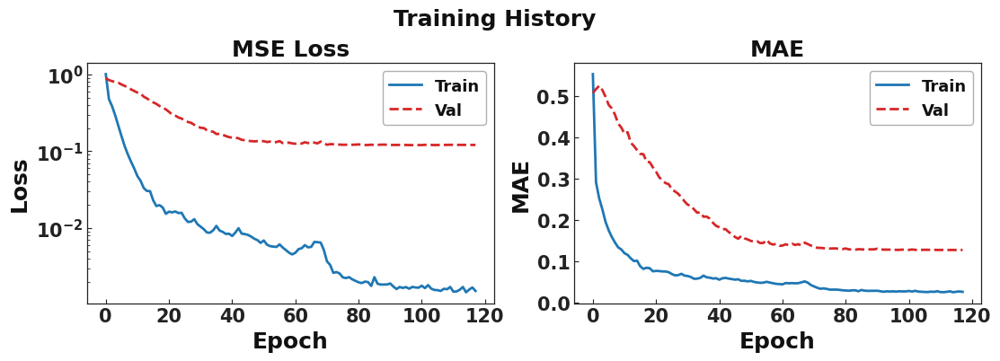


════════════════════════════════════════════════════════════
  9. ALL-SAMPLE RECONSTRUCTIONS
════════════════════════════════════════════════════════════
  ✓ Saved → /kaggle/working/figures/fig2_spectral_reconstructions.png
  ✓ Saved → /kaggle/working/figures/fig2_spectral_reconstructions.pdf



════════════════════════════════════════════════════════════
  10. REGRESSION ANALYSIS
════════════════════════════════════════════════════════════


/tmp/ipykernel_57/1898311597.py:700: RankWarning: Polyfit may be poorly conditioned
  rc      = np.polyfit(yt_all, yp_all, 1)
/tmp/ipykernel_57/1898311597.py:703: RankWarning: Polyfit may be poorly conditioned
  rc_res  = np.polyfit(yt_all, res_gl, 1)


  ✓ Saved → /kaggle/working/figures/fig3_regression.png
  ✓ Saved → /kaggle/working/figures/fig3_regression.pdf


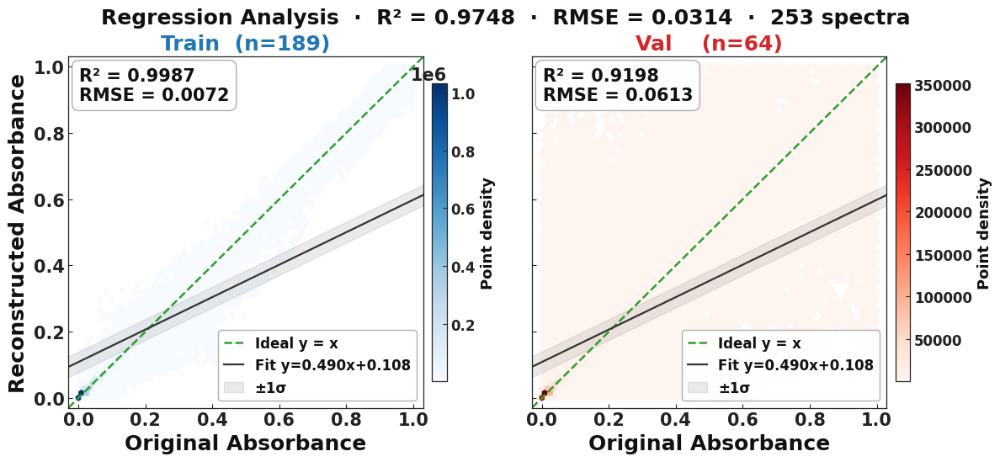

  ✓ Saved → /kaggle/working/figures/fig4_residual_scatter.png
  ✓ Saved → /kaggle/working/figures/fig4_residual_scatter.pdf


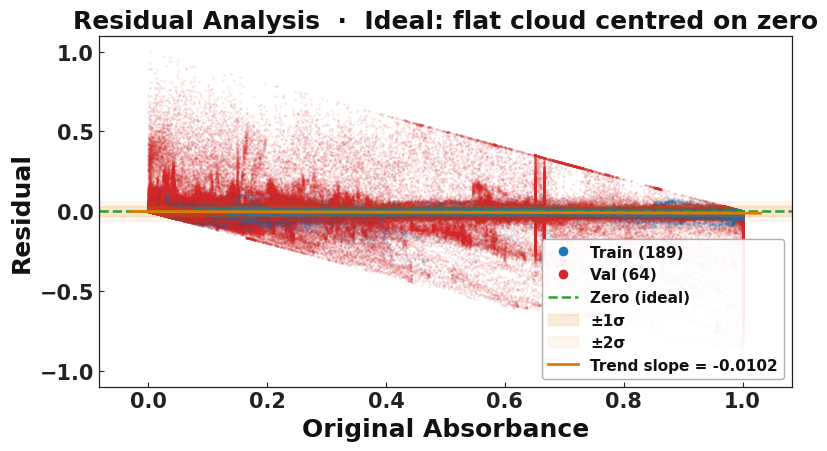

/tmp/ipykernel_57/1898311597.py:806: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=0.5)


  ✓ Saved → /kaggle/working/figures/fig5_r2_bar.png
  ✓ Saved → /kaggle/working/figures/fig5_r2_bar.pdf






════════════════════════════════════════════════════════════
  FIG 6 — 2×2
════════════════════════════════════════════════════════════
  ✓ Saved → /kaggle/working/figures/fig6_train_val_2x2.png
  ✓ Saved → /kaggle/working/figures/fig6_train_val_2x2.pdf
  ✓ Saved fig6_train_val_2x2


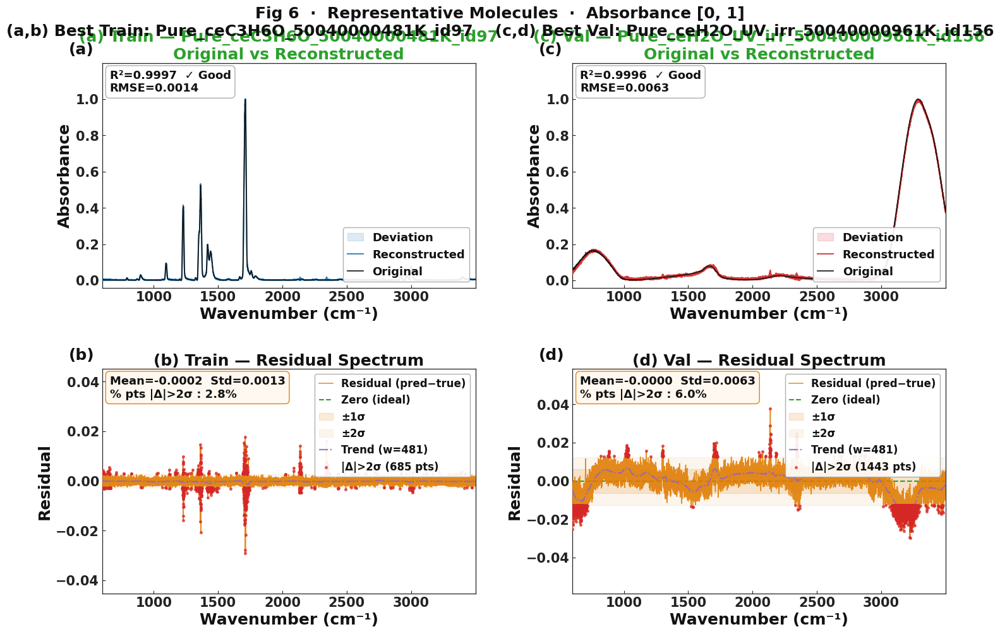


════════════════════════════════════════════════════════════
  FIG 7 — 3×2 SPOTLIGHT
════════════════════════════════════════════════════════════
  Best     : Pure_ceC3H6O_50040000481K_id97  R²=0.9997
  Moderate : H2O-CH3OH-CO-NH3 = 100.10.1.1-40K   R²=0.9987
  Poor     : CO 10K  R²=0.0706
  ✓ Saved → /kaggle/working/figures/fig7_spotlight_bmp.png
  ✓ Saved → /kaggle/working/figures/fig7_spotlight_bmp.pdf
  ✓ Saved fig7_spotlight_bmp


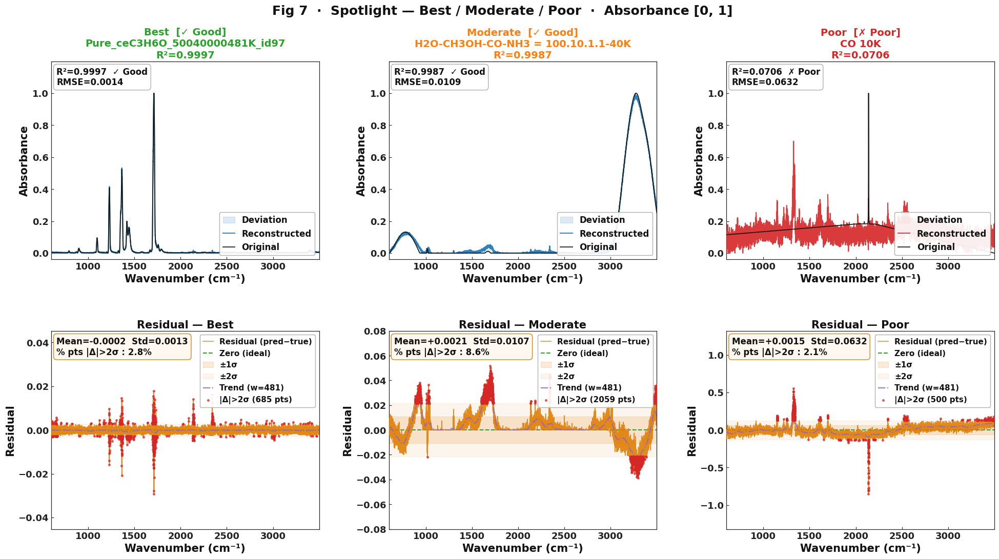


════════════════════════════════════════════════════════════
  FIG 8 — 6 INDIVIDUAL SPOTLIGHTS
════════════════════════════════════════════════════════════

  6 spotlights:
    spotlight_good1       : R²=0.9997  [TRAIN]  Pure_ceC3H6O_50040000481K_id97
    spotlight_good2       : R²=0.9997  [TRAIN]  Pure_ceCH3CHO_50040000961K_id82
    spotlight_mid1        : R²=0.9987  [TRAIN]  H2O-CH3OH-CO-NH3 = 100.10.1.1-40K
    spotlight_mid2        : R²=0.9988  [TRAIN]  ceH2OceCO2_16_54054610961K_id151
    spotlight_poor1       : R²=0.0706  [VAL]  CO 10K
    spotlight_poor2       : R²=0.0829  [VAL]  ceH2OceCH3OHceCO2ceCH4_04061023_40021560961K_id54

  ✓ Saved → /kaggle/working/figures/fig8_spotlight_good1.png
  ✓ Saved → /kaggle/working/figures/fig8_spotlight_good1.pdf


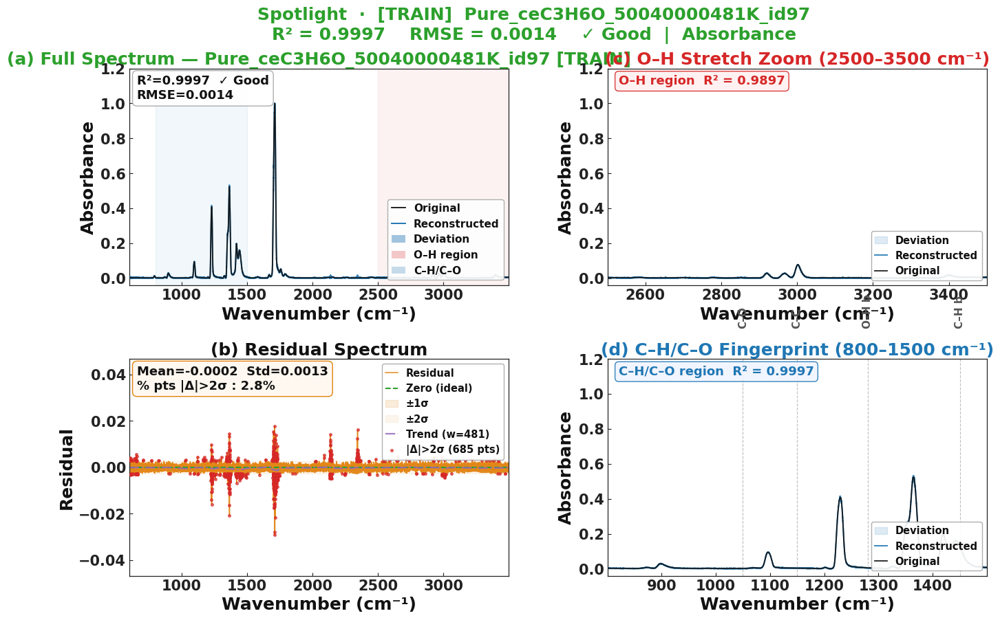

  ✓ Saved → /kaggle/working/figures/fig8_spotlight_good2.png
  ✓ Saved → /kaggle/working/figures/fig8_spotlight_good2.pdf


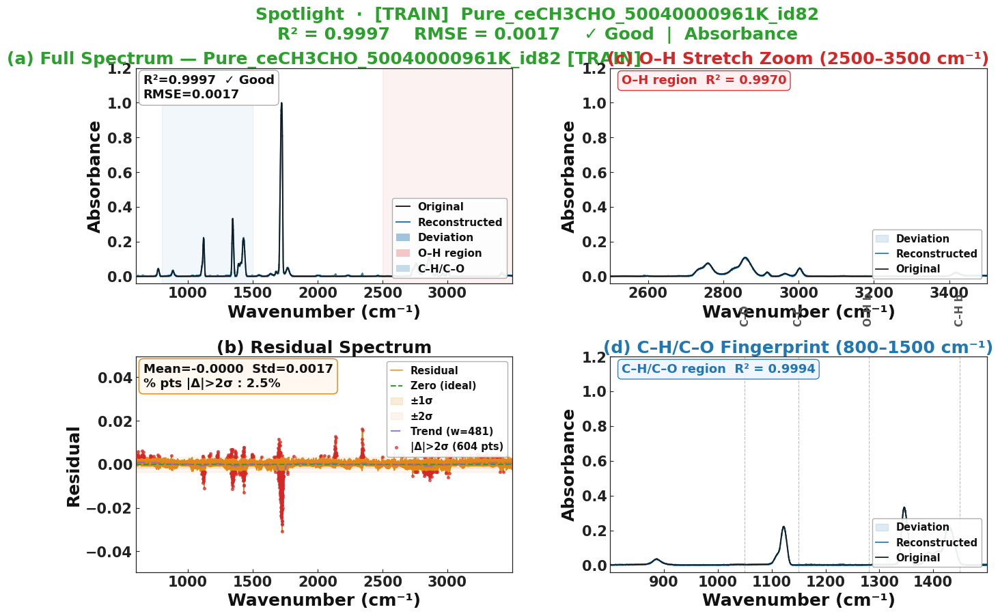

  ✓ Saved → /kaggle/working/figures/fig8_spotlight_mid1.png
  ✓ Saved → /kaggle/working/figures/fig8_spotlight_mid1.pdf


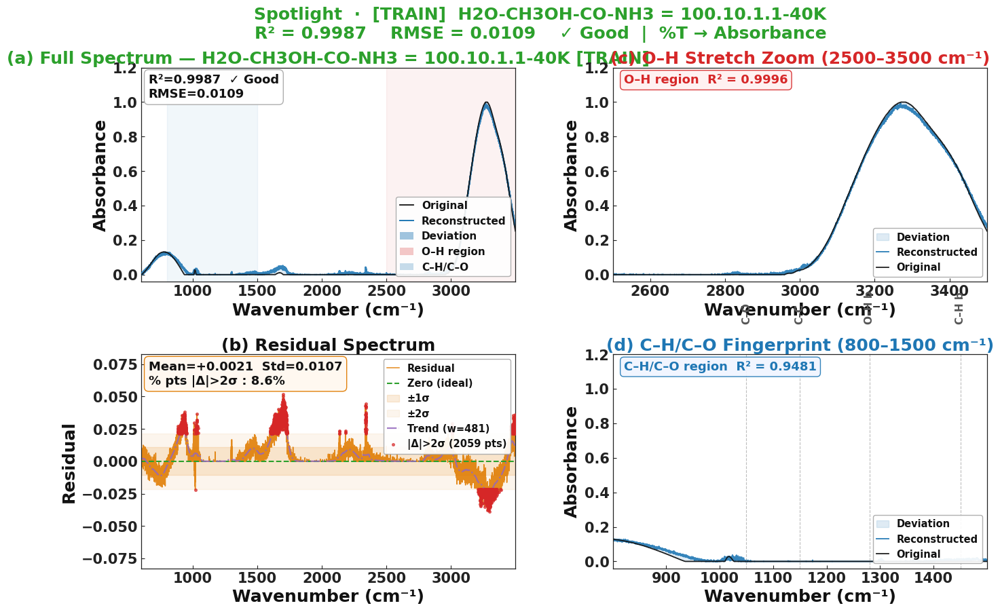

  ✓ Saved → /kaggle/working/figures/fig8_spotlight_mid2.png
  ✓ Saved → /kaggle/working/figures/fig8_spotlight_mid2.pdf


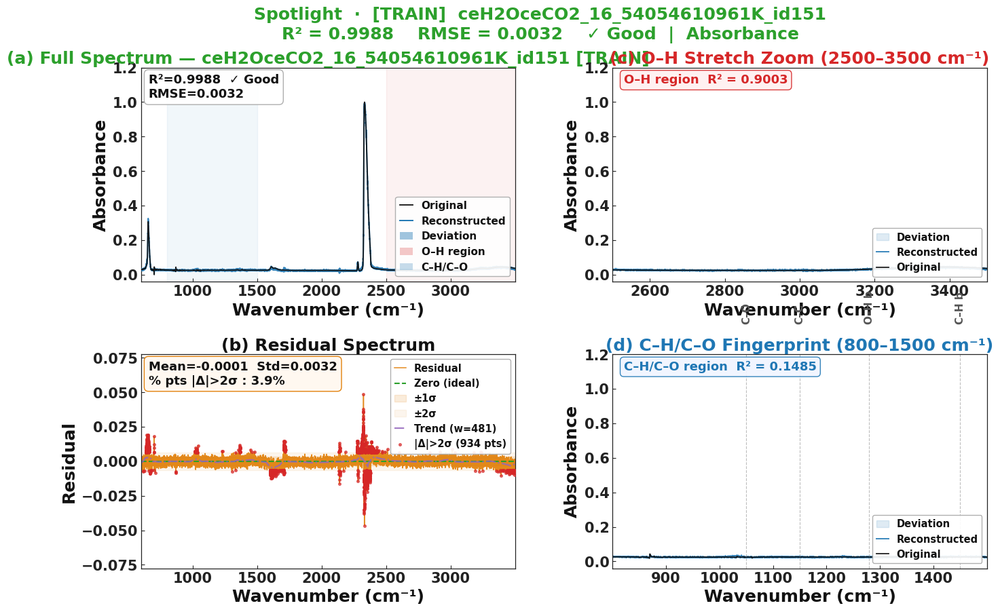

  ✓ Saved → /kaggle/working/figures/fig8_spotlight_poor1.png
  ✓ Saved → /kaggle/working/figures/fig8_spotlight_poor1.pdf


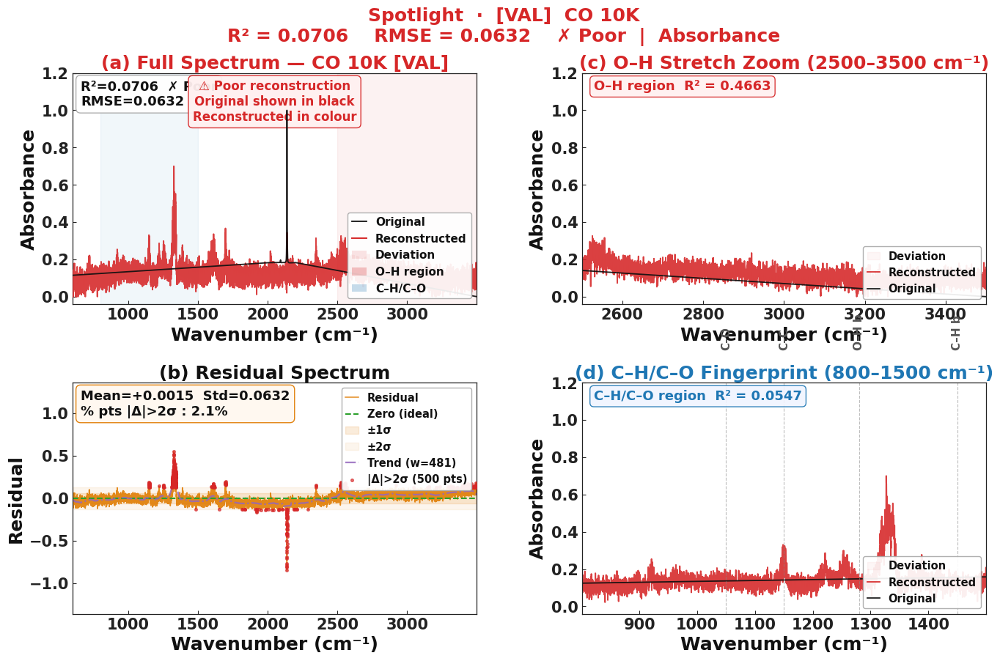

  ✓ Saved → /kaggle/working/figures/fig8_spotlight_poor2.png
  ✓ Saved → /kaggle/working/figures/fig8_spotlight_poor2.pdf


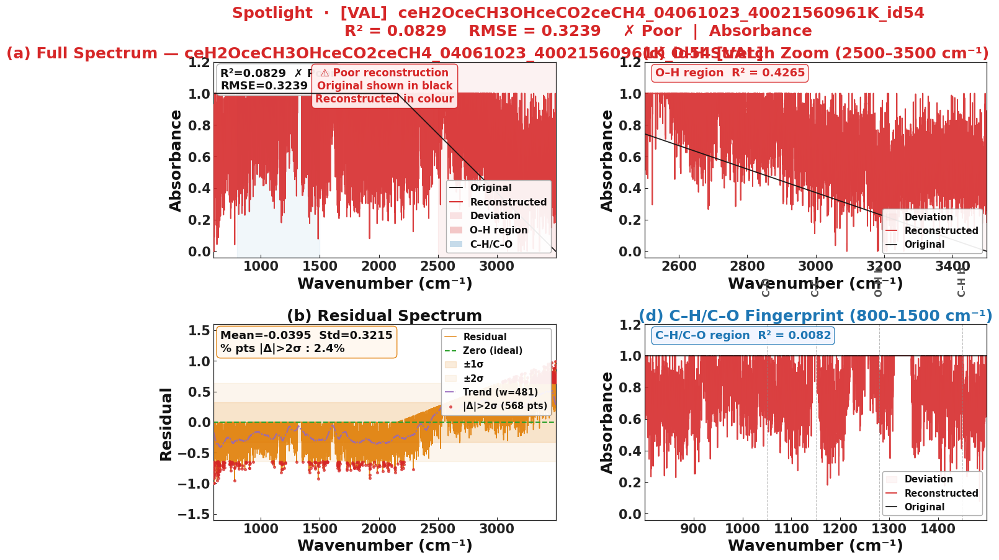


════════════════════════════════════════════════════════════
  FIG 9 — PAPER-STYLE COMPOSITE (a)(b)(c)(d)
════════════════════════════════════════════════════════════
  ✓ Saved → /kaggle/working/figures/fig9_paper_composite.png
  ✓ Saved → /kaggle/working/figures/fig9_paper_composite.pdf
  ✓ Saved fig9_paper_composite


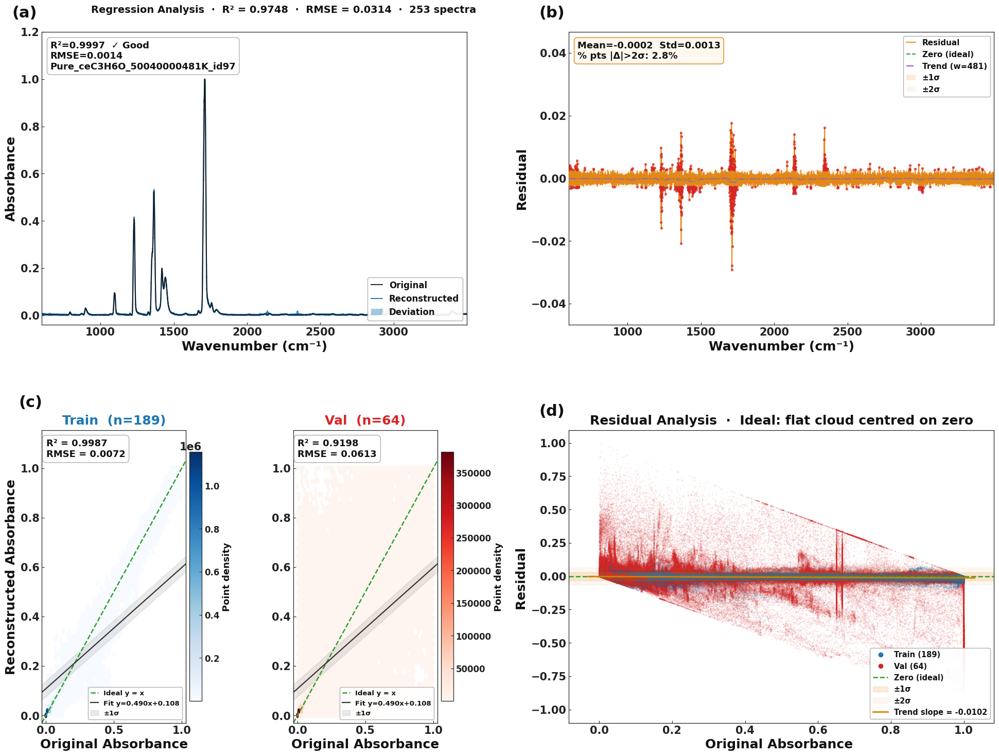


════════════════════════════════════════════════════════════
  SUMMARY
════════════════════════════════════════════════════════════
  Spectra loaded   : 253
  Train / Val      : 189 / 64
  Recon range      : [0.000000, 1.000000]
  Overall R²       : 0.9748
  Overall RMSE     : 0.0314
  Good/Fair/Poor   : 241/2/10  (95%/1%/4%)

  BOLD LETTERING (matches ternary script):
    - font.weight='bold' set globally in rcParams, so every
      text object defaults to bold, including math glyphs.
    - bold_ticks() explicitly bolds every tick label as a
      belt-and-braces check on top of the rcParams default.
    - save_figure() walks every axes right before saving and
      force-bolds titles, axis labels, tick labels, any free
      text/annotation boxes, and legend text/titles.
    - All figures (including fig6/fig7/fig8-spotlights/fig9,
      which previously used raw plt.savefig()) now go through
      save_figure() so nothing is missed.
══════════════════════════════════════════════════

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.interpolate import interp1d
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import gc

# ════════════════════════════════════════════════════════
#  OUTPUT FOLDER
# ════════════════════════════════════════════════════════
FIGURES_DIR = '/kaggle/working/figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
DPI = 300

# ════════════════════════════════════════════════════════
#  JOURNAL STYLE — NO GRID  (BOLD + LARGER LABELS)
#  Same "everything bold" convention as the ternary script:
#  font.weight is set globally to 'bold' so every text
#  object (titles, labels, ticks, legends, annotations,
#  math glyphs) defaults to bold, and save_figure() does a
#  belt-and-braces pass over every axes right before saving
#  to force bold on anything that slipped through.
# ════════════════════════════════════════════════════════
LABEL_FS = 18
TICK_FS  = 15
TITLE_FS = 18
ANNOT_FS = 14
PANEL_FS = 22

plt.rcParams.update({
    'figure.facecolor':   'white',
    'axes.facecolor':     'white',
    'axes.edgecolor':     '#222222',
    'axes.linewidth':     0.9,
    'axes.grid':          False,
    'axes.labelcolor':    '#111111',
    'axes.titlecolor':    '#111111',
    'axes.titlesize':     TITLE_FS,
    'axes.titleweight':   'bold',
    'axes.labelsize':     LABEL_FS,
    'axes.labelweight':   'bold',
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3.5,
    'ytick.major.size':   3.5,
    'xtick.color':        '#222222',
    'ytick.color':        '#222222',
    'xtick.labelsize':    TICK_FS,
    'ytick.labelsize':    TICK_FS,
    'text.color':         '#111111',
    'legend.facecolor':   'white',
    'legend.edgecolor':   '#aaaaaa',
    'legend.fontsize':    13,
    'legend.framealpha':  0.92,
    'lines.linewidth':    1.5,
    'font.family':        'sans-serif',
    'font.sans-serif':    ['DejaVu Sans', 'Arial'],
    'font.size':          13,
    'font.weight':        'bold',        # <-- makes ALL text bold by default
    'figure.titleweight': 'bold',
    'savefig.facecolor':  'white',
    'savefig.edgecolor':  'none',
    'mathtext.default':   'bf',          # bold math/number glyphs too
})

TRAIN_COL = '#1f77b4'
VAL_COL   = '#d62728'
GOOD_COL  = '#2ca02c'
FAIR_COL  = '#ff7f0e'
POOR_COL  = '#d62728'
ACCENT    = '#9467bd'
RES_COL   = '#e07b00'

def section_title(t):
    print(f"\n{'═'*60}\n  {t}\n{'═'*60}")

# ── Helper: force bold on every tick label of an axes ──
def bold_ticks(ax):
    """Explicitly bold every x/y tick label (belt-and-braces on top of rcParams)."""
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight('bold')

# ════════════════════════════════════════════════════════
#  BOLD-LABEL HELPER
# ════════════════════════════════════════════════════════
def style_axes(ax, xlabel=None, ylabel=None, label_fs=LABEL_FS, tick_fs=TICK_FS):
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=label_fs, fontweight='bold')
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=label_fs, fontweight='bold')
    ax.tick_params(labelsize=tick_fs)
    bold_ticks(ax)
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontsize(tick_fs)

# ════════════════════════════════════════════════════════
#  SAVE_FIGURE — belt-and-braces bold pass, then save
#  Mirrors the ternary script: walks every axes on the
#  figure right before saving and forces bold on titles,
#  tick labels, any free-floating text boxes/annotations,
#  and legend text/titles, so nothing slips through as
#  regular weight even if a helper forgot to set it.
# ════════════════════════════════════════════════════════
def save_figure(fig, filename):
    for ax in fig.get_axes():
        bold_ticks(ax)
        if ax.get_title():
            ax.title.set_fontweight('bold')
        ax.xaxis.label.set_fontweight('bold')
        ax.yaxis.label.set_fontweight('bold')
        for txt in ax.texts:
            txt.set_fontweight('bold')
        leg = ax.get_legend()
        if leg is not None:
            for t in leg.get_texts():
                t.set_fontweight('bold')
            if leg.get_title() is not None:
                leg.get_title().set_fontweight('bold')
    for txt in fig.texts:
        txt.set_fontweight('bold')
    if fig._suptitle is not None:
        fig._suptitle.set_fontweight('bold')
    for ext in ['png', 'pdf']:
        path = os.path.join(FIGURES_DIR, f"{filename}.{ext}")
        fig.savefig(path, dpi=DPI, bbox_inches='tight',
                    facecolor='white', edgecolor='none')
        print(f"  ✓ Saved → {path}")

# ════════════════════════════════════════════════════════
#  PAH SKIP LIST
# ════════════════════════════════════════════════════════
PAH_SKIP_KEYWORDS = [
    'pah','naphthalene','anthracene','pyrene','fluorene',
    'phenanthrene','chrysene','acenaphthylene','acenaphthene',
    'fluoranthene','benzo','perylene','indene',
]
def is_pah_file(fn):
    return any(kw in fn.lower() for kw in PAH_SKIP_KEYWORDS)

# ════════════════════════════════════════════════════════
#  TRANSMITTANCE → ABSORBANCE
# ════════════════════════════════════════════════════════
def detect_and_convert(ab, fname):
    v = ab[np.isfinite(ab)]
    mx, mn, md = v.max(), v.min(), np.median(v)
    if mx > 1.5 and mn >= 0:
        tc = np.clip(ab, 1e-4, 100.0)
        return -np.log10(tc / 100.0), '%T → Absorbance', True
    elif mx <= 1.5 and mn >= 0 and md > 0.4:
        tc = np.clip(ab, 1e-6, 1.0)
        return -np.log10(tc), 'T-frac → Absorbance', True
    else:
        return ab, 'Absorbance', False

# ════════════════════════════════════════════════════════
#  PHYSICAL NORMALISATION  →  guaranteed [0, 1]
# ════════════════════════════════════════════════════════
def physical_normalise(s):
    s = s.astype(np.float64) - s.min()
    pk = s.max()
    if pk > 1e-12:
        s = s / pk
    return s.astype(np.float32)

# ════════════════════════════════════════════════════════
#  1. FIND CSV FILES
# ════════════════════════════════════════════════════════
section_title("1. LOADING DATA")
input_base = '/kaggle/input/new-test-data'
csv_files  = []
for root, _, files in os.walk(input_base):
    for f in files:
        if f.lower().endswith('.csv'):
            csv_files.append(os.path.join(root, f))
print(f"Found {len(csv_files)} CSV files\n")

# ════════════════════════════════════════════════════════
#  2. LOAD + CONVERT + PHYSICAL NORMALISE
# ════════════════════════════════════════════════════════
section_title("2. PARSING + UNIT CONVERSION + NORMALISE")

spectra, names, wavenumbers_list = [], [], []
conversion_log, skipped_pah, skipped_bad = [], [], []
converted_files, kept_as_is = [], []

for path in csv_files:
    fname = os.path.basename(path)
    base  = fname.replace('.csv', '')
    if is_pah_file(fname):
        skipped_pah.append(fname); continue
    df = pd.read_csv(path)
    if df.shape[1] < 2:
        skipped_bad.append(fname); continue
    wn = df.iloc[:, 0].values.astype(np.float32)
    ab = df.iloc[:, 1].values.astype(np.float32)
    mask = np.isfinite(wn) & np.isfinite(ab)
    wn, ab = wn[mask], ab[mask]
    if len(wn) < 10:
        skipped_bad.append(fname); continue
    ab, unit_label, was_cv = detect_and_convert(ab, fname)
    if was_cv: converted_files.append(fname)
    else:      kept_as_is.append(fname)
    ab = physical_normalise(ab)
    conversion_log.append({'file': base, 'unit': unit_label, 'converted': was_cv})
    si = np.argsort(wn)
    spectra.append(ab[si]); wavenumbers_list.append(wn[si]); names.append(base)

print(f"  ✓ Loaded: {len(spectra)}  PAH skip: {len(skipped_pah)}  "
      f"Bad: {len(skipped_bad)}  T→A: {len(converted_files)}")
if len(spectra) == 0:
    raise ValueError("No spectra loaded.")

# ════════════════════════════════════════════════════════
#  3. RESAMPLE → CROP → RE-NORMALISE
# ════════════════════════════════════════════════════════
section_title("3. RESAMPLE + CROP")
li        = np.argmax([len(s) for s in spectra])
common_wn = wavenumbers_list[li].copy()
tl        = (len(common_wn) // 4) * 4
common_wn = common_wn[:tl]

X = np.zeros((len(spectra), tl), dtype=np.float32)
for i, (sp, ow) in enumerate(zip(spectra, wavenumbers_list)):
    fn   = interp1d(ow, sp, kind='linear', bounds_error=False, fill_value='extrapolate')
    X[i] = fn(common_wn)

WN_MIN, WN_MAX = 600.0, 3500.0
ci = np.where((common_wn >= WN_MIN) & (common_wn <= WN_MAX))[0]
ci = ci[:(len(ci) // 4) * 4]
common_wn = common_wn[ci]; X = X[:, ci]; tl = len(common_wn)

for i in range(len(X)):
    X[i] = physical_normalise(X[i])
X = np.clip(X, 0.0, 1.0)
print(f"✓ X range [{X.min():.5f}, {X.max():.5f}]  shape {X.shape}")

# ════════════════════════════════════════════════════════
#  4. STANDARDISE + SPLIT
# ════════════════════════════════════════════════════════
section_title("4. STANDARDISE + SPLIT")
X_std, scalers = np.zeros_like(X), []
for i in range(len(X)):
    sc = StandardScaler()
    X_std[i] = sc.fit_transform(X[i].reshape(-1, 1)).ravel()
    scalers.append(sc)
X_std3 = X_std[..., np.newaxis]

ai = np.arange(len(X))
if len(X) >= 4:
    train_idx, val_idx = train_test_split(ai, test_size=0.25, random_state=42)
elif len(X) >= 2:
    train_idx = list(ai[:-1]); val_idx = list(ai[-1:])
else:
    train_idx = list(ai); val_idx = list(ai)
train_idx = list(train_idx); val_idx = list(val_idx)
print(f"✓ Train {len(train_idx)} | Val {len(val_idx)}")

# ════════════════════════════════════════════════════════
#  5. CNN AUTOENCODER
# ════════════════════════════════════════════════════════
section_title("5. BUILD AUTOENCODER")
def build_autoencoder(L, latent=64):
    inp = layers.Input(shape=(L, 1))
    x = layers.Conv1D(32, 7, activation='relu', padding='same')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    sb = x.shape[1:]
    x  = layers.Flatten()(x)
    z  = layers.Dense(latent, activation='relu', name='latent')(x)
    x  = layers.Dense(sb[0] * sb[1], activation='relu')(z)
    x  = layers.Reshape(sb)(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    x  = layers.UpSampling1D(2)(x)
    x  = layers.Conv1D(32, 7, activation='relu', padding='same')(x)
    x  = layers.BatchNormalization()(x)
    out = layers.Conv1D(1, 3, activation='linear', padding='same')(x)
    assert out.shape[1] == L
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss='mse', metrics=['mae'])
    return m

model = build_autoencoder(tl)
model.summary()

# ════════════════════════════════════════════════════════
#  6. TRAIN
# ════════════════════════════════════════════════════════
section_title("6. TRAIN")
bs  = max(1, min(16, len(train_idx)))
mon = 'val_loss' if set(val_idx) != set(train_idx) else 'loss'
history = model.fit(
    X_std3[train_idx], X_std3[train_idx],
    validation_data=(X_std3[val_idx], X_std3[val_idx]),
    epochs=150, batch_size=bs,
    callbacks=[
        callbacks.EarlyStopping(monitor=mon, patience=20,
                                restore_best_weights=True, min_delta=1e-5, verbose=1),
        callbacks.ReduceLROnPlateau(monitor=mon, factor=0.5,
                                    patience=8, min_lr=1e-7, verbose=1),
    ], verbose=1)

# ════════════════════════════════════════════════════════
#  7. RECONSTRUCT  (clip only — no re-normalise)
# ════════════════════════════════════════════════════════
section_title("7. RECONSTRUCT")
raw     = model.predict(X_std3, verbose=0)
X_recon = np.zeros((len(X), tl), dtype=np.float32)
for i in range(len(X)):
    inv = scalers[i].inverse_transform(
              raw[i, :, 0].reshape(-1, 1)).ravel().astype(np.float32)
    X_recon[i] = np.clip(inv, 0.0, 1.0)
print(f"✓ Recon range [{X_recon.min():.6f}, {X_recon.max():.6f}]")

# ════════════════════════════════════════════════════════
#  PER-SAMPLE STATS
# ════════════════════════════════════════════════════════
per_r2, per_rmse, per_mae = [], [], []
for i in range(len(X)):
    yt, yp = X[i], X_recon[i]
    if np.std(yp) < 1e-10 or np.std(yt) < 1e-10: r2i = 0.0
    else:
        ri, _ = pearsonr(yt, yp); r2i = float(ri ** 2)
    per_r2.append(r2i)
    per_rmse.append(float(np.sqrt(np.mean((yt - yp) ** 2))))
    per_mae.append(float(np.mean(np.abs(yt - yp))))

r2_arr   = np.array(per_r2)
rmse_arr = np.array(per_rmse)
pct25, pct50, pct75, pct90 = (np.percentile(r2_arr, p) for p in [25, 50, 75, 90])
print(f"  R² Mean={r2_arr.mean():.4f}  Median={pct50:.4f}  "
      f"Min={r2_arr.min():.4f}  Max={r2_arr.max():.4f}")

# ════════════════════════════════════════════════════════
#  QUALITY HELPERS
# ════════════════════════════════════════════════════════
def _quality(r2):
    return '✓ Good' if r2 >= 0.95 else ('~ Fair' if r2 >= 0.85 else '✗ Poor')

# ════════════════════════════════════════════════════════
#  DRAW_SPECTRUM
# ════════════════════════════════════════════════════════
def draw_spectrum(ax, idx, label='', compact=False):
    yt  = X[idx];  yp = X_recon[idx]
    col = VAL_COL if idx in val_idx else TRAIN_COL
    fs  = 12 if compact else 13
    lfs = 15 if compact else LABEL_FS
    tfs = 13 if compact else TICK_FS
    r2i = per_r2[idx]; rmsei = per_rmse[idx]
    q   = _quality(r2i)

    if r2i >= 0.95:
        fill_alpha = 0.15
    elif r2i >= 0.85:
        fill_alpha = 0.10
    else:
        fill_alpha = 0.04

    ax.fill_between(common_wn, yt, yp,
                    color=col, alpha=fill_alpha,
                    label='Deviation', zorder=1)
    ax.plot(common_wn, yp,
            color=col, lw=1.4, alpha=0.90,
            label='Reconstructed', zorder=3)
    ax.plot(common_wn, yt,
            color='#111111', lw=1.3, alpha=0.92,
            label='Original', zorder=4)

    ax.text(0.02, 0.97,
            f'R²={r2i:.4f}  {q}\nRMSE={rmsei:.4f}',
            transform=ax.transAxes, fontsize=fs, fontweight='bold', va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.20)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    style_axes(ax, 'Wavenumber (cm⁻¹)', 'Absorbance', label_fs=lfs, tick_fs=tfs)

    title_col = GOOD_COL if r2i >= 0.95 else (FAIR_COL if r2i >= 0.85 else POOR_COL)
    ax.set_title(label if label else names[idx],
                 fontsize=lfs, fontweight='bold', color=title_col, pad=4)
    leg = ax.legend(fontsize=fs, loc='lower right',
                     handlelength=1.4, framealpha=0.92)
    for t in leg.get_texts(): t.set_fontweight('bold')


def draw_residual(ax, idx, label='', compact=False):
    yt = X[idx]; yp = X_recon[idx]
    res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    fs  = 12 if compact else 13
    lfs = 15 if compact else LABEL_FS
    tfs = 13 if compact else TICK_FS

    ax.plot(common_wn, res,   color=RES_COL, lw=1.1, alpha=0.88,
            label='Residual (pred−true)', zorder=3)
    ax.axhline(0, color=GOOD_COL, lw=1.5, ls='--',
               label='Zero (ideal)', zorder=2)
    ax.axhspan(-rs,   rs,   color=RES_COL, alpha=0.15, label='±1σ', zorder=1)
    ax.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ', zorder=0)

    win    = max(1, len(res) // 50)
    smooth = np.convolve(res, np.ones(win) / win, mode='same')
    ax.plot(common_wn, smooth, color=ACCENT, lw=1.6, ls='-.',
            alpha=0.85, label=f'Trend (w={win})', zorder=4)

    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax.scatter(common_wn[herr], res[herr],
                   color='#d62728', s=7, zorder=5, alpha=0.65,
                   label=f'|Δ|>2σ ({herr.sum()} pts)')

    pct2 = 100.0 * float(np.mean(herr))
    ax.text(0.02, 0.97,
            f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
            transform=ax.transAxes, fontsize=fs, fontweight='bold', va='top',
            bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                      boxstyle='round,pad=0.35', alpha=0.95))

    ax.set_xlim(common_wn.min(), common_wn.max())
    ymax = max(abs(res).max(), 3*rs) * 1.55 + 1e-9
    ax.set_ylim(-ymax, ymax)
    style_axes(ax, 'Wavenumber (cm⁻¹)', 'Residual', label_fs=lfs, tick_fs=tfs)
    ax.set_title(label if label else 'Residual Spectrum',
                 fontsize=lfs, fontweight='bold', pad=4)
    leg = ax.legend(fontsize=fs-1, loc='upper right',
                     handlelength=1.3, framealpha=0.92, ncol=1)
    for t in leg.get_texts(): t.set_fontweight('bold')


# ════════════════════════════════════════════════════════
#  PLOT_4PANEL_SPOTLIGHT
# ════════════════════════════════════════════════════════
def plot_4panel_spotlight(idx, fig_suffix):
    yt  = X[idx]; yp = X_recon[idx]; res = yp - yt
    rs  = float(np.std(res)); rm = float(np.mean(res))
    r2m = per_r2[idx]; rmse_m = per_rmse[idx]
    q   = _quality(r2m)
    spl = 'TRAIN' if idx in train_idx else 'VAL'
    col = TRAIN_COL if spl == 'TRAIN' else VAL_COL
    ul  = conversion_log[idx]['unit'] if idx < len(conversion_log) else 'Absorbance'
    title_col = GOOD_COL if r2m >= 0.95 else (FAIR_COL if r2m >= 0.85 else POOR_COL)

    if r2m >= 0.95:
        fill_alpha = 0.14
    elif r2m >= 0.85:
        fill_alpha = 0.09
    else:
        fill_alpha = 0.04

    def reg_r2(lo, hi):
        m = (common_wn >= lo) & (common_wn <= hi)
        if m.sum() < 5: return float('nan')
        ytr, ypr = yt[m], yp[m]
        if np.std(ypr) < 1e-10: return 0.0
        r, _ = pearsonr(ytr, ypr); return float(r ** 2)

    fig = plt.figure(figsize=(14, 9))
    fig.suptitle(
        f'Spotlight  ·  [{spl}]  {names[idx]}\n'
        f'R² = {r2m:.4f}    RMSE = {rmse_m:.4f}    {q}  |  {ul}',
        fontsize=TITLE_FS, fontweight='bold', y=1.01, color=title_col)
    gs = gridspec.GridSpec(2, 2, figure=fig,
                           hspace=0.34, wspace=0.26,
                           left=0.08, right=0.97,
                           top=0.91,  bottom=0.09)

    # ── (a) Full spectrum ─────────────────────────────
    ax_a = fig.add_subplot(gs[0, 0])

    OH_MIN_a, OH_MAX_a = 2500.0, min(3500.0, common_wn.max())
    FP_MIN_a, FP_MAX_a = max(800.0, common_wn.min()), 1500.0
    ax_a.axvspan(OH_MIN_a, OH_MAX_a,  color='#d62728', alpha=0.06, zorder=0)
    ax_a.axvspan(FP_MIN_a, FP_MAX_a,  color='#1f77b4', alpha=0.06, zorder=0)

    ax_a.fill_between(common_wn, yt, yp,
                      color=col, alpha=fill_alpha,
                      label='Deviation', zorder=1)
    ax_a.plot(common_wn, yp,
              color=col, lw=1.4, alpha=0.88,
              label='Reconstructed', zorder=3)
    ax_a.plot(common_wn, yt,
              color='#111111', lw=1.3, alpha=0.93,
              label='Original', zorder=4)

    ax_a.set_xlim(common_wn.min(), common_wn.max())
    ax_a.set_ylim(-0.04, 1.20)
    style_axes(ax_a, 'Wavenumber (cm⁻¹)', 'Absorbance')
    ax_a.set_title(f'(a) Full Spectrum — {names[idx]} [{spl}]',
                   fontsize=LABEL_FS, fontweight='bold', color=title_col, pad=4)

    stats_text = f'R²={r2m:.4f}  {q}\nRMSE={rmse_m:.4f}'
    ax_a.text(0.02, 0.97, stats_text,
              transform=ax_a.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
              bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                        boxstyle='round,pad=0.35', alpha=0.95))

    if r2m < 0.85:
        ax_a.text(0.50, 0.97,
                  '⚠ Poor reconstruction\nOriginal shown in black\nReconstructed in colour',
                  transform=ax_a.transAxes, fontsize=ANNOT_FS-2, va='top', ha='center',
                  color=POOR_COL, fontweight='bold',
                  bbox=dict(facecolor='#fff0f0', edgecolor=POOR_COL,
                            boxstyle='round,pad=0.35', alpha=0.95))

    leg_handles = [
        Line2D([0],[0], color='#111111', lw=1.3, label='Original'),
        Line2D([0],[0], color=col,       lw=1.4, label='Reconstructed'),
        Patch(facecolor=col, alpha=fill_alpha*3, label='Deviation'),
        Patch(facecolor='#d62728', alpha=0.25, label='O–H region'),
        Patch(facecolor='#1f77b4', alpha=0.25, label='C–H/C–O'),
    ]
    leg = ax_a.legend(handles=leg_handles, fontsize=11,
                       loc='lower right', handlelength=1.3, ncol=1)
    for t in leg.get_texts(): t.set_fontweight('bold')

    # ── (b) Residual ──────────────────────────────────
    ax_b = fig.add_subplot(gs[1, 0])
    ax_b.plot(common_wn, res, color=RES_COL, lw=1.1, alpha=0.88,
              label='Residual')
    ax_b.axhline(0, color=GOOD_COL, lw=1.5, ls='--', label='Zero (ideal)')
    ax_b.axhspan(-rs,   rs,   color=RES_COL, alpha=0.14, label='±1σ')
    ax_b.axhspan(-2*rs, 2*rs, color=RES_COL, alpha=0.07, label='±2σ')
    win = max(1, len(res) // 50)
    sm  = np.convolve(res, np.ones(win) / win, mode='same')
    ax_b.plot(common_wn, sm, color=ACCENT, lw=1.6, ls='-.', alpha=0.85,
              label=f'Trend (w={win})')
    herr = np.abs(res) > 2 * rs
    if herr.any():
        ax_b.scatter(common_wn[herr], res[herr],
                     color='#d62728', s=7, zorder=5, alpha=0.65,
                     label=f'|Δ|>2σ ({herr.sum()} pts)')
    ax_b.set_xlim(common_wn.min(), common_wn.max())
    ymax_b = max(abs(res).max(), 3*rs) * 1.6 + 1e-9
    ax_b.set_ylim(-ymax_b, ymax_b)
    style_axes(ax_b, 'Wavenumber (cm⁻¹)', 'Residual')
    ax_b.set_title('(b) Residual Spectrum', fontsize=LABEL_FS, fontweight='bold', pad=4)
    pct2 = 100 * float(np.mean(herr))
    ax_b.text(0.02, 0.97,
              f'Mean={rm:+.4f}  Std={rs:.4f}\n% pts |Δ|>2σ : {pct2:.1f}%',
              transform=ax_b.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
              bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL,
                        boxstyle='round,pad=0.35', alpha=0.95))
    leg = ax_b.legend(fontsize=10.5, loc='upper right', handlelength=1.2, ncol=1)
    for t in leg.get_texts(): t.set_fontweight('bold')

    # ── (c) O-H zoom ──────────────────────────────────
    OH_MIN, OH_MAX = 2500.0, 3500.0
    ax_c = fig.add_subplot(gs[0, 1])
    m_oh  = (common_wn >= OH_MIN) & (common_wn <= OH_MAX)
    wn_oh = common_wn[m_oh]
    if m_oh.sum() > 5:
        ax_c.fill_between(wn_oh, yt[m_oh], yp[m_oh],
                          color=col, alpha=fill_alpha, label='Deviation')
        ax_c.plot(wn_oh, yp[m_oh], color=col,       lw=1.4, alpha=0.88,
                  label='Reconstructed')
        ax_c.plot(wn_oh, yt[m_oh], color='#111111', lw=1.3, alpha=0.93,
                  label='Original')
        ax_c.set_xlim(wn_oh.min(), wn_oh.max())
        r2oh = reg_r2(OH_MIN, OH_MAX)
        r2oh_str = f'{r2oh:.4f}' if not np.isnan(r2oh) else 'N/A'
        ax_c.text(0.03, 0.97, f'O–H region  R² = {r2oh_str}',
                  transform=ax_c.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
                  color='#d62728',
                  bbox=dict(facecolor='#fff0f0', edgecolor='#d62728',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_c.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_c.transAxes, fontsize=ANNOT_FS, fontweight='bold')
    ax_c.set_ylim(-0.04, 1.20)
    style_axes(ax_c, 'Wavenumber (cm⁻¹)', 'Absorbance')
    ax_c.set_title(f'(c) O–H Stretch Zoom ({OH_MIN:.0f}–{OH_MAX:.0f} cm⁻¹)',
                   fontsize=LABEL_FS, fontweight='bold', color='#d62728', pad=4)
    leg = ax_c.legend(fontsize=10.5, loc='lower right', handlelength=1.2)
    for t in leg.get_texts(): t.set_fontweight('bold')

    # ── (d) Fingerprint zoom ──────────────────────────
    FP_MIN, FP_MAX = 800.0, 1500.0
    FP_BANDS = {'C–O': 1050, 'C–C': 1150, 'O–H b': 1280, 'C–H b': 1450}
    ax_d = fig.add_subplot(gs[1, 1])
    m_fp  = (common_wn >= FP_MIN) & (common_wn <= FP_MAX)
    wn_fp = common_wn[m_fp]
    if m_fp.sum() > 5:
        ax_d.fill_between(wn_fp, yt[m_fp], yp[m_fp],
                          color=col, alpha=fill_alpha, label='Deviation')
        ax_d.plot(wn_fp, yp[m_fp], color=col,       lw=1.4, alpha=0.88,
                  label='Reconstructed')
        ax_d.plot(wn_fp, yt[m_fp], color='#111111', lw=1.3, alpha=0.93,
                  label='Original')
        ax_d.set_xlim(wn_fp.min(), wn_fp.max())
        for bname, bwn in FP_BANDS.items():
            if FP_MIN <= bwn <= FP_MAX:
                ax_d.axvline(bwn, color='#888888', lw=0.8, ls='--', alpha=0.55)
                ax_d.text(bwn, 1.14, bname, ha='center', va='bottom',
                          fontsize=11, fontweight='bold', color='#555555', rotation=90,
                          transform=ax_d.get_xaxis_transform())
        r2fp = reg_r2(FP_MIN, FP_MAX)
        r2fp_str = f'{r2fp:.4f}' if not np.isnan(r2fp) else 'N/A'
        ax_d.text(0.03, 0.97, f'C–H/C–O region  R² = {r2fp_str}',
                  transform=ax_d.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
                  color='#1f77b4',
                  bbox=dict(facecolor='#f0f4ff', edgecolor='#1f77b4',
                            boxstyle='round,pad=0.3', alpha=0.9))
    else:
        ax_d.text(0.5, 0.5, 'Not in range', ha='center', va='center',
                  transform=ax_d.transAxes, fontsize=ANNOT_FS, fontweight='bold')
    ax_d.set_ylim(-0.04, 1.20)
    style_axes(ax_d, 'Wavenumber (cm⁻¹)', 'Absorbance')
    ax_d.set_title(f'(d) C–H/C–O Fingerprint ({FP_MIN:.0f}–{FP_MAX:.0f} cm⁻¹)',
                   fontsize=LABEL_FS, fontweight='bold', color='#1f77b4', pad=4)
    leg = ax_d.legend(fontsize=10.5, loc='lower right', handlelength=1.2)
    for t in leg.get_texts(): t.set_fontweight('bold')

    save_figure(fig, f'fig8_{fig_suffix}')
    plt.show(); plt.close(fig); gc.collect()

# ════════════════════════════════════════════════════════
#  8. TRAINING CURVES
# ════════════════════════════════════════════════════════
section_title("8. TRAINING CURVES")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Training History', fontsize=TITLE_FS, fontweight='bold')
er = range(len(history.history['loss']))
for ax, key, title in [(ax1, 'loss', 'MSE Loss'), (ax2, 'mae', 'MAE')]:
    ax.plot(er, history.history[key],          color=TRAIN_COL, lw=2, label='Train')
    ax.plot(er, history.history[f'val_{key}'], color=VAL_COL,   lw=2, ls='--', label='Val')
    ax.set_title(title, fontsize=LABEL_FS, fontweight='bold')
    style_axes(ax, xlabel='Epoch')
    leg = ax.legend(fontsize=13)
    for t in leg.get_texts(): t.set_fontweight('bold')
ax1.set_ylabel('Loss', fontsize=LABEL_FS, fontweight='bold'); ax1.set_yscale('log')
ax2.set_ylabel('MAE',  fontsize=LABEL_FS, fontweight='bold')
style_axes(ax1); style_axes(ax2)
plt.tight_layout(pad=0.5, w_pad=1.0)
save_figure(fig, 'fig1_training_curves'); plt.show()

# ════════════════════════════════════════════════════════
#  9. ALL-SAMPLE RECONSTRUCTIONS
# ════════════════════════════════════════════════════════
section_title("9. ALL-SAMPLE RECONSTRUCTIONS")
nc = 3; nr = int(np.ceil(len(X) / nc))
fig = plt.figure(figsize=(18, 3.4 * nr))
fig.suptitle('Spectral Reconstructions — All Samples  (Absorbance)',
             fontsize=TITLE_FS, fontweight='bold', y=1.01)
for i in range(len(X)):
    ax  = fig.add_subplot(nr, nc, i + 1)
    col = VAL_COL if i in val_idx else TRAIN_COL
    tag = 'VAL' if i in val_idx else 'TRAIN'
    r2i = per_r2[i]
    fa  = 0.14 if r2i >= 0.95 else (0.09 if r2i >= 0.85 else 0.03)
    ax.fill_between(common_wn, X[i], X_recon[i],
                    color=col, alpha=fa, zorder=1)
    ax.plot(common_wn, X_recon[i], color=col,       lw=1.0, alpha=0.90, zorder=3,
            label='Recon')
    ax.plot(common_wn, X[i],       color='#222222', lw=0.9, alpha=0.90, zorder=4,
            label='Orig')
    ax.set_xlim(common_wn.min(), common_wn.max())
    ax.set_ylim(-0.04, 1.20)
    ax.set_yticks([0, 0.5, 1.0])
    xt = np.linspace(common_wn.min(), common_wn.max(), 4)
    ax.set_xticks(xt)
    ax.set_xticklabels([f"{v:.0f}" for v in xt], fontsize=11, fontweight='bold',
                        rotation=30, ha='right')
    ax.tick_params(labelsize=11)
    bold_ticks(ax)
    for lbl in ax.get_yticklabels():
        lbl.set_fontsize(11)
    ax.set_xlabel('Wavenumber (cm⁻¹)', fontsize=12, fontweight='bold', labelpad=1)
    ax.set_ylabel('Absorbance [0–1]',  fontsize=12, fontweight='bold', labelpad=1)
    tc = GOOD_COL if r2i >= 0.95 else (FAIR_COL if r2i >= 0.85 else POOR_COL)
    ax.set_title(f"{names[i]}\n[{tag}] R²={r2i:.3f}", fontsize=11.5, fontweight='bold', color=tc)
    leg = ax.legend(fontsize=8, loc='lower right', handlelength=1)
    for t in leg.get_texts(): t.set_fontweight('bold')
for j in range(len(X), nr * nc):
    fig.add_subplot(nr, nc, j + 1).set_visible(False)
plt.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.4)
save_figure(fig, 'fig2_spectral_reconstructions'); plt.show()

# ════════════════════════════════════════════════════════
#  10. REGRESSION (hexbin — train / val separate)
# ════════════════════════════════════════════════════════
section_title("10. REGRESSION ANALYSIS")
yt_all = X.ravel(); yp_all = X_recon.ravel()
r_g, _ = pearsonr(yt_all, yp_all)
r2_all  = float(r_g ** 2)
rmse_gl = float(np.sqrt(np.mean((yt_all - yp_all) ** 2)))
rc      = np.polyfit(yt_all, yp_all, 1)
res_gl  = yp_all - yt_all
rsd_gl  = float(np.std(res_gl))
rc_res  = np.polyfit(yt_all, res_gl, 1)

yt_tr = X[train_idx].ravel(); yp_tr = X_recon[train_idx].ravel()
yt_vl = X[val_idx].ravel();   yp_vl = X_recon[val_idx].ravel()
pad   = 0.03
dmin  = min(yt_all.min(), yp_all.min()) - pad
dmax  = max(yt_all.max(), yp_all.max()) + pad
xl    = np.linspace(dmin, dmax, 300)
fv    = np.poly1d(rc)(xl)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
fig.suptitle(f'Regression Analysis  ·  R² = {r2_all:.4f}  ·  RMSE = {rmse_gl:.4f}'
             f'  ·  {len(X)} spectra', fontsize=TITLE_FS, fontweight='bold')
for ax, (yt_s, yp_s, col, cmap), title in zip(
        axes,
        [(yt_tr, yp_tr, TRAIN_COL, 'Blues'), (yt_vl, yp_vl, VAL_COL, 'Reds')],
        [f'Train  (n={len(train_idx)})', f'Val    (n={len(val_idx)})']):
    hb = ax.hexbin(yt_s, yp_s, gridsize=60, cmap=cmap, mincnt=1, linewidths=0.2)
    cb = fig.colorbar(hb, ax=ax, pad=0.02, shrink=0.85)
    cb.set_label('Point density', fontsize=13, fontweight='bold')
    cb.ax.tick_params(labelsize=12)
    for lbl in cb.ax.get_yticklabels():
        lbl.set_fontweight('bold')
    ax.plot(xl, xl,  color=GOOD_COL, lw=1.8, ls='--', label='Ideal y = x')
    ax.plot(xl, fv,  color='#333333', lw=1.6,
            label=f'Fit y={rc[0]:.3f}x{rc[1]:+.3f}')
    ax.fill_between(xl, fv - rsd_gl, fv + rsd_gl, alpha=0.10,
                    color='#333333', label='±1σ')
    if len(yt_s) > 5:
        rs, _ = pearsonr(yt_s, yp_s)
        r2s = float(rs**2); rms = float(np.sqrt(np.mean((yt_s-yp_s)**2)))
    else:
        r2s, rms = r2_all, rmse_gl
    ax.text(0.03, 0.97, f'R² = {r2s:.4f}\nRMSE = {rms:.4f}',
            transform=ax.transAxes, fontsize=ANNOT_FS+1, fontweight='bold', va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.4', alpha=0.95))
    ax.set_xlim(dmin, dmax); ax.set_ylim(dmin, dmax)
    style_axes(ax, xlabel='Original Absorbance')
    ax.set_title(title, fontsize=LABEL_FS, fontweight='bold', color=col)
    leg = ax.legend(fontsize=12, loc='lower right', handlelength=1.4)
    for t in leg.get_texts(): t.set_fontweight('bold')
axes[0].set_ylabel('Reconstructed Absorbance', fontsize=LABEL_FS, fontweight='bold')
style_axes(axes[0]); style_axes(axes[1])
plt.tight_layout(pad=0.5, w_pad=0.8)
save_figure(fig, 'fig3_regression'); plt.show()

# Residual scatter
fig, ax = plt.subplots(figsize=(8, 4.5))
for i in range(len(X)):
    c = TRAIN_COL if i in train_idx else VAL_COL
    ax.scatter(X[i], X_recon[i]-X[i], alpha=0.07, s=1.0, color=c, rasterized=True)
ax.axhline(0, color=GOOD_COL, lw=1.8, ls='--', label='Zero (ideal)')
for ns, al, lb in [(1,0.14,'±1σ'),(2,0.06,'±2σ')]:
    ax.axhspan(-ns*rsd_gl, ns*rsd_gl, color=RES_COL, alpha=al, label=lb)
ax.plot(xl, np.poly1d(rc_res)(xl), color=RES_COL, lw=2,
        label=f'Trend slope = {rc_res[0]:.4f}')
leg_h = [Line2D([0],[0],marker='o',color='w',markerfacecolor=TRAIN_COL,
               markersize=8,label=f'Train ({len(train_idx)})'),
       Line2D([0],[0],marker='o',color='w',markerfacecolor=VAL_COL,
               markersize=8,label=f'Val ({len(val_idx)})')]
h, _ = ax.get_legend_handles_labels()
leg = ax.legend(handles=leg_h+h, fontsize=11, loc='lower right')
for t in leg.get_texts(): t.set_fontweight('bold')
style_axes(ax, 'Original Absorbance', 'Residual')
ax.set_title('Residual Analysis  ·  Ideal: flat cloud centred on zero',
             fontsize=LABEL_FS, fontweight='bold')
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig4_residual_scatter'); plt.show()

# R² bar
so   = np.argsort(r2_arr)[::-1]
fig, ax = plt.subplots(figsize=(max(13, len(X)*1.1), 5))
bc  = [GOOD_COL if v>=0.95 else FAIR_COL if v>=0.85 else POOR_COL for v in r2_arr[so]]
bars = ax.bar(range(len(so)), r2_arr[so], color=bc, edgecolor='white', width=0.72)
for pv,pl,pc in [(pct90,'90th','#7b2d8b'),(pct75,'75th','#1f77b4'),
                 (pct50,'Med','#e07b00'),(pct25,'25th','#d62728')]:
    ax.axhline(pv, color=pc, lw=1.1, ls=':', alpha=0.9)
    ax.text(len(so)-0.4, pv+0.007, f'{pl}: {pv:.3f}', color=pc, fontsize=12,
            fontweight='bold', ha='right')
for bar, val, idx in zip(bars, r2_arr[so], so):
    tc = TRAIN_COL if idx in train_idx else VAL_COL
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.007,
            f'{val:.3f}', ha='center', va='bottom', fontsize=11.5, fontweight='bold')
    ax.text(bar.get_x()+bar.get_width()/2, 0.01,
            'V' if idx in val_idx else 'T', ha='center', va='bottom',
            fontsize=11, color=tc, fontweight='bold')
ax.set_xticks(range(len(so)))
ax.set_xticklabels([names[i] for i in so], rotation=45, ha='right',
                    fontsize=12, fontweight='bold')
bold_ticks(ax)
for lbl in ax.get_yticklabels():
    lbl.set_fontsize(TICK_FS)
ax.set_ylim(0, 1.12)
ax.set_ylabel('R²', fontsize=LABEL_FS, fontweight='bold')
ax.set_title(f'Per-Sample R²  ·  {len(X)} Spectra', fontsize=TITLE_FS, fontweight='bold')
ax.axhline(0.95, color=GOOD_COL, lw=1.1, ls='--', alpha=0.6)
ax.axhline(0.85, color=FAIR_COL, lw=1.1, ls='--', alpha=0.6)
leg = ax.legend(handles=[Patch(facecolor=GOOD_COL, label='Good ≥0.95'),
                   Patch(facecolor=FAIR_COL, label='Fair 0.85–0.95'),
                   Patch(facecolor=POOR_COL, label='Poor <0.85')],
          fontsize=13, loc='upper right')
for t in leg.get_texts(): t.set_fontweight('bold')
plt.tight_layout(pad=0.5)
save_figure(fig, 'fig5_r2_bar'); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 6 — 2×2  Train + Val
# ════════════════════════════════════════════════════════
section_title("FIG 6 — 2×2")
best_tr = max(train_idx, key=lambda i: per_r2[i])
best_vl = max(val_idx,   key=lambda i: per_r2[i])

fig6 = plt.figure(figsize=(15, 10))
fig6.suptitle(
    f'Fig 6  ·  Representative Molecules  ·  Absorbance [0, 1]\n'
    f'(a,b) Best Train: {names[best_tr]}    (c,d) Best Val: {names[best_vl]}',
    fontsize=TITLE_FS, fontweight='bold', y=1.01)
gs6 = gridspec.GridSpec(2, 2, figure=fig6, hspace=0.36, wspace=0.26,
                         left=0.08, right=0.97, top=0.92, bottom=0.08)
ax6a = fig6.add_subplot(gs6[0, 0]); ax6b = fig6.add_subplot(gs6[1, 0])
ax6c = fig6.add_subplot(gs6[0, 1]); ax6d = fig6.add_subplot(gs6[1, 1])

draw_spectrum(ax6a, best_tr,
              label=f'(a) Train — {names[best_tr]}\nOriginal vs Reconstructed')
draw_residual(ax6b, best_tr, label=f'(b) Train — Residual Spectrum')
draw_spectrum(ax6c, best_vl,
              label=f'(c) Val — {names[best_vl]}\nOriginal vs Reconstructed')
draw_residual(ax6d, best_vl, label=f'(d) Val — Residual Spectrum')

for ax, lbl in [(ax6a,'(a)'),(ax6b,'(b)'),(ax6c,'(c)'),(ax6d,'(d)')]:
    ax.text(-0.09, 1.04, lbl, transform=ax.transAxes,
            fontsize=18, fontweight='bold', color='#111111')

save_figure(fig6, 'fig6_train_val_2x2')
print("  ✓ Saved fig6_train_val_2x2"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 7 — 3×2  Best / Moderate / Poor
# ════════════════════════════════════════════════════════
section_title("FIG 7 — 3×2 SPOTLIGHT")
all_i  = list(range(len(X)))
med_r2 = np.median(r2_arr)
best_i = max(all_i, key=lambda i: r2_arr[i])
poor_i = min(all_i, key=lambda i: r2_arr[i])
mod_i  = min(all_i, key=lambda i: abs(r2_arr[i] - med_r2))
if mod_i in (best_i, poor_i):
    cands = [i for i in all_i if i not in (best_i, poor_i)]
    mod_i = min(cands, key=lambda i: abs(r2_arr[i] - med_r2)) if cands else best_i

trio        = [best_i, mod_i, poor_i]
trio_labels = ['Best', 'Moderate', 'Poor']
trio_cols   = [GOOD_COL, FAIR_COL, POOR_COL]

print(f"  Best     : {names[best_i]}  R²={r2_arr[best_i]:.4f}")
print(f"  Moderate : {names[mod_i]}   R²={r2_arr[mod_i]:.4f}")
print(f"  Poor     : {names[poor_i]}  R²={r2_arr[poor_i]:.4f}")

fig7 = plt.figure(figsize=(20, 11))
fig7.suptitle('Fig 7  ·  Spotlight — Best / Moderate / Poor  ·  Absorbance [0, 1]',
              fontsize=TITLE_FS, fontweight='bold', y=1.01)
gs7 = gridspec.GridSpec(2, 3, figure=fig7, hspace=0.36, wspace=0.26,
                         left=0.06, right=0.98, top=0.91, bottom=0.08)

for cj, (idx, lbl, col) in enumerate(zip(trio, trio_labels, trio_cols)):
    r2i = per_r2[idx]; q = _quality(r2i)
    ax_s = fig7.add_subplot(gs7[0, cj])
    draw_spectrum(ax_s, idx, compact=True)
    ax_s.set_title(f'{lbl}  [{q}]\n{names[idx]}\nR²={r2i:.4f}',
                   fontsize=14, fontweight='bold', color=col, pad=4)
    ax_r = fig7.add_subplot(gs7[1, cj])
    draw_residual(ax_r, idx, compact=True, label=f'Residual — {lbl}')

save_figure(fig7, 'fig7_spotlight_bmp')
print("  ✓ Saved fig7_spotlight_bmp"); plt.show()

# ════════════════════════════════════════════════════════
#  FIG 8 — 6 INDIVIDUAL SPOTLIGHTS
# ════════════════════════════════════════════════════════
section_title("FIG 8 — 6 INDIVIDUAL SPOTLIGHTS")
desc_all = sorted(all_i, key=lambda i: r2_arr[i], reverse=True)
asc_all  = sorted(all_i, key=lambda i: r2_arr[i])
med_all  = sorted(all_i, key=lambda i: abs(r2_arr[i] - med_r2))

good2 = desc_all[:2]
poor2 = asc_all[:2]
mid2  = [i for i in med_all if i not in good2 and i not in poor2][:2]
if len(mid2) < 2: mid2 = med_all[:2]

spotlight_6 = [
    (good2[0],'spotlight_good1'), (good2[1],'spotlight_good2'),
    (mid2[0], 'spotlight_mid1'),  (mid2[1], 'spotlight_mid2'),
    (poor2[0],'spotlight_poor1'), (poor2[1],'spotlight_poor2'),
]

print(f"\n  6 spotlights:")
for idx, suf in spotlight_6:
    spl = 'VAL' if idx in val_idx else 'TRAIN'
    print(f"    {suf:<22}: R²={r2_arr[idx]:.4f}  [{spl}]  {names[idx]}")
print()

for idx, suf in spotlight_6:
    plot_4panel_spotlight(idx, suf)

# ════════════════════════════════════════════════════════
#  FIG 9 — PAPER-STYLE COMPOSITE  (a)(b)(c)(d)
# ════════════════════════════════════════════════════════
section_title("FIG 9 — PAPER-STYLE COMPOSITE (a)(b)(c)(d)")

spot_col = VAL_COL if best_i in val_idx else TRAIN_COL
spot_r2  = per_r2[best_i]; spot_rmse = per_rmse[best_i]
spot_q   = _quality(spot_r2)
spot_fa  = 0.15 if spot_r2 >= 0.95 else (0.10 if spot_r2 >= 0.85 else 0.04)

fig9 = plt.figure(figsize=(20, 15))
outer = gridspec.GridSpec(2, 2, figure=fig9,
                          hspace=0.36, wspace=0.24,
                          left=0.055, right=0.98, top=0.95, bottom=0.055)

# ── (a) top-left: best molecule's full spectrum ──────
yt_a = X[best_i]; yp_a = X_recon[best_i]
ax9a = fig9.add_subplot(outer[0, 0])
ax9a.fill_between(common_wn, yt_a, yp_a, color=spot_col, alpha=spot_fa, zorder=1)
ax9a.plot(common_wn, yp_a, color=spot_col, lw=1.6, alpha=0.90, zorder=3)
ax9a.plot(common_wn, yt_a, color='#111111', lw=1.4, alpha=0.93, zorder=4)
ax9a.set_xlim(common_wn.min(), common_wn.max())
ax9a.set_ylim(-0.04, 1.20)
style_axes(ax9a, 'Wavenumber (cm⁻¹)', 'Absorbance')
ax9a.text(0.02, 0.97, f'R²={spot_r2:.4f}  {spot_q}\nRMSE={spot_rmse:.4f}\n{names[best_i][:32]}',
          transform=ax9a.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
          bbox=dict(facecolor='white', edgecolor='#aaaaaa', boxstyle='round,pad=0.35', alpha=0.95))
leg9a = [Line2D([0], [0], color='#111111', lw=1.3, label='Original'),
         Line2D([0], [0], color=spot_col, lw=1.4, label='Reconstructed'),
         Patch(facecolor=spot_col, alpha=0.4, label='Deviation')]
leg = ax9a.legend(handles=leg9a, fontsize=12, loc='lower right',
                   handlelength=1.3, ncol=1)
for t in leg.get_texts(): t.set_fontweight('bold')
ax9a.text(-0.07, 1.05, '(a)', transform=ax9a.transAxes,
          fontsize=PANEL_FS, fontweight='bold', color='#111111')

# ── (b) top-right: that molecule's residual spectrum ─
res_b = yp_a - yt_a
rs_b  = float(np.std(res_b)); rm_b = float(np.mean(res_b))
ax9b  = fig9.add_subplot(outer[0, 1])
ax9b.plot(common_wn, res_b, color=RES_COL, lw=1.2, alpha=0.88, zorder=3)
ax9b.axhline(0, color=GOOD_COL, lw=1.5, ls='--', zorder=2)
ax9b.axhspan(-rs_b, rs_b, color=RES_COL, alpha=0.15, zorder=1)
ax9b.axhspan(-2*rs_b, 2*rs_b, color=RES_COL, alpha=0.07, zorder=0)
win_b = max(1, len(res_b)//50)
sm_b  = np.convolve(res_b, np.ones(win_b)/win_b, mode='same')
ax9b.plot(common_wn, sm_b, color=ACCENT, lw=1.6, ls='-.', alpha=0.85, zorder=4)
herr_b = np.abs(res_b) > 2*rs_b
if herr_b.any():
    ax9b.scatter(common_wn[herr_b], res_b[herr_b], color='#d62728', s=8, zorder=5, alpha=0.65)
pct2_b = 100.0 * float(np.mean(herr_b))
ax9b.set_xlim(common_wn.min(), common_wn.max())
ymax_b = max(abs(res_b).max(), 3*rs_b) * 1.6 + 1e-9
ax9b.set_ylim(-ymax_b, ymax_b)
style_axes(ax9b, 'Wavenumber (cm⁻¹)', 'Residual')
ax9b.text(0.02, 0.97, f'Mean={rm_b:+.4f}  Std={rs_b:.4f}\n% pts |Δ|>2σ: {pct2_b:.1f}%',
          transform=ax9b.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
          bbox=dict(facecolor='#fff8f0', edgecolor=RES_COL, boxstyle='round,pad=0.35', alpha=0.95))
leg9b = [Line2D([0], [0], color=RES_COL, lw=1.2, label='Residual'),
         Line2D([0], [0], color=GOOD_COL, lw=1.5, ls='--', label='Zero (ideal)'),
         Line2D([0], [0], color=ACCENT, lw=1.6, ls='-.', label=f'Trend (w={win_b})'),
         Patch(facecolor=RES_COL, alpha=0.15, label='±1σ'),
         Patch(facecolor=RES_COL, alpha=0.07, label='±2σ')]
leg = ax9b.legend(handles=leg9b, fontsize=11, loc='upper right',
                   handlelength=1.2, ncol=1)
for t in leg.get_texts(): t.set_fontweight('bold')
ax9b.text(-0.07, 1.05, '(b)', transform=ax9b.transAxes,
          fontsize=PANEL_FS, fontweight='bold', color='#111111')

# ── (c) bottom-left: Train + Val regression hexbins ──
inner_c = gridspec.GridSpecFromSubplotSpec(
    1, 2, subplot_spec=outer[1, 0], wspace=0.45)
ax9c_train = fig9.add_subplot(inner_c[0])
ax9c_val   = fig9.add_subplot(inner_c[1])

for ax, (yt_s, yp_s, cmap), title, title_col in zip(
        [ax9c_train, ax9c_val],
        [(yt_tr, yp_tr, 'Blues'), (yt_vl, yp_vl, 'Reds')],
        [f'Train  (n={len(train_idx)})', f'Val  (n={len(val_idx)})'],
        [TRAIN_COL, VAL_COL]):
    hb = ax.hexbin(yt_s, yp_s, gridsize=50, cmap=cmap, mincnt=1, linewidths=0.2)
    cb = fig9.colorbar(hb, ax=ax, pad=0.02, shrink=0.85)
    cb.set_label('Point density', fontsize=13, fontweight='bold')
    cb.ax.tick_params(labelsize=12)
    for lbl in cb.ax.get_yticklabels():
        lbl.set_fontweight('bold')
    ax.plot(xl, xl, color=GOOD_COL, lw=1.8, ls='--', label='Ideal y = x')
    ax.plot(xl, fv, color='#333333', lw=1.6,
            label=f'Fit y={rc[0]:.3f}x{rc[1]:+.3f}')
    ax.fill_between(xl, fv - rsd_gl, fv + rsd_gl, alpha=0.10,
                    color='#333333', label='±1σ')
    if len(yt_s) > 5:
        rs, _ = pearsonr(yt_s, yp_s)
        r2s = float(rs**2); rms = float(np.sqrt(np.mean((yt_s-yp_s)**2)))
    else:
        r2s, rms = r2_all, rmse_gl
    ax.text(0.03, 0.97, f'R² = {r2s:.4f}\nRMSE = {rms:.4f}',
            transform=ax.transAxes, fontsize=ANNOT_FS-1, fontweight='bold', va='top',
            bbox=dict(facecolor='white', edgecolor='#aaaaaa',
                      boxstyle='round,pad=0.4', alpha=0.95))
    ax.set_xlim(dmin, dmax); ax.set_ylim(dmin, dmax*1.12)
    style_axes(ax, xlabel='Original Absorbance')
    ax.set_title(title, fontsize=LABEL_FS, fontweight='bold', color=title_col, pad=8)
    leg = ax.legend(fontsize=9.5, loc='lower right', handlelength=1.1, ncol=1)
    for t in leg.get_texts(): t.set_fontweight('bold')
ax9c_train.set_ylabel('Reconstructed Absorbance', fontsize=LABEL_FS, fontweight='bold')
style_axes(ax9c_train); style_axes(ax9c_val)
ax9c_train.text(-0.16, 1.08, '(c)', transform=ax9c_train.transAxes,
                fontsize=PANEL_FS, fontweight='bold', color='#111111')
fig9.text(0.29, 0.975, f'Regression Analysis  ·  R² = {r2_all:.4f}  ·  '
                       f'RMSE = {rmse_gl:.4f}  ·  {len(X)} spectra',
          ha='center', fontsize=ANNOT_FS, fontweight='bold')

# ── (d) bottom-right: global residual scatter ────────
ax9d = fig9.add_subplot(outer[1, 1])
for i in range(len(X)):
    c = TRAIN_COL if i in train_idx else VAL_COL
    ax9d.scatter(X[i], X_recon[i]-X[i], alpha=0.07, s=1.0, color=c, rasterized=True)
ax9d.axhline(0, color=GOOD_COL, lw=1.8, ls='--', label='Zero (ideal)')
for ns, al, lb in [(1, 0.14, '±1σ'), (2, 0.06, '±2σ')]:
    ax9d.axhspan(-ns*rsd_gl, ns*rsd_gl, color=RES_COL, alpha=al, label=lb)
ax9d.plot(xl, np.poly1d(rc_res)(xl), color=RES_COL, lw=2,
          label=f'Trend slope = {rc_res[0]:.4f}')
leg9d = [Line2D([0],[0], marker='o', color='w', markerfacecolor=TRAIN_COL,
                markersize=8, label=f'Train ({len(train_idx)})'),
         Line2D([0],[0], marker='o', color='w', markerfacecolor=VAL_COL,
                markersize=8, label=f'Val ({len(val_idx)})')]
h9d, _ = ax9d.get_legend_handles_labels()
leg = ax9d.legend(handles=leg9d + h9d, fontsize=10.5, loc='lower right', ncol=1)
for t in leg.get_texts(): t.set_fontweight('bold')
style_axes(ax9d, 'Original Absorbance ', 'Residual ')
ax9d.set_title('Residual Analysis  ·  Ideal: flat cloud centred on zero',
               fontsize=LABEL_FS, fontweight='bold', pad=8)
ax9d.text(-0.07, 1.05, '(d)', transform=ax9d.transAxes,
          fontsize=PANEL_FS, fontweight='bold', color='#111111')

fig9.suptitle('',
              fontsize=TITLE_FS + 4, fontweight='bold', y=0.985)

save_figure(fig9, 'fig9_paper_composite')
print("  ✓ Saved fig9_paper_composite"); plt.show()

# ════════════════════════════════════════════════════════
#  SUMMARY
# ════════════════════════════════════════════════════════
section_title("SUMMARY")
ng = int(np.sum(r2_arr >= 0.95))
nf = int(np.sum((r2_arr >= 0.85) & (r2_arr < 0.95)))
np_ = int(np.sum(r2_arr < 0.85)); nt = len(r2_arr)
print(f"  Spectra loaded   : {nt}")
print(f"  Train / Val      : {len(train_idx)} / {len(val_idx)}")
print(f"  Recon range      : [{X_recon.min():.6f}, {X_recon.max():.6f}]")
print(f"  Overall R²       : {r2_all:.4f}")
print(f"  Overall RMSE     : {rmse_gl:.4f}")
print(f"  Good/Fair/Poor   : {ng}/{nf}/{np_}  "
      f"({100*ng/nt:.0f}%/{100*nf/nt:.0f}%/{100*np_/nt:.0f}%)")
print()
print("  BOLD LETTERING (matches ternary script):")
print("    - font.weight='bold' set globally in rcParams, so every")
print("      text object defaults to bold, including math glyphs.")
print("    - bold_ticks() explicitly bolds every tick label as a")
print("      belt-and-braces check on top of the rcParams default.")
print("    - save_figure() walks every axes right before saving and")
print("      force-bolds titles, axis labels, tick labels, any free")
print("      text/annotation boxes, and legend text/titles.")
print("    - All figures (including fig6/fig7/fig8-spotlights/fig9,")
print("      which previously used raw plt.savefig()) now go through")
print("      save_figure() so nothing is missed.")
print("═" * 80)
print("  Finished.")